#### Monte Carlo project | Mathematics of Modern ML (F. Blibeche) | Master 1 Data & AI for Finance | Mines Paris—PSL × Albert School

**Authors:** Alessandro ARENSBERG, Amandine BARCELO, Charles DEFOSSEUX, Louis ALLIO

# Lens or Paris? A Monte Carlo investigation of the 2025/26 Ligue 1 title race

On 4 January 2026, Ligue 1 stopped for its winter break. After exactly half of the season, **Lens led Paris Saint-Germain by a single point**. Media routinely answer the obvious question — *who will be champion?* — with a probability, often credited to a "supercomputer". Behind such a number there is almost always the same machine: **a statistical model of football scores, fed to a Monte Carlo simulation of the rest of the season** — the method that Metropolis and Ulam (1949) named and described.

This notebook opens that machine. We use the title race as a concrete, fully reproducible case study to explain **which model the data support, what Monte Carlo computes with it, why it works, how precise it is, and where it stops being informative**.

> **Research question.** At the 2025/26 winter break, what was the probability that Paris SG would still win the title? We answer it in three steps: **(i)** which model of the remaining matches do the data support, judged by numbers rather than taste; **(ii)** how precisely can Monte Carlo compute the title probability under that model; **(iii)** how much of the total uncertainty comes from the simulation itself rather than from the model?

| Section | Content |
|---|---|
| **1 — Motivation** | Data, standings at the winter break, precise questions |
| **2 — Mathematical foundations** | Estimand, Monte Carlo estimator, confidence radii, simultaneous guarantees and the choice of $N$, the family of input models and how to compare them, two sources of uncertainty, Markov chain Monte Carlo |
| **3 — Implementation** | Model fit, model choice by in-sample criteria and a 10-season backtest, vectorised season simulator, exact validation, common random numbers and the value of every match |
| **4 — Results and interpretation** | Convergence and coverage, title probabilities, simulation vs model uncertainty, the season as a film, calibration, sensitivity to the memory of the model, drifting strengths, a Bayesian version sampled by Metropolis |
| **5 — Limitations and conclusions** | Assumptions, rare events and importance sampling, answer to the research question |

In [1]:
from dataclasses import dataclass
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch
from scipy.optimize import brentq, minimize
from scipy.stats import chi2, gamma, norm, poisson

SEED = 2026


def make_rng(tag: int) -> np.random.Generator:
    """Independent and reproducible random stream for each experiment (results do not depend on cell order)."""
    return np.random.default_rng([SEED, tag])


COL = {
    "psg": "#0072B2",    # blue
    "lens": "#E69F00",   # orange
    "other": "#BBBBBB",  # light grey
    "exact": "#333333",  # dark grey
    "mc": "#009E73",     # green
    "cheb": "#CC79A7",   # purple
    "hoeff": "#D55E00",  # vermilion
    "clt": "#56B4E9",    # sky blue
}
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.float_format", "{:.4f}".format)

---
## 1 — Motivation

### 1.1 — The data

We use the official results of the 2025/26 Ligue 1 season (18 teams, 34 matchdays, 306 matches) published by [football-data.co.uk](https://www.football-data.co.uk/francem.php). Only four columns are needed: date, home team, away team and final score. The notebook downloads the file once and then works from a local copy, so that it remains reproducible even if the source changes. The same source provides the previous seasons: the history file holds 20 seasons (2005/06 to 2024/25), of which the model uses at most the last 10 (Section 3.2).

In [2]:
DATA_URL = "https://www.football-data.co.uk/mmz4281/2526/F1.csv"
DATA_PATH = Path("data/ligue1_2025_26.csv")

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(DATA_URL).to_csv(DATA_PATH, index=False)

matches = (
    pd.read_csv(DATA_PATH, usecols=["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"])
    .dropna()
    .rename(columns={"HomeTeam": "home", "AwayTeam": "away", "FTHG": "hg", "FTAG": "ag"})
    .assign(date=lambda d: pd.to_datetime(d["Date"], format="%d/%m/%Y"))
    .drop(columns="Date")
    .astype({"hg": int, "ag": int})
    .sort_values("date", kind="stable")
    .reset_index(drop=True)
)

TEAMS = sorted(matches["home"].unique())
T = len(TEAMS)
IDX = {team: i for i, team in enumerate(TEAMS)}
PSG, LENS = IDX["Paris SG"], IDX["Lens"]
matches["h"] = matches["home"].map(IDX)
matches["a"] = matches["away"].map(IDX)

print(f"{len(matches)} matches, {T} teams, from {matches.date.min():%d %b %Y} to {matches.date.max():%d %b %Y}")
display(matches.head(3))

306 matches, 18 teams, from 15 Aug 2025 to 17 May 2026


,home,away,hg,ag,date,h,a
0,Rennes,Marseille,1,0,2025-08-15,15,8
1,Lens,Lyon,0,1,2025-08-16,4,7
2,Monaco,Le Havre,3,1,2025-08-16,10,3


In [3]:
# Previous seasons from the same source (used from Section 3.2 onwards)
HIST_PATH = Path("data/ligue1_history_2005_2025.csv")
K_HIST = 10  # number of previous seasons available to the fit

if not HIST_PATH.exists():
    frames = []
    for year in range(2005, 2025):
        code = f"{year % 100:02d}{(year + 1) % 100:02d}"
        d = pd.read_csv(f"https://www.football-data.co.uk/mmz4281/{code}/F1.csv", encoding="latin-1",
                        usecols=["Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG"]).dropna()
        frames.append(pd.DataFrame({
            "season": year, "date": pd.to_datetime(d.Date, dayfirst=True, format="mixed").dt.date,
            "home": d.HomeTeam, "away": d.AwayTeam, "hg": d.FTHG.astype(int), "ag": d.FTAG.astype(int)}))
    pd.concat(frames).to_csv(HIST_PATH, index=False)

league = pd.concat(
    [pd.read_csv(HIST_PATH, parse_dates=["date"]),
     matches.assign(season=2025)[["season", "date", "home", "away", "hg", "ag"]]],
    ignore_index=True,
)
ALL_TEAMS = sorted(set(league.home) | set(league.away))
ALL_IDX = {team: i for i, team in enumerate(ALL_TEAMS)}
league["hi"], league["ai"] = league.home.map(ALL_IDX), league.away.map(ALL_IDX)
print(f"{league.season.nunique()} seasons (2005/06 to 2025/26), {len(league):,} matches, {len(ALL_TEAMS)} distinct teams")

21 seasons (2005/06 to 2025/26), 7,657 matches, 41 distinct teams


### 1.2 — Freezing time at the winter break

We place ourselves on **16 January 2026**, the day the season resumed. Everything played before is known; everything after is uncertain. This cutoff is not arbitrary:

- **Clean cut.** All 18 teams have played exactly 17 matches; no postponed match is pending.
- **Balanced data.** The first half is a perfect single round-robin (every pair of teams met exactly once) and the second half is its mirror image with home and away swapped.
- **Open race.** Lens 40 points, Paris SG 39 points.
- **Decisive match still to come.** Lens – Paris SG is scheduled on 13 May 2026.

In [4]:
CUTOFF = pd.Timestamp("2026-01-16")


def league_table(df: pd.DataFrame) -> pd.DataFrame:
    """League table sorted by points, then goal difference (the first two Ligue 1 criteria) from a set of played matches."""
    long = pd.concat(
        [
            pd.DataFrame({"team": df["home"], "GF": df["hg"], "GA": df["ag"]}),
            pd.DataFrame({"team": df["away"], "GF": df["ag"], "GA": df["hg"]}),
        ],
        ignore_index=True,
    )
    long["W"], long["D"], long["L"] = (long.GF > long.GA), (long.GF == long.GA), (long.GF < long.GA)
    table = long.groupby("team").agg(
        P=("GF", "size"), W=("W", "sum"), D=("D", "sum"), L=("L", "sum"), GF=("GF", "sum"), GA=("GA", "sum")
    )
    table["GD"] = table.GF - table.GA
    table["Pts"] = 3 * table.W + table.D
    table = table.sort_values(["Pts", "GD"], ascending=False, kind="stable")
    table.insert(0, "Pos", np.arange(1, len(table) + 1))
    return table


played = matches[matches.date < CUTOFF]
remaining = matches[matches.date >= CUTOFF]
pairs = played.apply(lambda r: frozenset((r.home, r.away)), axis=1)

print(f"Played before the cutoff: n = {len(played)} matches | remaining: {len(remaining)} matches")
print(f"Matches played per team: {sorted(set(league_table(played).P))} | distinct pairs met: {pairs.nunique()}")
table_wb = league_table(played)
display(table_wb)

Played before the cutoff: n = 153 matches | remaining: 153 matches
Matches played per team: [17] | distinct pairs met: 153


,Pos,P,W,D,L,GF,GA,GD,Pts
team,,,,,,,,,
Lens,1,17,13,1,3,31,13,18,40
Paris SG,2,17,12,3,2,37,15,22,39
Marseille,3,17,10,2,5,36,17,19,32
Lille,4,17,10,2,5,33,22,11,32
Lyon,5,17,9,3,5,25,17,8,30
Rennes,6,17,8,6,3,29,24,5,30
Strasbourg,7,17,7,3,7,26,21,5,24
Toulouse,8,17,6,5,6,24,22,2,23
Monaco,9,17,7,2,8,27,30,-3,23


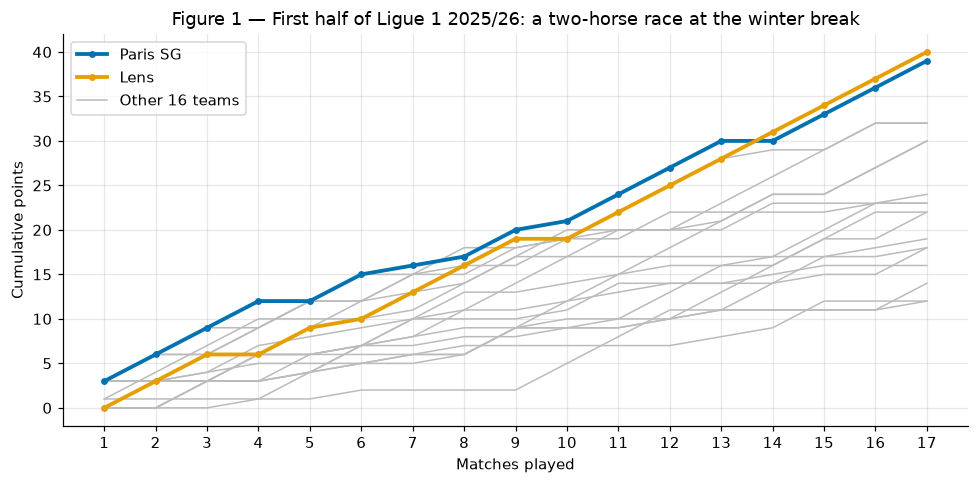

In [5]:
# Cumulative points over the first half: the two leaders against the rest of the league
long = pd.concat([
    pd.DataFrame({"team": played.home, "date": played.date, "pts": 3 * (played.hg > played.ag) + (played.hg == played.ag)}),
    pd.DataFrame({"team": played.away, "date": played.date, "pts": 3 * (played.ag > played.hg) + (played.hg == played.ag)}),
]).sort_values("date", kind="stable")
long["cum"] = long.groupby("team")["pts"].cumsum()
long["game"] = long.groupby("team").cumcount() + 1

fig, ax = plt.subplots(figsize=(9, 4.5))
for team, g in long.groupby("team"):
    if team in ("Paris SG", "Lens"):
        continue
    ax.plot(g.game, g.cum, color=COL["other"], lw=1)
for team, key in (("Paris SG", "psg"), ("Lens", "lens")):
    g = long[long.team == team]
    ax.plot(g.game, g.cum, color=COL[key], lw=2.5, marker="o", ms=3.5, label=team)
ax.plot([], [], color=COL["other"], lw=1, label="Other 16 teams")
ax.set(xlabel="Matches played", ylabel="Cumulative points", xticks=range(1, 18),
       title="Figure 1 — First half of Ligue 1 2025/26: a two-horse race at the winter break")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 1.3 — From a vague question to precise ones

"Who will be champion?" has no answer at the winter break; "*what is the probability that Paris SG becomes champion?*" does, **once we specify a probabilistic model of the remaining matches**. The investigation is organised around five precise questions:

- **Q1 — Model.** Which model of the remaining matches do the data support, and how much does that choice move the answer?
- **Q2 — Precision.** How many simulated seasons are needed to estimate the title probabilities within a guaranteed margin?
- **Q3 — Correctness.** Can we verify that the simulator computes what we think, against an exact computation?
- **Q4 — Relevance of the precision.** Is the simulation error the uncertainty that matters, or does the model contribute much more?
- **Q5 — Limits.** When does plain Monte Carlo stop being informative, and what replaces it?

---
## 2 — Mathematical foundations

### 2.1 — The estimand: a probability is an expectation

Let $M = 153$ be the number of remaining matches. The end of the season is the random vector of scores

$$Z = \big((X_m, Y_m)\big)_{m=1}^{M} \in \mathbb{N}^{2M},$$

where $X_m$ and $Y_m$ are the goals of the home and away teams in match $m$. Its distribution $P_\theta$ is given by a model with parameter $\theta$ (Section 2.6). Given the points already earned, $Z$ determines the final table up to rare exact ties, which we break with independent uniform draws (Section 3.3); we include these draws in $Z$, so that $Z$ determines the final table, hence the event

$$C = \{\text{Paris SG finishes first}\}.$$

The quantity we want is

$$\boxed{\;p(\theta) = P_\theta(C) = \mathbb{E}_\theta\big[\mathbf{1}_C(Z)\big]\;}$$

**A probability is the expectation of an indicator.** This trivial identity is the bridge to Monte Carlo: any method that estimates expectations estimates probabilities.

**Why not compute $p(\theta)$ exactly?** It is a sum over all possible ends of season. Even ignoring scores and keeping only win/draw/loss, there are $3^{153} \approx 10^{73}$ outcomes, more than the number of atoms on Earth (about $10^{50}$). Scores matter too (goal difference breaks ties), so the actual sum runs over $\mathbb{N}^{306}$. Exhaustive enumeration and deterministic quadrature are hopeless.

### 2.2 — The Monte Carlo estimator

**Definition.** Draw $N$ independent ends of season $Z_1, \dots, Z_N \sim P_\theta$ and set

$$\hat p_N = \frac{1}{N} \sum_{i=1}^{N} \mathbf{1}_C(Z_i).$$

With the course notation, $\hat p_N = \overline{B}_N$ is the sample mean of the i.i.d. Bernoulli variables $B_i = \mathbf{1}_C(Z_i) \sim \mathrm{Bernoulli}(p)$.

> **Notation.** As in the lecture notes, we distinguish the **size $n$ of the data sample** (here $n = 153$ matches of the current season, used to fit the model) from the **number $N$ of repetitions** of a random experiment (here simulated seasons). $N$ is chosen by us and is only limited by computing time.

**Proposition 1.** $\mathbb{E}[\hat p_N] = p$ and $\operatorname{Var}[\hat p_N] = \dfrac{p(1-p)}{N}$. Consequently $\hat p_N \xrightarrow[N\to\infty]{\mathbb{P}} p$.

*Proof.* By linearity, $\mathbb{E}[\hat p_N] = \frac1N \sum_i \mathbb{E}[B_i] = p$. By independence, variances add: $\operatorname{Var}[\hat p_N] = \frac{1}{N^2} \sum_i \operatorname{Var}[B_i] = \frac{p(1-p)}{N}$. Convergence in probability follows from Chebyshev's inequality for sample means (Corollary 3 of the lecture notes): $P(|\hat p_N - p| \ge \varepsilon) \le \frac{p(1-p)}{N\varepsilon^2} \to 0$. $\square$

**Interpretation.**
- *Unbiased*: on average over repeated simulations, the estimator is right; all the error is **variance**.
- *Standard error* $\sqrt{p(1-p)/N}$: it decreases as $1/\sqrt N$, **whatever the dimension of $Z$** (here 306). This is the decisive advantage of Monte Carlo over grid-based integration, whose error deteriorates with the dimension.
- *Cost of precision*: dividing the error by 10 requires **100 times** more simulations.
- *Worst case*: $p(1-p) \le 1/4$, with equality at $p = 1/2$. A tight title race is the hardest case for Monte Carlo.

### 2.3 — How many simulations? Three confidence radii

A confidence radius $r_N(\delta)$ satisfies $P\big(|\hat p_N - p| \le r_N(\delta)\big) \ge 1 - \delta$. Chapter 1 of the course provides the first two; the third comes from the central limit theorem.

**Chebyshev (distribution-free, non-asymptotic).** Using $p(1-p) \le 1/4$ in Proposition 1,
$P(|\hat p_N - p| \ge \varepsilon) \le \frac{1}{4N\varepsilon^2}$. Setting the bound equal to $\delta$ gives

$$r^{\mathrm{Cheb}}_N(\delta) = \frac{1}{2\sqrt{N\delta}}.$$

**Hoeffding (bounded variables, non-asymptotic).** The $B_i$ take values in $[0, 1]$, so Hoeffding's inequality (lecture notes, §1.3) gives $P(|\hat p_N - p| \ge \varepsilon) \le 2 e^{-2N\varepsilon^2}$, hence

$$r^{\mathrm{Hoeff}}_N(\delta) = \sqrt{\frac{\log(2/\delta)}{2N}}.$$

**Central limit theorem (asymptotic).** $\sqrt{N}(\hat p_N - p)/\sqrt{p(1-p)} \xrightarrow{d} \mathcal{N}(0,1)$, which suggests the (Wald) radius

$$r^{\mathrm{CLT}}_N(\delta) = z_{1-\delta/2}\sqrt{\frac{\hat p_N(1-\hat p_N)}{N}}.$$

| | Assumption | Guarantee | What sets the width |
|---|---|---|---|
| Chebyshev | known variance bound (here $\operatorname{Var} \le 1/4$ for $[0,1]$-valued variables) | valid for every $N$ | $1/\sqrt{\delta}$: polynomial tail, grows fast as $\delta \to 0$ |
| Hoeffding | variables bounded in $[0, 1]$ | valid for every $N$ | $\sqrt{\log(2/\delta)/2}$: exponential tail $e^{-2N\varepsilon^2}$, grows slowly; ignores the variance |
| CLT | finite variance | only as $N \to \infty$ | $z_{1-\delta/2} \approx \sqrt{2\log(2/\delta)}$, same order as Hoeffding, **times** $\sqrt{\hat p_N(1-\hat p_N)}$: adapts to the variance |

All three shrink at the same $1/\sqrt N$ rate; they differ by constant factors. Hoeffding and the CLT have the same dependence on $\delta$; the CLT is narrower mainly because it uses the estimated variance $\hat p_N(1-\hat p_N) \le 1/4$ instead of the worst case — at the price of a guarantee that is only asymptotic.

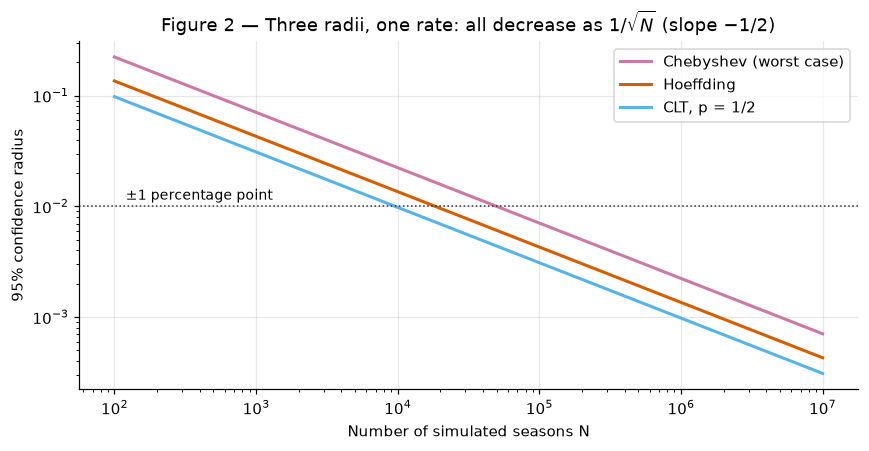

In [6]:
def radius_chebyshev(n, delta):
    """Distribution-free Chebyshev radius for a mean of [0, 1]-valued variables."""
    return 1 / (2 * np.sqrt(n * delta))


def radius_hoeffding(n, delta):
    """Hoeffding radius for a mean of [0, 1]-valued variables."""
    return np.sqrt(np.log(2 / delta) / (2 * n))


def radius_clt(n, delta, p_hat):
    """Asymptotic (Wald) radius from the central limit theorem, with the plug-in variance p_hat (1 - p_hat)."""
    return norm.ppf(1 - delta / 2) * np.sqrt(p_hat * (1 - p_hat) / n)


DELTA = 0.05
z = norm.ppf(1 - DELTA / 2)  # 1.96

n_grid = np.logspace(2, 7, 200)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.loglog(n_grid, radius_chebyshev(n_grid, DELTA), color=COL["cheb"], lw=2, label="Chebyshev (worst case)")
ax.loglog(n_grid, radius_hoeffding(n_grid, DELTA), color=COL["hoeff"], lw=2, label="Hoeffding")
ax.loglog(n_grid, radius_clt(n_grid, DELTA, 0.5), color=COL["clt"], lw=2, label="CLT, p = 1/2")
ax.axhline(0.01, color=COL["exact"], ls=":", lw=1)
ax.text(1.2e2, 0.0115, "±1 percentage point", fontsize=9)
ax.set(xlabel="Number of simulated seasons N", ylabel="95% confidence radius",
       title="Figure 2 — Three radii, one rate: all decrease as $1/\\sqrt{N}$ (slope −1/2)")
ax.legend()
plt.tight_layout()
plt.show()

#### What do we observe?

- On a log–log scale the three radii are **parallel lines of slope $-1/2$**: the rate $1/\sqrt N$ is intrinsic to Monte Carlo; the inequalities only change the constant.
- At every $N$ the ordering is the same: Chebyshev is the widest, then Hoeffding, then the CLT at $p = 1/2$. Each extra decimal of precision multiplies the cost by 100.

### 2.4 — Many probabilities at once: the union bound

The same simulations give the title probabilities of all $K = 18$ teams — the 18 rows of the table of Section 4.2, one per club, each with its own interval. Radii computed one team at a time do not guarantee that **all** intervals are simultaneously correct — the same issue as selecting one coin among many in §1.6 of the course.

**Proposition 2 (simultaneous radius).** With $r = \sqrt{\log(2K/\delta)/(2N)}$,
$P\big(\exists k \le K : |\hat p_{k,N} - p_k| > r\big) \le \delta$.

*Proof.* By Hoeffding, each event $\{|\hat p_{k,N} - p_k| > r\}$ has probability at most $2e^{-2Nr^2} = \delta/K$. The union bound $P(\cup_k A_k) \le \sum_k P(A_k)$ gives at most $K \cdot \delta/K = \delta$. $\square$

The price of simultaneity is mild: $\log(2/\delta)$ becomes $\log(2K/\delta)$, i.e. each radius is computed at level $\delta/K$ instead of $\delta$. The same correction applies to the Chebyshev and CLT radii.

### 2.5 — Choosing $N$ from a target precision

We fix $N$ **before** simulating, by inverting the radii: the smallest $N$ such that $r_N(\delta/K) \le \varepsilon$, for a target precision $\varepsilon$, confidence $1 - \delta = 95\%$, and either one team ($K = 1$) or the 18 teams simultaneously ($K = 18$). For the CLT we use the worst case $p = 1/2$.

In [7]:
def n_required(eps: float, delta: float, method: str) -> int:
    """Smallest N whose 95% radius (at level delta, worst case p = 1/2) is at most eps."""
    if method == "Chebyshev":
        return int(np.ceil(1 / (4 * delta * eps**2)))
    if method == "Hoeffding":
        return int(np.ceil(np.log(2 / delta) / (2 * eps**2)))
    return int(np.ceil(norm.ppf(1 - delta / 2) ** 2 / (4 * eps**2)))  # CLT with p (1 - p) = 1/4


METHODS = ("Chebyshev", "Hoeffding", "CLT (p = 1/2)")
n_table = pd.DataFrame(
    {(f"K = {k}", meth): {eps: n_required(eps, DELTA / k, meth) for eps in (0.01, 0.005, 0.001)}
     for k in (1, T) for meth in METHODS}
).rename_axis("precision ε")
print("Number of simulated seasons N needed for |p̂ − p| ≤ ε with probability ≥ 95% (K = number of simultaneous estimates)")
display(n_table)

EPS_TARGET = 0.005  # ±0.5 percentage point
N_HOEFF_SIMUL = n_required(EPS_TARGET, DELTA / T, "Hoeffding")
N_MAIN = int(np.ceil(N_HOEFF_SIMUL / 50_000) * 50_000)  # rounded up to a multiple of 50 000
r_single, r_simul = radius_hoeffding(N_MAIN, DELTA), radius_hoeffding(N_MAIN, DELTA / T)
print(f"Hoeffding, K = {T}, ε = {EPS_TARGET}: N ≥ {N_HOEFF_SIMUL:,} → N_MAIN = {N_MAIN:,}")
print(f"Guaranteed 95% radius with N_MAIN: ±{r_single:.4f} for one team, ±{r_simul:.4f} for all {T} teams at once")
print(f"Cost of the same guarantee (ε = {EPS_TARGET}, K = {T}): Chebyshev / Hoeffding = "
      f"{n_table.loc[EPS_TARGET, (f'K = {T}', 'Chebyshev')] / N_HOEFF_SIMUL:.0f}")

Number of simulated seasons N needed for |p̂ − p| ≤ ε with probability ≥ 95% (K = number of simultaneous estimates)


K = 1                            K = 18            \
            Chebyshev Hoeffding CLT (p = 1/2) Chebyshev Hoeffding   
precision ε                                                         
0.0100          50000     18445          9604    900000     32897   
0.0050         200000     73778         38415   3600000    131586   
0.0010        5000000   1844440        960365  90000000   3289626   

                           
            CLT (p = 1/2)  
precision ε                
0.0100              22370  
0.0050              89480  
0.0010            2236994

Hoeffding, K = 18, ε = 0.005: N ≥ 131,586 → N_MAIN = 150,000
Guaranteed 95% radius with N_MAIN: ±0.0035 for one team, ±0.0047 for all 18 teams at once
Cost of the same guarantee (ε = 0.005, K = 18): Chebyshev / Hoeffding = 27


#### Interpretation — why $N = 150\,000$, and why Hoeffding

- **The target.** We want each of the 18 title probabilities of Section 4.2 to be reported within $\pm 0.5$ percentage point, **all at once**, with probability at least 95%. Hoeffding with the union bound ($K = 18$) requires $N \ge 131\,586$; we round up to $N = 150\,000$, which guarantees $\pm 0.35$ point for one team and $\pm 0.47$ point for the 18 teams simultaneously.
- **Why Hoeffding rather than Chebyshev?** Both are theorems valid for every $N$, so the choice is not about trust but about width. Chebyshev uses only the variance (a polynomial tail, in $1/(N\varepsilon^2)$); Hoeffding also uses the boundedness of the indicators in $[0, 1]$ (an exponential tail, $e^{-2N\varepsilon^2}$). The same guarantee costs **27 times** fewer simulations with Hoeffding ($131\,586$ instead of $3\,600\,000$), and the gap widens with $K$: Chebyshev pays a factor $K$ where Hoeffding pays $\log K$. Chebyshev's extra width buys no extra confidence — its observed coverage is 100% against a nominal 95% (Section 4.1). Computing cost is not the real argument (150 000 seasons take a few seconds); a wider interval is simply a less informative statement for the same guarantee.
- **Why not the CLT?** It is sharper ($N = 89\,480$ would do) but only asymptotic, and Section 4.1 shows it failing badly when $Np \approx 1$ (coverage 59%) — exactly the regime of the outsiders in the table of Section 4.2.
- **What $N$ is *not* set by.** This $N$ is fixed by the **reporting precision** we want for the 18 probabilities, not by the total uncertainty of the answer. Section 4.3 shows that the parameter uncertainty dominates the Monte Carlo error as soon as $N$ exceeds a few thousand seasons (the "elbow" of Proposition 3, Section 2.7): beyond that point, a larger $N$ makes the reported digits reproducible, not the answer more accurate.

### 2.6 — The input model: a family of nested Poisson models

Monte Carlo needs a way to **sample** $Z$. The sampler is a statistical model of scores, and its complexity must be justified by the data, not by taste. We start from the classical model of Maher (1982),

$$X_m \sim \mathrm{Poisson}(\lambda_m), \quad Y_m \sim \mathrm{Poisson}(\nu_m), \quad \text{all independent}, \qquad \log \lambda_m = \mu + h + a_{i} - d_{j}, \quad \log \nu_m = \mu + a_{j} - d_{i},$$

for match $m$ between home team $i$ and away team $j$: $\mu$ sets the average scoring rate, $h$ is the home advantage, $a_i$ the attack strength of team $i$ and $d_i$ its defence strength. A value $a_i = 0.3$ means that team $i$ scores $e^{0.3} \approx 1.35$ times more than an average team against the same opponent. We compare it with its nested simplifications:

| Model | $\log \lambda_m$ (home) | $\log \nu_m$ (away) | Free parameters |
|---|---|---|---|
| M0 — league average | $\mu$ | $\mu$ | 1 |
| M1 — home advantage | $\mu + h$ | $\mu$ | 2 |
| M2 — defence only | $\mu + h - d_j$ | $\mu - d_i$ | 2 + 17 = 19 |
| M3 — attack only | $\mu + h + a_i$ | $\mu + a_j$ | 2 + 17 = 19 |
| M4 — attack and defence | $\mu + h + a_i - d_j$ | $\mu + a_j - d_i$ | 2 + 17 + 17 = 36 |

- **Why Poisson?** Goals are rare events in many short time intervals; the Poisson law is the limit of such binomial counts.
- **Identifiability.** Adding a constant to all $a_i$ and all $d_i$ leaves every rate unchanged, and so does adding a constant to $\mu$ while subtracting it from all $a_i$. We impose $\sum_i a_i = \sum_i d_i = 0$, which leaves 17 free parameters per block.
- **Estimation.** $\theta$ is fitted by maximum likelihood. The log-likelihood $\ell(\theta) = \sum_m \big(X_m \log\lambda_m - \lambda_m - \log X_m!\big) + \big(Y_m\log\nu_m - \nu_m - \log Y_m!\big)$ is concave in $\theta$ (linear minus exponential of linear functions), so any local maximum found by a numerical optimiser is global; it is unique once the centring constraints remove the flat directions (existence requires every team to have scored and conceded at least once, which holds here).
- **Bias–variance.** M4 estimates 36 parameters from 306 scores (153 matches): about 8.5 observations per parameter. A richer model has less bias but noisier estimates; whether it predicts better is an empirical question.

**How we compare models.**
- *In-sample criteria.* The maximised log-likelihood $\ell(\hat\theta)$ always increases with the number $k$ of parameters, so it must be penalised. $\mathrm{AIC} = 2k - 2\ell(\hat\theta)$ (Akaike, 1974) estimates the out-of-sample predictive loss; $\mathrm{BIC} = k \log n_{\mathrm{obs}} - 2\ell(\hat\theta)$ (Schwarz, 1978) approximates the log marginal likelihood and penalises more heavily ($\log 306 \approx 5.7$ instead of $2$ per parameter). Lower is better for both.
- *Likelihood-ratio test* (Wilks, 1938). For nested models, if the smaller one is true, $2\big(\ell_{\text{big}} - \ell_{\text{small}}\big) \xrightarrow{d} \chi^2(\mathrm{df})$, with df the difference in free parameters. The result is asymptotic, hence only approximate with 8.5 observations per parameter.
- *Out-of-sample log-score.* A model is scored on matches it has not seen by $\log \hat P(X = x, Y = y)$, the log-probability it gave to the exact scoreline that occurred (higher is better). It is a strictly proper scoring rule (Gneiting & Raftery, 2007), finer than the Brier score of win/draw/loss forecasts, which we also report. Two models are compared on the **same** matches: the mean of the paired per-match differences has a CLT confidence interval (clustered by season when several seasons are pooled).

**Using past seasons.** The current season alone gives 17 matches per team. Ligue 1 history provides more: a match played $\alpha$ seasons ago receives the weight $w = \rho^{\alpha}$, $\rho \in [0, 1]$, and the fit maximises the **weighted** log-likelihood $\sum_m w_m\,\ell_m(\theta)$. One interpretable parameter: a match from last season counts as $\rho$ matches of the current season; $\rho = 0$ is the within-season model, $\rho = 1$ assumes that team strengths never change. Design choices:
- *Matches, not titles.* Paris SG won 11 of the 13 titles before 2025/26, but this information is already contained in the matches of those seasons, at a finer resolution (every goal, every team — including Lens). Adding titles would count it twice.
- *How far back?* The 10 previous seasons. For $\rho \le 0.6$ a match from 10 seasons ago weighs at most $0.6^{10} \approx 0.006$; only values of $\rho$ close to 1 depend on this horizon.
- *Information.* We report the weighted number of matches $\sum_m w_m$ and Kish's effective sample size $(\sum_m w_m)^2 / \sum_m w_m^2$.
- *Clubs with little or no Ligue 1 history* are handled automatically by the weighted likelihood: Paris FC, absent from Ligue 1 during the whole window, relies on its 17 current-season matches only.

**Decision rule (fixed before looking at the results).** The structure (M0–M4) and the memory $\rho$ are chosen **jointly by a backtest on the 10 previous seasons** (2015/16 to 2024/25): for each of them, every candidate is fitted on the first half of that season (plus its own history) and scored on its second half. A richer model is retained only if it beats the simpler ones out of sample; otherwise we fall back to the best simpler one. The 2025/26 second half is a **final check, never used to choose** — we know that Paris SG won, and choosing the model because it makes the answer "look right" would be fitting the model to the outcome.

**What we leave out** (discussed in Section 5): dependence between the two scores (Dixon & Coles, 1997), external information such as betting odds or expected goals, injuries and transfers. Strengths that drift during the season are tested in Section 4.7.

### 2.7 — Two sources of uncertainty

In practice $\theta$ is unknown: we plug in its estimate $\hat\theta$. Monte Carlo then estimates $p(\hat\theta)$, **not** $p(\theta)$. The estimator $\hat p_N$ is random for two reasons: the simulated seasons, and the data that produced $\hat\theta$.

**Proposition 3 (law of total variance).**
$$\operatorname{Var}[\hat p_N] = \underbrace{\mathbb{E}\Big[\frac{p(\hat\theta)\,(1 - p(\hat\theta))}{N}\Big]}_{\text{Monte Carlo error}} + \underbrace{\operatorname{Var}\big[p(\hat\theta)\big]}_{\text{parameter uncertainty}}.$$

*Proof.* For any random variables, $\operatorname{Var}[U] = \mathbb{E}[\operatorname{Var}(U \mid V)] + \operatorname{Var}[\mathbb{E}(U \mid V)]$. With $U = \hat p_N$ and $V = \hat\theta$, Proposition 1 applied conditionally on $\hat\theta$ gives $\mathbb{E}[\hat p_N \mid \hat\theta] = p(\hat\theta)$ and $\operatorname{Var}(\hat p_N \mid \hat\theta) = p(\hat\theta)(1 - p(\hat\theta))/N$. $\square$

**Interpretation.** The first term vanishes as $N \to \infty$; the second **does not depend on $N$ at all**. Writing $\operatorname{Var}[\hat p_N] = A/N + V$, more simulations only shrink $A/N$: beyond the "elbow" $N \approx A/V$, they buy no real precision. Only more information about $\theta$ — more data — reduces $V$. Measuring $V$ (Section 4.3) answers Q4.

### 2.8 — When independent draws are impossible: Markov chain Monte Carlo

Everything so far uses **independent** draws: the simulator samples $Z$ directly from $P_\theta$. For the parameter side of the problem (Section 4.8) we will want to sample $\theta$ itself from a Bayesian posterior

$$\pi(\theta) = \pi(\theta \mid \text{data}) = \frac{L(\theta)\,\pi_0(\theta)}{\int L(\vartheta)\,\pi_0(\vartheta)\,d\vartheta},$$

whose normalising constant is an integral in 38 dimensions. Metropolis, Rosenbluth, Rosenbluth, Teller and Teller (1953), generalised by Hastings (1970), showed how to build a **Markov chain** whose long-run distribution is $\pi$, using only ratios $\pi(\theta')/\pi(\theta)$ — in which the unknown constant cancels.

**Random-walk Metropolis.** From the current state $\theta_t$, propose $\theta' = \theta_t + s\,L\,\xi$ with $\xi \sim \mathcal N(0, I)$ (a symmetric proposal), and set $\theta_{t+1} = \theta'$ with probability $\alpha(\theta_t, \theta') = \min\big(1, \pi(\theta')/\pi(\theta_t)\big)$, otherwise $\theta_{t+1} = \theta_t$.

**Proposition 4 ($\pi$ is stationary).** If $\theta_t \sim \pi$, then $\theta_{t+1} \sim \pi$.

*Proof.* Let $q$ be the (symmetric) proposal density. For $\theta \ne \theta'$ the chain moves with density $K(\theta, \theta') = q(\theta' \mid \theta)\,\alpha(\theta, \theta')$, and
$\pi(\theta)\,q(\theta' \mid \theta) \min\big(1, \tfrac{\pi(\theta')}{\pi(\theta)}\big) = q(\theta' \mid \theta)\min\big(\pi(\theta), \pi(\theta')\big)$
is symmetric in $(\theta, \theta')$: this is **detailed balance**, $\pi(\theta)K(\theta, \theta') = \pi(\theta')K(\theta', \theta)$. For any set $A$, the mass that flows from $A$ to its complement therefore equals the mass that flows back, and rejected proposals stay where they are; hence $P(\theta_{t+1} \in A) = \pi(A)$. $\square$

Convergence to $\pi$ from any starting point (ergodicity) requires further conditions — irreducibility and aperiodicity — which hold for a Gaussian random walk on a positive continuous target; we use them without proof.

**The price: correlated draws.** Successive states are dependent. For $S$ draws of a quantity $f(\theta_t)$ with lag-$k$ autocorrelations $\rho_k$, the variance of their average is approximately $\operatorname{Var}[f]/\mathrm{ESS}$, with the **effective sample size**

$$\boxed{\;\mathrm{ESS} = \frac{S}{1 + 2\sum_{k \ge 1}\rho_k}\;}$$

**Link with Chapter 1.** The Chebyshev, Hoeffding and CLT radii of Section 2.3 all assume **independent** variables. For a Markov chain, a radius computed with $S$ instead of $\mathrm{ESS}$ is too narrow by the factor $\sqrt{S/\mathrm{ESS}}$; Section 4.8 shows the resulting loss of coverage.

**Tuning and diagnostics.** With too small a step $s$ almost every proposal is accepted but the chain crawls; with too large a step almost all are rejected. For targets close to Gaussian in dimension $d$, the optimal acceptance rate is about $0.234$ (Roberts, Gelman & Gilks, 1997), reached with $s \approx 2.38/\sqrt d$ when $L$ is the Cholesky factor of the target covariance — which we approximate by the Gaussian (Laplace) approximation at the posterior mode. Convergence is checked with several chains started from dispersed points: trace plots, autocorrelations, and the potential scale reduction $\hat R$ (Gelman & Rubin, 1992), which compares the between-chain and within-chain variances and is close to $1$ when the chains agree.

---
## 3 — Implementation

### 3.1 — Fitting a model by maximum likelihood

The negative log-likelihood and its gradient are written explicitly. The derivative with respect to each linear predictor $\eta = \log\lambda$ is simply $\lambda - X$ (expected minus observed goals), which makes the gradient a sum of residuals. A switch selects the structure (M0–M4), optional weights implement the use of past seasons, and an optional Gaussian penalty on the strengths gives the shrinkage variant of Section 3.2 (and the posterior mode of Section 4.8). We first fit the full model M4 on the 153 first-half matches only.

In [8]:
@dataclass(frozen=True)
class PoissonModel:
    """Independent Poisson goal model; attack and defence strengths are centred (identifiability)."""

    mu: float
    home: float
    att: np.ndarray
    dfn: np.ndarray

    def rates(self, h: np.ndarray, a: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """Expected goals of the home and away teams for matches (h[m] at home against a[m])."""
        lam_h = np.exp(self.mu + self.home + self.att[h] - self.dfn[a])
        lam_a = np.exp(self.mu + self.att[a] - self.dfn[h])
        return lam_h, lam_a


# Nested structures: which blocks are free (home advantage, attack strengths, defence strengths)
STRUCTURES = {"M0": (False, False, False), "M1": (True, False, False), "M2": (True, False, True),
              "M3": (True, True, False), "M4": (True, True, True)}


def n_params(structure: str, n_teams: int = T) -> int:
    """Number of free parameters: mu, h, and n_teams - 1 strengths per block (centring constraint)."""
    use_home, use_att, use_dfn = STRUCTURES[structure]
    return 1 + use_home + (n_teams - 1) * (use_att + use_dfn)


def fit_poisson_model(h, a, hg, ag, n_teams: int = T, weights=None, structure: str = "M4", prior_sd=None) -> PoissonModel:
    """(Weighted) maximum-likelihood fit by L-BFGS with the analytic gradient, then centring of the strengths.

    Blocks switched off by `structure` stay at 0. With `prior_sd`, the strengths get the penalty
    sum(s ** 2) / (2 prior_sd ** 2): the fit is then the posterior mode under a N(0, prior_sd ** 2) prior (ridge).
    """
    use_home, use_att, use_dfn = STRUCTURES[structure]
    free = np.r_[True, use_home, np.full(n_teams, use_att), np.full(n_teams, use_dfn)]
    w = np.ones(len(h)) if weights is None else np.asarray(weights, dtype=float)

    def neg_log_lik(q):
        p = np.zeros(free.size)
        p[free] = q
        mu, home, att, dfn = p[0], p[1], p[2:2 + n_teams], p[2 + n_teams:]
        eta_h = mu + home + att[h] - dfn[a]
        eta_a = mu + att[a] - dfn[h]
        lam_h, lam_a = np.exp(eta_h), np.exp(eta_a)
        value = np.sum(w * (lam_h - hg * eta_h)) + np.sum(w * (lam_a - ag * eta_a))  # constant log(x!) terms dropped
        r_h, r_a = w * (lam_h - hg), w * (lam_a - ag)  # derivatives with respect to the linear predictors
        grad = np.empty_like(p)
        grad[0] = r_h.sum() + r_a.sum()
        grad[1] = r_h.sum()
        grad[2:2 + n_teams] = np.bincount(h, weights=r_h, minlength=n_teams) + np.bincount(a, weights=r_a, minlength=n_teams)
        grad[2 + n_teams:] = -np.bincount(a, weights=r_h, minlength=n_teams) - np.bincount(h, weights=r_a, minlength=n_teams)
        if prior_sd is not None:
            value += 0.5 * np.sum(p[2:] ** 2) / prior_sd**2
            grad[2:] += p[2:] / prior_sd**2
        return value, grad[free]

    res = minimize(neg_log_lik, np.zeros(free.sum()), jac=True, method="L-BFGS-B",
                   options={"maxiter": 5000, "gtol": 1e-8})
    if not res.success:
        raise RuntimeError(f"MLE did not converge: {res.message}")
    p = np.zeros(free.size)
    p[free] = res.x
    att, dfn = p[2:2 + n_teams], p[2 + n_teams:]
    # Centring leaves every rate unchanged: mu absorbs the means
    return PoissonModel(mu=p[0] + att.mean() - dfn.mean(), home=p[1], att=att - att.mean(), dfn=dfn - dfn.mean())


def match_log_lik(model: PoissonModel, h, a, hg, ag) -> np.ndarray:
    """Log-probability of each observed scoreline, log(x!) terms included (comparable across models)."""
    lam_h, lam_a = model.rates(h, a)
    return poisson.logpmf(hg, lam_h) + poisson.logpmf(ag, lam_a)


ph_, pa_, phg_, pag_ = (played[c].to_numpy() for c in ("h", "a", "hg", "ag"))
rh_, ra_, rhg_, rag_ = (remaining[c].to_numpy() for c in ("h", "a", "hg", "ag"))
model_ws = fit_poisson_model(ph_, pa_, phg_, pag_)  # M4 on the 2025/26 first half only ("within season")

lam_h_fit, lam_a_fit = model_ws.rates(ph_, pa_)
print(f"Home advantage: exp(h) = {np.exp(model_ws.home):.3f}  (home teams score {100 * (np.exp(model_ws.home) - 1):.0f}% more)")
print(f"Goals per match — observed: {(played.hg + played.ag).mean():.3f} | fitted: {(lam_h_fit + lam_a_fit).mean():.3f}")
strengths = pd.DataFrame({"attack a": model_ws.att, "defence d": model_ws.dfn}, index=TEAMS).sort_values("attack a", ascending=False)
display(strengths.T)

Home advantage: exp(h) = 1.467  (home teams score 47% more)
Goals per match — observed: 2.837 | fitted: 2.837


,Paris SG,Marseille,Lille,Lens,Rennes,Monaco,Strasbourg,Lyon,Toulouse,Brest,Paris FC,Nice,Lorient,Metz,Angers,Nantes,Le Havre,Auxerre
attack a,0.4670,0.4102,0.3438,0.2789,0.2454,0.1629,0.1184,0.0822,0.0289,-0.0319,-0.0408,-0.1349,-0.1571,-0.1843,-0.2662,-0.3599,-0.4558,-0.5067
defence d,0.4293,0.2856,0.0001,0.5643,-0.0430,-0.2766,0.1267,0.3249,0.0489,-0.1522,-0.2533,-0.2501,-0.2379,-0.4819,0.1902,-0.1670,0.0327,-0.1408


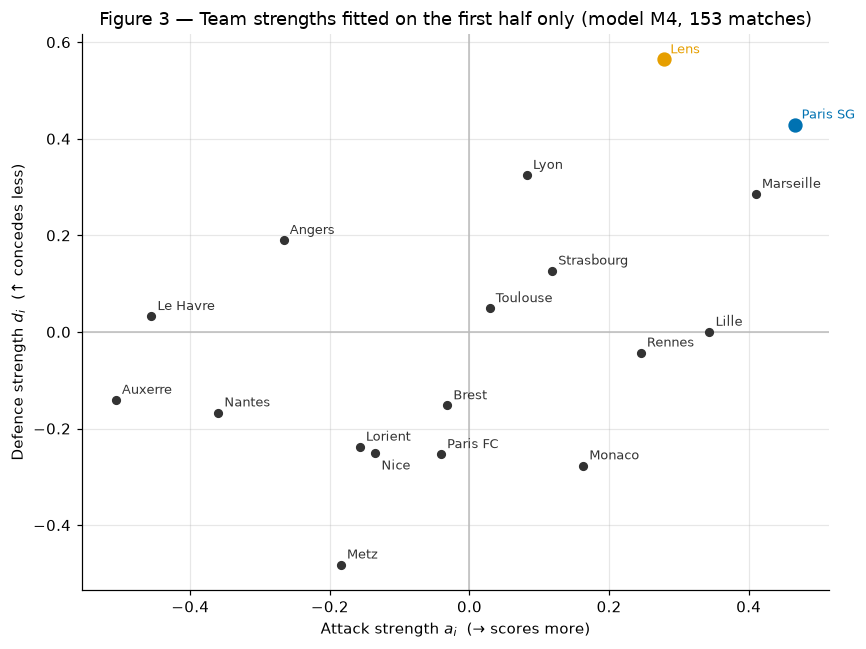

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for i, team in enumerate(TEAMS):
    color = COL["psg"] if i == PSG else COL["lens"] if i == LENS else COL["exact"]
    ax.scatter(model_ws.att[i], model_ws.dfn[i], color=color, s=70 if i in (PSG, LENS) else 25, zorder=3)
    offset = (4, -11) if team == "Nice" else (4, 4)  # avoid overlapping labels
    ax.annotate(team, (model_ws.att[i], model_ws.dfn[i]), xytext=offset, textcoords="offset points", fontsize=8.5, color=color)
ax.axhline(0, color=COL["other"], lw=1)
ax.axvline(0, color=COL["other"], lw=1)
ax.set(xlabel="Attack strength $a_i$  (→ scores more)", ylabel="Defence strength $d_i$  (↑ concedes less)",
       title="Figure 3 — Team strengths fitted on the first half only (model M4, 153 matches)")
plt.tight_layout()
plt.show()

In [10]:
# Over-dispersion check: under the Poisson model, the Pearson statistic sum((x - lambda)^2 / lambda)
# is close to its degrees of freedom (observations minus fitted parameters)
x_obs = np.concatenate([played.hg, played.ag]).astype(float)
lam_fit = np.concatenate([lam_h_fit, lam_a_fit])
dof = x_obs.size - n_params("M4")
dispersion = np.sum((x_obs - lam_fit) ** 2 / lam_fit) / dof
print(f"Pearson dispersion = {dispersion:.3f} (about 1 under Poisson; rough 95% band ±{1.96 * np.sqrt(2 / dof):.2f}) "
      f"| goals per team and match: mean {x_obs.mean():.2f}, variance {x_obs.var(ddof=1):.2f}")

Pearson dispersion = 1.106 (about 1 under Poisson; rough 95% band ±0.17) | goals per team and match: mean 1.42, variance 1.79


#### What do we observe?

- **The fit reproduces the scoring level exactly** (2.837 goals per match, observed and fitted). This is not a coincidence: for a Poisson model with an intercept, the likelihood equation for $\mu$ forces the sum of fitted rates to equal the sum of observed goals.
- **No clear over-dispersion.** The Pearson statistic divided by its degrees of freedom is $1.11$ (about $1$ under a Poisson law, rough 95% band $\pm 0.17$): the goals are not more variable than the model says, at the precision allowed by 153 matches. (The raw variance of goals per team and match, $1.79$, exceeds their mean, $1.42$, mostly because teams and venues differ, which the model accounts for.)
- **Home advantage is substantial**: $e^{h} \approx 1.47$, i.e. a team scores about 47% more at home than away against the same opponent.
- **Paris SG has the best attack** ($a = 0.47$: $e^{0.47} \approx 1.60$ times the average scoring rate) and the second-best defence; **Lens has the best defence by far** ($d = 0.56$: it concedes $e^{-0.56} \approx 0.57$ times the average) and the fourth-best attack.
- **The model ranks teams by goals, not by points.** Lens leads the table with 40 points, but Paris SG has the better goal difference (+22 against +18).

But are 36 parameters estimated from 153 matches trustworthy? The next section asks whether the data support this model at all.

### 3.2 — Do we need this model? Choosing the input with numbers

We apply the tools of Section 2.6 in two steps: first on the 2025/26 first half alone (in-sample criteria and likelihood-ratio tests), then out of sample on ten past seasons, where the structure and the use of history are chosen together.

In [11]:
n_obs = 2 * len(played)  # 306 scores
fits_ws, rows = {}, []
for s in STRUCTURES:
    m_ = fit_poisson_model(ph_, pa_, phg_, pag_, structure=s)
    fits_ws[s] = m_
    ll = match_log_lik(m_, ph_, pa_, phg_, pag_).sum()
    k = n_params(s)
    rows.append({"model": s, "free parameters k": k, "scores per parameter": n_obs / k, "log-likelihood": ll,
                 "AIC": 2 * k - 2 * ll, "BIC": k * np.log(n_obs) - 2 * ll})
comp_ws = pd.DataFrame(rows).set_index("model")
print("In-sample comparison on the 153 first-half matches (306 scores); lower AIC / BIC is better")
display(comp_ws)

rows = []
for small, big in (("M0", "M1"), ("M1", "M2"), ("M1", "M3"), ("M2", "M4"), ("M3", "M4")):
    stat = 2 * (comp_ws.loc[big, "log-likelihood"] - comp_ws.loc[small, "log-likelihood"])
    df_ = n_params(big) - n_params(small)
    rows.append({"test": f"{small} → {big}", "2 Δ log-likelihood": stat, "df": df_, "p-value (χ²)": chi2.sf(stat, df_)})
print("Likelihood-ratio tests for nested pairs")
display(pd.DataFrame(rows).set_index("test"))

# Final check only, never used to choose: log-score of each model on the 153 second-half matches of 2025/26
ls_25 = {s: match_log_lik(m_, rh_, ra_, rhg_, rag_) for s, m_ in fits_ws.items()}
print("2025/26 second half (final check): mean log-score per match, and paired difference with M4 (95%)")
for s in STRUCTURES:
    d_ = ls_25[s] - ls_25["M4"]
    print(f"  {s}: {ls_25[s].mean():.4f} | {s} − M4 = {d_.mean():+.4f} ± {z * d_.std(ddof=1) / np.sqrt(d_.size):.4f}")

In-sample comparison on the 153 first-half matches (306 scores); lower AIC / BIC is better


,free parameters k,scores per parameter,log-likelihood,AIC,BIC
model,,,,,
M0,1,306.0000,-483.2636,968.5272,972.2508
M1,2,153.0000,-476.2162,956.4323,963.8795
M2,19,16.1053,-461.0364,960.0728,1030.8209
M3,19,16.1053,-458.8905,955.7811,1026.5292
M4,36,8.5000,-444.4414,960.8827,1094.9318


Likelihood-ratio tests for nested pairs


,2 Δ log-likelihood,df,p-value (χ²)
test,,,
M0 → M1,14.0949,1,0.0002
M1 → M2,30.3595,17,0.0239
M1 → M3,34.6513,17,0.0069
M2 → M4,33.1901,17,0.0107
M3 → M4,28.8983,17,0.0355


2025/26 second half (final check): mean log-score per match, and paired difference with M4 (95%)
  M0: -3.1223 | M0 − M4 = -0.0089 ± 0.1048
  M1: -3.1363 | M1 − M4 = -0.0229 ± 0.1038
  M2: -3.1739 | M2 − M4 = -0.0605 ± 0.0758
  M3: -3.0668 | M3 − M4 = +0.0466 ± 0.0751
  M4: -3.1134 | M4 − M4 = +0.0000 ± 0.0000


#### What do we observe? (current season only)

- **In-sample, the evidence for the full model is weak.** The log-likelihood grows with every block of parameters, but the penalised criteria disagree with it: AIC prefers M3 (attack only, $955.8$), essentially tied with M1 ($956.4$) and ahead of M4 ($960.9$); BIC, which charges $\log 306 \approx 5.7$ per parameter, prefers M1 (home advantage only) and rejects the 36-parameter model by a wide margin.
- **The likelihood-ratio tests lean the other way, weakly.** Every step is significant at 5% (M3 → M4: $p = 0.035$). But the $\chi^2$ approximation relies on large samples — with 8.5 observations per parameter it is approximate — and the test answers "is the better fit more than chance?", not "does the model predict better?".
- **Final check on the second half (not used to choose).** On the 153 second-half matches, M3 scores best (log-score $-3.067$ against $-3.113$ for M4), but every difference lies within its 95% interval ($\pm 0.08$ to $\pm 0.10$): 153 matches cannot separate these models.
- **Applying the decision rule to the current season alone, M4 does not beat the simpler models:** we would fall back to M3, the best of them. The question is whether more data changes the verdict — the backtest below, where the structure and the use of history are chosen together.

In [12]:
def fit_with_history(season: int, current: pd.DataFrame, rho: float, structure: str = "M4", prior_sd=None) -> PoissonModel:
    """Weighted MLE: matches of `current` (weight 1) plus the K_HIST previous seasons (weight rho ** age)."""
    past = league[(league.season < season) & (league.season >= season - K_HIST)]
    data = pd.concat([current, past]) if rho > 0 else current
    weights = rho ** (season - data.season.to_numpy(float))  # 0 ** 0 = 1 for the current season
    return fit_poisson_model(data.hi.to_numpy(), data.ai.to_numpy(), data.hg.to_numpy(), data.ag.to_numpy(),
                             n_teams=len(ALL_TEAMS), weights=weights, structure=structure, prior_sd=prior_sd)


def restrict(full: PoissonModel, teams: list[str]) -> PoissonModel:
    """Same model restricted (and re-centred) to the given teams, indexed like `teams`."""
    ids = [ALL_IDX[t] for t in teams]
    att, dfn = full.att[ids], full.dfn[ids]
    return PoissonModel(mu=full.mu + att.mean() - dfn.mean(), home=full.home, att=att - att.mean(), dfn=dfn - dfn.mean())


def outcome_probs(lam_h: np.ndarray, lam_a: np.ndarray, gmax: int = 30):
    """Exact home-win / draw / away-win probabilities of independent Poisson scores (truncated at gmax goals)."""
    k = np.arange(gmax + 1)
    joint = poisson.pmf(k, lam_h[:, None])[:, :, None] * poisson.pmf(k, lam_a[:, None])[:, None, :]  # [m, x, y]
    p_home = np.tril(joint, -1).sum(axis=(1, 2))  # x > y
    p_draw = np.trace(joint, axis1=1, axis2=2)
    return p_home, p_draw, 1 - p_home - p_draw


def outcome_index(df: pd.DataFrame) -> np.ndarray:
    """0 = home win, 1 = draw, 2 = away win."""
    return np.select([df.hg > df.ag, df.hg == df.ag], [0, 1], 2)


def paired_ci(diff: np.ndarray, clusters: np.ndarray):
    """Mean of paired per-match differences and its 95% radius, with errors clustered by season."""
    ids = np.unique(clusters)
    sums = np.array([diff[clusters == c].sum() for c in ids])
    sizes = np.array([(clusters == c).sum() for c in ids])
    mean = sums.sum() / sizes.sum()
    se = np.sqrt(len(ids) / (len(ids) - 1) * np.sum((sums - sizes * mean) ** 2)) / sizes.sum()
    return mean, z * se


# Backtest: for each past season, fit every candidate on its first half (+ history) and score its second half
RHOS = np.round(np.linspace(0, 1, 11), 1)
TAUS = (0.1, 0.2, 0.3, 0.5)  # prior sd of the shrinkage (ridge) variant of M4, a comparison point only
CANDIDATES = [(s, rho, None) for s in STRUCTURES for rho in RHOS] + [("M4", rho, tau) for tau in TAUS for rho in RHOS]
ls_bt, brier_bt, bt_season = {c: [] for c in CANDIDATES}, {c: [] for c in CANDIDATES}, []
for season in range(2015, 2025):
    s_ = league[league.season == season].sort_values("date", kind="stable")
    split = s_.date.iloc[len(s_) // 2]
    first, second = s_[s_.date < split], s_[s_.date >= split]
    bt_season.append(np.full(len(second), season))
    args = (second.hi.to_numpy(), second.ai.to_numpy(), second.hg.to_numpy(), second.ag.to_numpy())
    o_bt = np.eye(3)[outcome_index(second)]
    for c in CANDIDATES:
        m_ = fit_with_history(season, first, rho=c[1], structure=c[0], prior_sd=c[2])
        ls_bt[c].append(match_log_lik(m_, *args))
        brier_bt[c].append(((np.column_stack(outcome_probs(*m_.rates(*args[:2]))) - o_bt) ** 2).sum(axis=1))
ls_bt = {c: np.concatenate(v) for c, v in ls_bt.items()}
brier_bt = {c: np.concatenate(v) for c, v in brier_bt.items()}
bt_season = np.concatenate(bt_season)
seasons_bt = np.unique(bt_season)
mean_ls = pd.Series({c: v.mean() for c, v in ls_bt.items()})

# Decision rule: the maximum-likelihood candidate (structure, rho) with the best out-of-sample log-score
STRUCTURE, RHO_STAR, _ = max((c for c in CANDIDATES if c[2] is None), key=lambda c: mean_ls[c])
BEST = (STRUCTURE, RHO_STAR, None)
print(f"Backtest on {bt_season.size:,} second-half matches of 2015/16–2024/25: mean log-score per match (higher is better)")
display(pd.DataFrame({s: {rho: mean_ls[(s, rho, None)] for rho in RHOS} for s in STRUCTURES}).T.rename_axis("model / ρ"))


def versus(c, ref):
    """Paired comparison of candidate c with candidate ref on the backtest matches."""
    d_mean, d_rad = paired_ci(ls_bt[c] - ls_bt[ref], bt_season)
    wins = sum(ls_bt[c][bt_season == s_].mean() > ls_bt[ref][bt_season == s_].mean() for s_ in seasons_bt)
    return {"Δ log-score": d_mean, "95% radius (by season)": d_rad, "significant": abs(d_mean) > d_rad,
            "seasons won": f"{wins}/{len(seasons_bt)}"}


best_rho = {s: max(RHOS, key=lambda r, s=s: mean_ls[(s, r, None)]) for s in STRUCTURES}
TAU_0 = max(TAUS, key=lambda t: mean_ls[("M4", 0.0, t)])  # best shrinkage without history
TAU_H = max(TAUS, key=lambda t: mean_ls[("M4", RHO_STAR, t)])  # best shrinkage with the selected memory
comparisons = {
    "M3 vs M4, within season (ρ = 0)": versus(("M3", 0.0, None), ("M4", 0.0, None)),
    "M1 vs M4, within season (ρ = 0)": versus(("M1", 0.0, None), ("M4", 0.0, None)),
    f"M4 with history (ρ = {RHO_STAR}) vs M4 within season": versus(BEST, ("M4", 0.0, None)),
    f"M4 (ρ = {RHO_STAR}) vs M3 (its best ρ = {best_rho['M3']})": versus(BEST, ("M3", best_rho["M3"], None)),
    f"M4 (ρ = {RHO_STAR}) vs M2 (its best ρ = {best_rho['M2']})": versus(BEST, ("M2", best_rho["M2"], None)),
    f"ridge τ = {TAU_0} vs M4, within season": versus(("M4", 0.0, TAU_0), ("M4", 0.0, None)),
    f"ridge τ = {TAU_H} + history vs M4 (ρ = {RHO_STAR})": versus(("M4", RHO_STAR, TAU_H), BEST),
}
display(pd.DataFrame(comparisons).T)
PLATEAU = np.array([rho for rho in RHOS if abs(paired_ci(ls_bt[(STRUCTURE, rho, None)] - ls_bt[BEST], bt_season)[0])
                    <= paired_ci(ls_bt[(STRUCTURE, rho, None)] - ls_bt[BEST], bt_season)[1]])
rho_brier = max(RHOS, key=lambda r: -brier_bt[(STRUCTURE, r, None)].mean())
print(f"Selected input: {STRUCTURE} with ρ* = {RHO_STAR} | values of ρ indistinguishable from ρ* (log-score): "
      f"{PLATEAU.min()} to {PLATEAU.max()} | best ρ by the coarser Brier score: {rho_brier}")

Backtest on 1,778 second-half matches of 2015/16–2024/25: mean log-score per match (higher is better)


,0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.0000
model / ρ,,,,,,,,,,,
M0,-3.0507,-3.0489,-3.0477,-3.0471,-3.0467,-3.0466,-3.0469,-3.0476,-3.0489,-3.0508,-3.0532
M1,-3.0363,-3.0335,-3.0320,-3.0312,-3.0309,-3.0309,-3.0314,-3.0323,-3.0340,-3.0365,-3.0395
M2,-3.0379,-3.0226,-3.0148,-3.0108,-3.0088,-3.0082,-3.0088,-3.0108,-3.0147,-3.0205,-3.0277
M3,-2.9648,-2.9486,-2.9402,-2.9354,-2.9325,-2.9309,-2.9304,-2.9317,-2.9350,-2.9411,-2.9495
M4,-2.9740,-2.9437,-2.9282,-2.9196,-2.9147,-2.9121,-2.9115,-2.9135,-2.9188,-2.9279,-2.9405


,Δ log-score,95% radius (by season),significant,seasons won
"M3 vs M4, within season (ρ = 0)",0.0092,0.0183,False,6/10
"M1 vs M4, within season (ρ = 0)",-0.0623,0.0282,True,1/10
M4 with history (ρ = 0.6) vs M4 within season,0.0624,0.0239,True,9/10
M4 (ρ = 0.6) vs M3 (its best ρ = 0.6),0.0189,0.0148,True,8/10
M4 (ρ = 0.6) vs M2 (its best ρ = 0.5),0.0967,0.0147,True,10/10
"ridge τ = 0.3 vs M4, within season",0.0450,0.0098,True,10/10
ridge τ = 0.3 + history vs M4 (ρ = 0.6),0.0048,0.0060,False,7/10


Selected input: M4 with ρ* = 0.6 | values of ρ indistinguishable from ρ* (log-score): 0.4 to 0.7 | best ρ by the coarser Brier score: 0.5


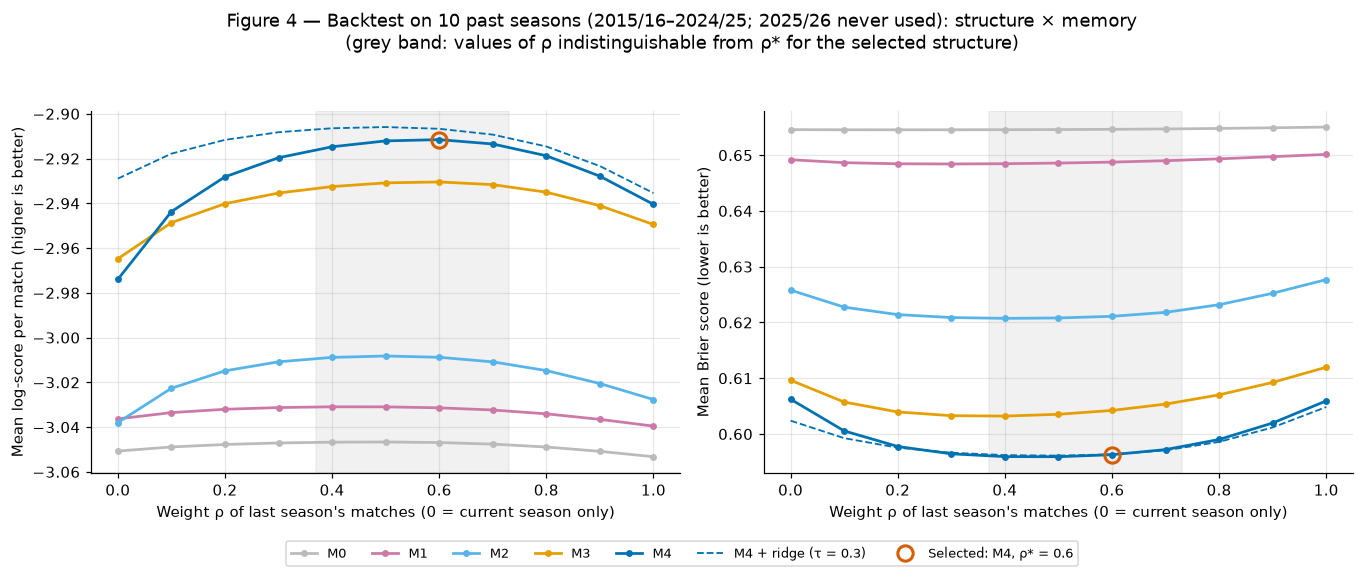

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
struct_col = {"M0": COL["other"], "M1": COL["cheb"], "M2": COL["clt"], "M3": COL["lens"], "M4": COL["psg"]}
for ax, score, label in ((axes[0], ls_bt, "Mean log-score per match (higher is better)"),
                         (axes[1], brier_bt, "Mean Brier score (lower is better)")):
    for s in STRUCTURES:
        ax.plot(RHOS, [score[(s, r, None)].mean() for r in RHOS], color=struct_col[s], marker="o", ms=3.5, lw=1.8, label=s)
    ax.plot(RHOS, [score[("M4", r, TAU_H)].mean() for r in RHOS], color=COL["psg"], ls="--", lw=1.2,
            label=f"M4 + ridge (τ = {TAU_H})")
    ax.plot(RHO_STAR, score[BEST].mean(), "o", color=COL["hoeff"], ms=10, mfc="none", mew=2,
            label=f"Selected: {STRUCTURE}, ρ* = {RHO_STAR}")
    ax.axvspan(PLATEAU.min() - 0.03, PLATEAU.max() + 0.03, color=COL["other"], alpha=0.2)
    ax.set(xlabel="Weight ρ of last season's matches (0 = current season only)", ylabel=label)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=7, fontsize=8.5, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Figure 4 — Backtest on 10 past seasons (2015/16–2024/25; 2025/26 never used): "
             "structure × memory\n(grey band: values of ρ indistinguishable from ρ* for the selected structure)", y=1.04)
plt.tight_layout()
plt.show()

In [14]:
# The selected input model, fitted on the 2025/26 first half plus its history
played_all = league[(league.season == 2025) & (league.date < CUTOFF)]
full_main = fit_with_history(2025, played_all, RHO_STAR, STRUCTURE)
model = restrict(full_main, TEAMS)

past_main = league[(league.season < 2025) & (league.season >= 2025 - K_HIST)]
data_main = pd.concat([played_all, past_main])
w_main = RHO_STAR ** (2025 - data_main.season.to_numpy(float))
hi_m, ai_m, hg_m, ag_m = (data_main[c].to_numpy() for c in ("hi", "ai", "hg", "ag"))
print(f"Weighted matches Σw = {w_main.sum():.0f} | Kish effective sample size (Σw)² / Σw² = "
      f"{w_main.sum() ** 2 / np.sum(w_main ** 2):.0f} (vs {len(played)} matches of the current season)")

# Over-dispersion check of the selected model (weighted Pearson statistic over all the data it was fitted on)
lam_hm, lam_am = full_main.rates(hi_m, ai_m)
pearson_w = np.sum(w_main * ((hg_m - lam_hm) ** 2 / lam_hm + (ag_m - lam_am) ** 2 / lam_am))
dispersion_main = pearson_w / (2 * w_main.sum() - n_params(STRUCTURE, len(ALL_TEAMS)))
print(f"Weighted Pearson dispersion of the selected model: {dispersion_main:.3f} (about 1 under Poisson)")
display(pd.DataFrame({"attack a (within season)": model_ws.att, "attack a (selected)": model.att,
                      "defence d (within season)": model_ws.dfn, "defence d (selected)": model.dfn},
                     index=TEAMS).loc[["Paris SG", "Lens", "Marseille", "Lille"]].T)

Weighted matches Σw = 644 | Kish effective sample size (Σw)² / Σw² = 1255 (vs 153 matches of the current season)
Weighted Pearson dispersion of the selected model: 1.023 (about 1 under Poisson)


,Paris SG,Lens,Marseille,Lille
attack a (within season),0.4670,0.2789,0.4102,0.3438
attack a (selected),0.5374,0.0657,0.2935,0.1393
defence d (within season),0.4293,0.5643,0.2856,0.0001
defence d (selected),0.3285,0.3129,0.1412,0.2024


#### What do we observe? (10 past seasons, 1 778 test matches)

- **Without history, the decision rule falls back to a simpler model.** At $\rho = 0$ (each past season fitted on its own first half), M3 does at least as well as M4 ($+0.009 \pm 0.018$ in log-score per match; better in 6 seasons out of 10): with 17 to 19 matches per team, the defence parameters add more noise than signal. Both are clearly better than the models without attack strengths (M1 is worse than M4 by $0.062 \pm 0.028$).
- **With history, the full model wins.** Every structure improves when past seasons are added, M4 most of all: at $\rho^* = 0.6$ it beats M3 at its own best memory by $0.019 \pm 0.015$ (8 seasons out of 10), M2 by $0.097 \pm 0.015$, and its own within-season version by $0.062 \pm 0.024$ (9 seasons out of 10). More data per parameter (644 weighted matches instead of 153; Kish's effective sample size 1 255) is what makes the defence parameters worth estimating — an interaction between structure and data that a single-season comparison cannot see.
- **The memory is pinned down to a range, not a value.** For M4, the paired, season-clustered comparison cannot distinguish $\rho^* = 0.6$ from $\rho \in [0.4, 0.7]$ (grey band); $\rho \le 0.3$ and $\rho \ge 0.8$ are significantly worse. The coarser Brier score (right panel) is flatter and points to $\rho = 0.5$: the log-score of the exact scoreline is the more informative criterion, as expected. Section 4.6 measures how much the answer depends on this residual freedom.
- **Shrinkage is a comparison point, not a replacement.** A ridge penalty ($\tau = 0.3$, i.e. a $\mathcal N(0, 0.3^2)$ prior on the strengths) helps a lot without history ($+0.045 \pm 0.010$ over the unpenalised M4, 10 seasons out of 10) but adds nothing significant once history is used ($+0.005 \pm 0.006$). We keep the simpler, unpenalised fit; the Bayesian version returns in Section 4.8.
- **Caveats.** Strengths drift between seasons (hence $\rho < 1$; drift within the season is tested in Section 4.7); 2019/20 was interrupted by Covid-19 in March 2020, so its "second half" has 140 matches; seasons up to 2022/23 had 20 teams; promoted clubs have little or no history (Paris FC none); the gains of the selected candidate are slightly optimistic, since it was selected on these same matches. Season 2025/26 was never used to choose the structure or $\rho$.

**The selected input** is therefore **M4 fitted on the 2025/26 first half plus ten past seasons, with weight $0.6^{\text{age}}$**. It is *supported* against its nested simplifications by the out-of-sample criterion fixed in advance — not "optimal" in any absolute sense. Its weighted Pearson dispersion ($1.02$) shows no over-dispersion. Compared with the within-season fit, it keeps Paris SG strong (attack $0.47 \to 0.54$, defence $0.43 \to 0.33$) but cuts Lens sharply (attack $0.28 \to 0.07$, defence $0.56 \to 0.31$): history pulls Lens's outstanding first half back towards its past level. **Answer to Q1 (first part).**

### 3.3 — A vectorised season simulator

From now on the simulator is fed with the selected model. A simulated season is produced in four steps:
1. draw the $2M$ scores of the remaining matches from their Poisson laws;
2. convert scores into points ($3$ / $1$ / $0$) and goal differences;
3. add them to the standings at the cutoff, using incidence matrices (one matrix product per season batch);
4. rank the teams with the Ligue 1 tie-breakers: **points, then overall goal difference**, then — as an approximation of the six remaining official criteria (head-to-head points, head-to-head goal difference, best attack, most wins, most away wins, fewest yellow and red cards) — a uniform random draw. The official 2025/26 order is: points, goal difference, head-to-head points, head-to-head goal difference, best attack, most wins, most away wins, fewest cards (1 point per yellow, 3 per red), then a draw ([Ligue 1](https://ligue1.com/fr/articles/l1_article_2830-en-cas-d-egalite-au-classement-modifications-des-criteres)).

All $N$ seasons of a batch are simulated at once with NumPy arrays of shape $(N, M)$, without any Python loop over seasons. An optional argument lets the strengths drift during the remaining season (Section 4.7); it is switched off everywhere else.

In [15]:
def team_steps(h: np.ndarray, a: np.ndarray):
    """Rank (0, 1, ...) of each match among the remaining matches of its home team and of its away team."""
    count = np.zeros(max(h.max(), a.max()) + 1, dtype=int)
    step_h, step_a = np.empty(h.size, dtype=int), np.empty(h.size, dtype=int)
    for m, (i, j) in enumerate(zip(h, a)):
        step_h[m], step_a[m] = count[i], count[j]
        count[i] += 1
        count[j] += 1
    return step_h, step_a


@dataclass(frozen=True)
class SeasonState:
    """What is known at a cutoff date: current points and goal difference, and the fixtures left to play."""

    base_pts: np.ndarray
    base_gd: np.ndarray
    h: np.ndarray
    a: np.ndarray
    step_h: np.ndarray
    step_a: np.ndarray

    @property
    def n_matches(self) -> int:
        return self.h.size


def season_state(cutoff: pd.Timestamp) -> SeasonState:
    """Standings before the cutoff and list of the matches played on or after it (in date order)."""
    table = league_table(matches[matches.date < cutoff]).reindex(TEAMS)
    future = matches[matches.date >= cutoff]
    h, a = future.h.to_numpy(), future.a.to_numpy()
    return SeasonState(table.Pts.to_numpy(float), table.GD.to_numpy(float), h, a, *team_steps(h, a))


def simulate_goals(model: PoissonModel, state: SeasonState, n: int, rng: np.random.Generator, drift_sd: float = 0.0):
    """Scores of the remaining matches for n independent seasons, arrays of shape (n, M).

    With drift_sd > 0, every attack and defence strength follows a Gaussian random walk with one step of
    standard deviation drift_sd per match of its team (Section 4.7).
    """
    lam_h, lam_a = model.rates(state.h, state.a)
    size = (n, state.n_matches)
    if drift_sd > 0:
        n_steps = int(max(state.step_h.max(), state.step_a.max())) + 1
        walk_att = np.cumsum(rng.normal(0, drift_sd, (n, T, n_steps)), axis=2)
        walk_dfn = np.cumsum(rng.normal(0, drift_sd, (n, T, n_steps)), axis=2)
        lam_h = lam_h * np.exp(walk_att[:, state.h, state.step_h] - walk_dfn[:, state.a, state.step_a])
        lam_a = lam_a * np.exp(walk_att[:, state.a, state.step_a] - walk_dfn[:, state.h, state.step_h])
    return rng.poisson(lam_h, size).astype(np.int8), rng.poisson(lam_a, size).astype(np.int8)


def points_and_gd(state: SeasonState, gh: np.ndarray, ga: np.ndarray):
    """Final points and goal difference (n, T): standings at the cutoff plus the simulated matches."""
    inc_h, inc_a = np.eye(T)[state.h], np.eye(T)[state.a]  # (M, T) incidence matrices
    pts = state.base_pts + (3.0 * (gh > ga) + (gh == ga)) @ inc_h + (3.0 * (ga > gh) + (gh == ga)) @ inc_a
    gd = state.base_gd + (gh.astype(float) - ga) @ (inc_h - inc_a)
    return pts, gd


def final_tables(state: SeasonState, gh: np.ndarray, ga: np.ndarray, u: np.ndarray):
    """Final points (n, T) and final positions (n, T; 0 = champion) from simulated scores and tie-break draws u."""
    pts, gd = points_and_gd(state, gh, ga)
    score = 1000.0 * pts + gd + 0.5 * u  # lexicographic: points, goal difference, random draw
    order = np.argsort(-score, axis=1)
    pos = np.empty_like(order)
    np.put_along_axis(pos, order, np.arange(T)[None, :], axis=1)
    return pts.astype(np.int16), pos.astype(np.int8)


def simulate_seasons(model: PoissonModel, state: SeasonState, n: int, rng: np.random.Generator,
                     batch: int = 50_000, drift_sd: float = 0.0):
    """Simulate n independent ends of season, by batches to bound memory; returns final points and positions."""
    pts_all, pos_all = [], []
    for start in range(0, n, batch):
        b = min(batch, n - start)
        gh, ga = simulate_goals(model, state, b, rng, drift_sd)
        pts, pos = final_tables(state, gh, ga, rng.random((b, T)))
        pts_all.append(pts)
        pos_all.append(pos)
    return np.concatenate(pts_all), np.concatenate(pos_all)


state = season_state(CUTOFF)
pts_mc, pos_mc = simulate_seasons(model, state, N_MAIN, make_rng(1))
title_mc = pos_mc == 0  # Bernoulli indicators 1_C(Z_i), one column per team
p_hat = title_mc.mean(axis=0)

print(f"N = {N_MAIN:,} simulated seasons of {state.n_matches} matches (N fixed in Section 2.5)")
print(f"P̂(Paris SG champion) = {p_hat[PSG]:.4f} | P̂(Lens champion) = {p_hat[LENS]:.4f}")

# Cost of the tie-break approximation: how often are the first two level on points AND goal difference?
pts_chk, gd_chk = points_and_gd(state, *simulate_goals(model, state, 50_000, make_rng(2)))
key = np.sort(1000 * pts_chk + gd_chk, axis=1)
tie_rate = np.mean(key[:, -1] == key[:, -2])
print(f"Title decided by the random draw (top two level on points and goal difference): {tie_rate:.2%} of seasons")

N = 150,000 simulated seasons of 153 matches (N fixed in Section 2.5)
P̂(Paris SG champion) = 0.8567 | P̂(Lens champion) = 0.1195


Title decided by the random draw (top two level on points and goal difference): 0.05% of seasons


### 3.4 — Exact validation: is the simulator right?

A simulator can be fast, plausible and wrong. Since the title probability itself cannot be computed exactly, we validate the simulator on related quantities that **can** be computed exactly.

**Check 1: the joint law of the final points of Paris SG and Lens.** Under the model, matches are independent. The points a team earns in one match take values in $\{0, 1, 3\}$ with probabilities

$$P(X > Y) = \sum_{x > y} \pi_\lambda(x)\,\pi_\nu(y), \qquad P(X = Y) = \sum_{x} \pi_\lambda(x)\,\pi_\nu(x),$$

where $\pi_\lambda$ is the Poisson probability mass function (sums truncated at 30 goals; the largest expected score is about 4, so the neglected mass is below $10^{-15}$). The law of a sum of independent variables is the **convolution** of their laws, so the distribution of a team's final points is computed exactly in $17$ convolutions. Paris SG and Lens are dependent only through their head-to-head match; conditioning on its three possible outcomes restores independence:

$$P(\text{PSG points} > \text{Lens points}) = \sum_{o \in \{\text{PSG win, draw, Lens win}\}} P(o)\; P\big(S_{\text{PSG}} + \Delta_{\text{PSG}}(o) > S_{\text{Lens}} + \Delta_{\text{Lens}}(o)\big),$$

with $S$ the points earned in the other 16 matches, independent across the two teams.

In [16]:
P_HOME, P_DRAW, P_AWAY = outcome_probs(*model.rates(state.h, state.a))


def points_pmf(team: int, keep: np.ndarray) -> np.ndarray:
    """Exact law of the points earned by `team` in the remaining matches selected by `keep` (convolution)."""
    pmf = np.array([1.0])
    for m in np.flatnonzero(keep & ((state.h == team) | (state.a == team))):
        p_win, p_loss = (P_HOME[m], P_AWAY[m]) if state.h[m] == team else (P_AWAY[m], P_HOME[m])
        new = np.zeros(pmf.size + 3)
        new[:pmf.size] += p_loss * pmf
        new[1:pmf.size + 1] += P_DRAW[m] * pmf
        new[3:] += p_win * pmf
        pmf = new
    return pmf


H2H = int(np.flatnonzero((state.h == LENS) & (state.a == PSG))[0])  # Lens – Paris SG, 13 May 2026
others = np.ones(state.n_matches, dtype=bool)
others[H2H] = False
pmf_psg_16, pmf_lens_16 = points_pmf(PSG, others), points_pmf(LENS, others)
gap = (state.base_pts[PSG] + np.arange(pmf_psg_16.size))[:, None] - (state.base_pts[LENS] + np.arange(pmf_lens_16.size))[None, :]
joint16 = np.outer(pmf_psg_16, pmf_lens_16)
h2h_cases = [(P_AWAY[H2H], 3, 0), (P_DRAW[H2H], 1, 1), (P_HOME[H2H], 0, 3)]  # (probability, PSG pts, Lens pts)
exact = {
    "PSG > Lens": sum(p * joint16[gap + dp - dl > 0].sum() for p, dp, dl in h2h_cases),
    "PSG = Lens": sum(p * joint16[gap + dp - dl == 0].sum() for p, dp, dl in h2h_cases),
}
exact["PSG < Lens"] = 1 - exact["PSG > Lens"] - exact["PSG = Lens"]

diff_mc = pts_mc[:, PSG].astype(int) - pts_mc[:, LENS]
mc = {"PSG > Lens": (diff_mc > 0).mean(), "PSG = Lens": (diff_mc == 0).mean(), "PSG < Lens": (diff_mc < 0).mean()}
validation = pd.DataFrame({"exact": exact, "Monte Carlo": mc})
validation["|error|"] = (validation["Monte Carlo"] - validation["exact"]).abs()
validation["Hoeffding radius"] = r_single
validation["within radius"] = validation["|error|"] <= r_single
validation["z-score"] = (validation["Monte Carlo"] - validation["exact"]) / np.sqrt(validation["exact"] * (1 - validation["exact"]) / N_MAIN)
display(validation)

# Why P(title) differs from P(PSG > Lens on points): decomposition on the same simulations
level = diff_mc == 0
third_champ = title_mc[:, PSG] == title_mc[:, LENS]  # neither PSG nor Lens is champion
print(f"P(PSG > Lens) = {mc['PSG > Lens']:.4f} + P(level on points and PSG champion) = {np.mean(level & title_mc[:, PSG]):.4f} "
      f"- P(PSG > Lens but a third team champion) = {np.mean((diff_mc > 0) & third_champ):.4f} = P(PSG champion) = {p_hat[PSG]:.4f}")

# One run is one draw: repeat the comparison on 200 independent runs to test the simulator statistically
R_VAL, N_VAL = 200, 20_000
p_exact = exact["PSG > Lens"]
z_runs = []
for r_ in range(R_VAL):
    pts_r, _ = simulate_seasons(model, state, N_VAL, make_rng(100 + r_))
    p_r = np.mean(pts_r[:, PSG].astype(int) > pts_r[:, LENS])
    z_runs.append((p_r - p_exact) / np.sqrt(p_exact * (1 - p_exact) / N_VAL))
z_runs = np.array(z_runs)
print(f"Standardised errors on P(PSG > Lens) over {R_VAL} independent runs of N = {N_VAL:,}: "
      f"mean = {z_runs.mean():.2f}, sd = {z_runs.std(ddof=1):.2f}, max |z| = {np.abs(z_runs).max():.2f} "
      f"(a correct simulator gives mean ≈ 0 ± {z / np.sqrt(R_VAL):.2f} and sd ≈ 1 ± {z / np.sqrt(2 * (R_VAL - 1)):.2f})")
bias = z_runs.mean() * np.sqrt(p_exact * (1 - p_exact) / N_VAL)  # pooled Monte Carlo minus exact
radius_bias = z * np.sqrt(p_exact * (1 - p_exact) / (R_VAL * N_VAL))
print(f"Pooled over {R_VAL * N_VAL:,} seasons: Monte Carlo − exact = {bias:+.5f} ± {radius_bias:.5f} (95%) "
      f"→ any bias is below {abs(bias) + radius_bias:.4f}")

,exact,Monte Carlo,|error|,Hoeffding radius,within radius,z-score
PSG > Lens,0.8453,0.8458,0.0005,0.0035,True,0.5660
PSG = Lens,0.0302,0.0292,0.0010,0.0035,True,-2.3672
PSG < Lens,0.1245,0.1250,0.0005,0.0035,True,0.6074


P(PSG > Lens) = 0.8458 + P(level on points and PSG champion) = 0.0262 - P(PSG > Lens but a third team champion) = 0.0154 = P(PSG champion) = 0.8567


Standardised errors on P(PSG > Lens) over 200 independent runs of N = 20,000: mean = -0.10, sd = 1.00, max |z| = 2.54 (a correct simulator gives mean ≈ 0 ± 0.14 and sd ≈ 1 ± 0.10)
Pooled over 4,000,000 seasons: Monte Carlo − exact = -0.00025 ± 0.00035 (95%) → any bias is below 0.0006


Total variation distance: observed 0.0039 | expected from sampling noise alone ≈ 0.0048


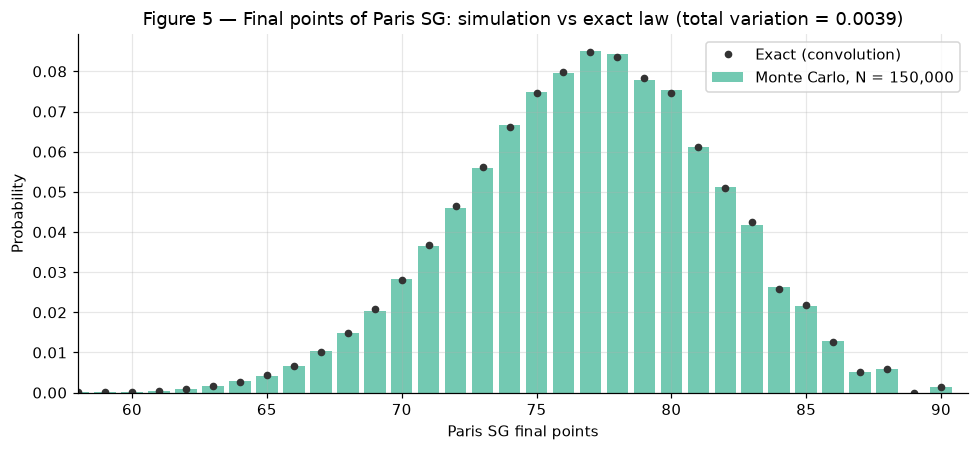

In [17]:
pmf_psg_all = points_pmf(PSG, np.ones(state.n_matches, dtype=bool))
support = state.base_pts[PSG] + np.arange(pmf_psg_all.size)
freq_mc = np.bincount(pts_mc[:, PSG] - int(state.base_pts[PSG]), minlength=pmf_psg_all.size) / N_MAIN
tv = 0.5 * np.abs(freq_mc - pmf_psg_all).sum()
tv_noise = 0.5 * np.sum(np.sqrt(2 * pmf_psg_all * (1 - pmf_psg_all) / (np.pi * N_MAIN)))  # E|f - p| ≈ sqrt(2p(1-p)/(πN)) per bin
print(f"Total variation distance: observed {tv:.4f} | expected from sampling noise alone ≈ {tv_noise:.4f}")

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(support, freq_mc, width=0.8, color=COL["mc"], alpha=0.55, label=f"Monte Carlo, N = {N_MAIN:,}")
ax.plot(support, pmf_psg_all, "o", color=COL["exact"], ms=4, label="Exact (convolution)")
visible = support[pmf_psg_all > 1e-4]
ax.set(xlim=(visible.min() - 1, visible.max() + 1),
       xlabel="Paris SG final points", ylabel="Probability",
       title=f"Figure 5 — Final points of Paris SG: simulation vs exact law (total variation = {tv:.4f})")
ax.legend()
plt.tight_layout()
plt.show()

**Check 2: the ranking code, by enumeration of a whole matchday.** The convolution does not exercise the ranking step (goal difference, random tie-breaks, 18 teams at once). We therefore place ourselves before the **last matchday** (17 May 2026, 9 matches) with the real standings, and restrict each match to three scores — $1$–$0$, $0$–$0$, $0$–$1$ — with the model's win/draw/loss probabilities. There are then $3^9 = 19\,683$ possible ends of season, few enough to **enumerate**: for each of them the exact final table follows, with exact ties shared uniformly. The simulator (same `final_tables` function, random tie-breaks included) must reproduce the resulting $18 \times 18$ matrix of position probabilities.

In [18]:
state_last = season_state(pd.Timestamp("2026-05-17"))
assert state_last.n_matches == 9
p_last = np.column_stack(outcome_probs(*model.rates(state_last.h, state_last.a)))  # (9, 3): home win, draw, away win
SCORES = np.array([[1, 0], [0, 0], [0, 1]])  # one scoreline per outcome

# Exact: enumerate the 3^9 outcomes; exact ties (points and goal difference) are shared uniformly
combos = np.array(list(product(range(3), repeat=state_last.n_matches)))  # (19683, 9)
prob = np.prod(p_last[np.arange(state_last.n_matches), combos], axis=1)
pts_e, gd_e = points_and_gd(state_last, SCORES[combos, 0], SCORES[combos, 1])
key_e = 1000 * pts_e + gd_e
above = (key_e[:, None, :] > key_e[:, :, None]).sum(axis=2)  # teams strictly ahead of each team
tied = (key_e[:, None, :] == key_e[:, :, None]).sum(axis=2)  # tied teams, itself included
pos_exact = np.zeros((T, T))
for k in range(T):
    pos_exact[:, k] = (prob[:, None] * ((above <= k) & (k < above + tied)) / tied).sum(axis=0)

# Monte Carlo with the same three scorelines
rng = make_rng(16)
draw_k = (rng.random((N_MAIN, state_last.n_matches, 1)) > np.cumsum(p_last, axis=1)[None, :, :-1]).sum(axis=2)
_, pos_last = final_tables(state_last, SCORES[draw_k, 0], SCORES[draw_k, 1], rng.random((N_MAIN, T)))
pos_freq = np.stack([np.bincount(pos_last[:, i], minlength=T) / N_MAIN for i in range(T)])
err_last = np.abs(pos_freq - pos_exact)
r_last = radius_hoeffding(N_MAIN, DELTA / T**2)  # simultaneous over the 324 probabilities
print(f"Last matchday: {len(combos):,} outcomes enumerated | {np.sum(pos_exact > 0)} non-zero position probabilities")
print(f"Max |Monte Carlo − exact| over the 18 × 18 position probabilities: {err_last.max():.4f} "
      f"(simultaneous Hoeffding radius for 324 estimates: {r_last:.4f}) | positions with ties in the exact law: "
      f"{np.mean((tied > 1).any(axis=1)):.1%} of outcomes")

Last matchday: 19,683 outcomes enumerated | 38 non-zero position probabilities
Max |Monte Carlo − exact| over the 18 × 18 position probabilities: 0.0021 (simultaneous Hoeffding radius for 324 estimates: 0.0056) | positions with ties in the exact law: 0.0% of outcomes


#### What do we observe?

- **The simulator reproduces the exact law.** The three probabilities computed by Monte Carlo fall within the Hoeffding radius of their exact values, and the simulated histogram of Paris SG's final points (Figure 5) overlays the exact convolution (total variation $0.0039$, below its expected value under pure sampling noise, $\approx 0.0048$).
- **A single run is a single random draw.** In this run, the error on $P(\text{PSG} = \text{Lens})$ is $2.4$ standard deviations. Taken alone, this could signal a bug — or bad luck.
- **A simulation cannot prove the absence of bias; it can bound it.** Over 200 further independent runs, the standardised errors on $P(\text{PSG} > \text{Lens})$ have mean $-0.10$ (expected $0 \pm 0.14$), standard deviation $1.00$ (expected $1 \pm 0.10$) and a maximum of $2.5$ in absolute value (typical for 200 normal draws): the simulator's variance is exactly the binomial one. Pooled over 4 million seasons, Monte Carlo minus exact is $-0.0003 \pm 0.0004$: **any bias is below $0.0006$**, six times smaller than the Hoeffding radius of one team and a hundred times smaller than the model uncertainty of Section 4.3.
- **The ranking code is exact too.** Before the last matchday, the 324 position probabilities obtained by enumerating the $3^9 = 19\,683$ outcomes are reproduced by the simulator within $0.0021$, inside the simultaneous Hoeffding radius ($0.0056$). In this configuration no two teams can finish level on both points and goal difference, so the random tie-break is not exercised by this check; it is a single uniform draw by construction.
- **The title probability is not $P(\text{PSG} > \text{Lens})$.** On the same simulations, $0.8567 = 0.8458 + 0.0262 - 0.0154$: Paris SG gains $2.6$ points from the seasons where both teams finish level on points (goal difference then decides, and Paris SG starts with a $+4$ advantage), and loses $1.5$ points from the seasons where it finishes above Lens but a third team wins the title.
- **The tie-break approximation is harmless.** The random draw used beyond goal difference decides the title in only **0.05%** of seasons (Section 3.3): approximating the six remaining official criteria changes the title probabilities by at most this amount, so implementing head-to-head points is not worth the complexity.

**Answer to Q3:** yes — the simulator matches two exact computations (a convolution and a full enumeration), and its bias is bounded below $0.0006$.

### 3.5 — Common random numbers: what is a match worth?

Lens – Paris SG on 13 May 2026 looks decisive. How much does its result change the title probability? We want

$$\Delta = P(C \mid \text{Lens } 0\text{–}1 \text{ PSG}) - P(C \mid \text{Lens } 1\text{–}0 \text{ PSG})$$

(scores written home–away, as everywhere in this notebook).

The naive approach estimates the two probabilities with **independent** simulations. A better one uses **common random numbers (CRN)**: the same $N$ simulated seasons, in which only the head-to-head score is changed. With paired indicators $(I_i^{\text{win}}, I_i^{\text{loss}})$,

$$\operatorname{Var}\big[\hat\Delta^{\mathrm{CRN}}\big] = \frac{\operatorname{Var}[I^{\text{win}}] + \operatorname{Var}[I^{\text{loss}}] - 2\operatorname{Cov}(I^{\text{win}}, I^{\text{loss}})}{N}, \qquad \operatorname{Var}\big[\hat\Delta^{\mathrm{indep}}\big] = \frac{\operatorname{Var}[I^{\text{win}}] + \operatorname{Var}[I^{\text{loss}}]}{N}.$$

Both estimators are unbiased; CRN wins whenever the covariance is positive. Here it is, by a **monotonicity** argument: in a given simulated season, changing a defeat into a win gives Paris SG 3 more points and a better goal difference, takes 3 points and goal difference away from Lens, and leaves everything else unchanged. So if Paris SG is champion after losing, it is also champion after winning: $I^{\text{loss}} \le I^{\text{win}}$. With $p_1 = P(C \mid \text{win})$, $p_2 = P(C \mid \text{loss})$, this gives $\operatorname{Cov}(I^{\text{win}}, I^{\text{loss}}) = p_2 - p_1 p_2 = p_2(1-p_1) \ge 0$ and $I^{\text{win}} - I^{\text{loss}} \in \{0, 1\}$, hence the exact variance ratio

$$\frac{\operatorname{Var}[\hat\Delta^{\mathrm{indep}}]}{\operatorname{Var}[\hat\Delta^{\mathrm{CRN}}]} = \frac{p_1(1-p_1) + p_2(1-p_2)}{\Delta(1-\Delta)},$$

which is large when $\Delta$ is small, i.e. when the two scenarios rarely lead to different champions.

In [19]:
def title_given_h2h(gh, ga, u, score):
    """Paris SG title indicators when the head-to-head score is forced to `score` = (Lens goals, PSG goals)."""
    gh, ga = gh.copy(), ga.copy()
    gh[:, H2H], ga[:, H2H] = score
    return final_tables(state, gh, ga, u)[1][:, PSG] == 0


def compare_scenarios(score_1, score_2, n: int, rng: np.random.Generator) -> dict:
    """Estimate P(C | score_1) - P(C | score_2) with common random numbers and with independent runs."""
    gh, ga = simulate_goals(model, state, n, rng)
    u = rng.random((n, T))
    i_1, i_2 = title_given_h2h(gh, ga, u, score_1), title_given_h2h(gh, ga, u, score_2)  # same random numbers
    gh2, ga2 = simulate_goals(model, state, n, rng)
    i_2_indep = title_given_h2h(gh2, ga2, rng.random((n, T)), score_2)  # fresh random numbers
    se_crn = (i_1.astype(float) - i_2).std(ddof=1) / np.sqrt(n)
    se_ind = np.sqrt(i_1.var(ddof=1) / n + i_2_indep.var(ddof=1) / n)
    return {
        "P(C | scenario 1)": i_1.mean(), "P(C | scenario 2)": i_2.mean(),
        "Δ (CRN)": i_1.mean() - i_2.mean(), "95% radius CRN": z * se_crn,
        "Δ (independent)": i_1.mean() - i_2_indep.mean(), "95% radius indep.": z * se_ind,
        "variance ratio": (se_ind / se_crn) ** 2,
        "theoretical ratio": (i_1.mean() * (1 - i_1.mean()) + i_2.mean() * (1 - i_2.mean())) / ((i_1.mean() - i_2.mean()) * (1 - i_1.mean() + i_2.mean())),
    }


N_CRN = 50_000
crn = pd.DataFrame({
    "Lens 0–1 PSG vs Lens 1–0 PSG": compare_scenarios((0, 1), (1, 0), N_CRN, make_rng(3)),
    "Lens 0–2 PSG vs Lens 0–1 PSG": compare_scenarios((0, 2), (0, 1), N_CRN, make_rng(9)),
}).T
display(crn)

,P(C | scenario 1),P(C | scenario 2),Δ (CRN),95% radius CRN,Δ (independent),95% radius indep.,variance ratio,theoretical ratio
Lens 0–1 PSG vs Lens 1–0 PSG,0.9311,0.7440,0.1871,0.0034,0.1881,0.0044,1.6770,1.6738
Lens 0–2 PSG vs Lens 0–1 PSG,0.9309,0.9303,0.0006,0.0002,0.0006,0.0032,215.4939,215.5226


#### What do we observe?

- **The head-to-head is a "six-pointer".** Winning at Lens raises Paris SG's title probability from $0.74$ to $0.93$: $\Delta \approx 0.19$.
- **For this comparison, CRN only divides the variance by $1.68$** (theory: $1.67$, from the formula above): the two scenarios lead to different champions in about one season in five, so $\Delta(1-\Delta)$ is not small.
- **For nearby scenarios, CRN is decisive.** Winning $0$–$2$ instead of $0$–$1$ changes only the goal difference. With CRN, $\Delta = 0.0006 \pm 0.0002$: a small but clearly positive effect. With independent runs, $\Delta = 0.0006 \pm 0.0032$: the interval is sixteen times wider and contains zero. The variance ratio is $215$ (theory: $215.5$): independent runs would need **about 215 times more simulations** for the same precision.
- **Lesson.** CRN is most useful exactly when it is most needed: in sensitivity analysis ("what if this one detail changed?"), where the effect is small and independent runs drown it in noise.

**The value of every match.** The same idea answers a broader question: *which of the 153 remaining matches matter most for the title?* For each match $m$ we estimate

$$\Delta_m = P(C \mid \text{home win } 1\text{–}0 \text{ in match } m) - P(C \mid \text{away win } 0\text{–}1 \text{ in match } m)$$

on **one common set** of $N$ simulated seasons: for each $m$, only match $m$ is overwritten, everything else is shared by the 306 scenarios. Updating the points and goal differences of the two teams of match $m$ is enough, so the 306 scenarios cost little more than one simulation. For a match not involving Paris SG, $\Delta_m$ can be negative (a Lens home win hurts Paris SG) and $I^{\text{home}} - I^{\text{away}} \in \{-1, 0, 1\}$; the CRN standard error is the empirical standard deviation of these paired differences over $\sqrt N$.

In [20]:
N_ALL = 40_000
rng = make_rng(14)
gh0, ga0 = simulate_goals(model, state, N_ALL, rng)
u0 = rng.random((N_ALL, T))
pts0, gd0 = points_and_gd(state, gh0, ga0)


def title_with_score(m: int, score: tuple[int, int]) -> np.ndarray:
    """Paris SG title indicators when match m is forced to `score` = (home goals, away goals), all else unchanged."""
    x, y = gh0[:, m].astype(float), ga0[:, m].astype(float)
    i, j = state.h[m], state.a[m]
    pts, gd = pts0.copy(), gd0.copy()
    sx, sy = score
    pts[:, i] += (3 * (sx > sy) + (sx == sy)) - (3 * (x > y) + (x == y))  # replace the simulated result
    pts[:, j] += (3 * (sy > sx) + (sx == sy)) - (3 * (y > x) + (x == y))
    gd[:, i] += (sx - sy) - (x - y)
    gd[:, j] -= (sx - sy) - (x - y)
    return np.argmax(1000 * pts + gd + 0.5 * u0, axis=1) == PSG


rows = []
for m in range(state.n_matches):
    i_home, i_away = title_with_score(m, (1, 0)), title_with_score(m, (0, 1))
    diff = i_home.astype(float) - i_away
    p1, p2 = i_home.mean(), i_away.mean()
    var_crn = diff.var(ddof=1)
    kind = ("Lens – PSG" if m == H2H else "Paris SG match" if PSG in (state.h[m], state.a[m])
            else "Lens match" if LENS in (state.h[m], state.a[m]) else "other")
    rows.append({"match": f"{TEAMS[state.h[m]]} – {TEAMS[state.a[m]]}", "date": remaining.date.iloc[m], "kind": kind,
                 "Δ": p1 - p2, "95% radius CRN": z * np.sqrt(var_crn / N_ALL),
                 "variance ratio": (p1 * (1 - p1) + p2 * (1 - p2)) / var_crn if var_crn > 0 else np.inf})
values = pd.DataFrame(rows)
values["|Δ|"] = values["Δ"].abs()
values = values.sort_values("|Δ|", ascending=False).reset_index(drop=True)
values.index += 1
display(values.head(10).drop(columns="|Δ|"))
significant = values["|Δ|"] > values["95% radius CRN"]
print(f"Matches whose CRN interval excludes 0: {significant.sum()} of {len(values)} | rank of Lens – PSG: "
      f"{values.index[values.kind == 'Lens – PSG'][0]}")
print("Mean |Δ| by kind of match:", values.groupby("kind")["|Δ|"].mean().round(4).to_dict())
print("Significant swings by kind of match:", values[significant].groupby("kind").size().to_dict())
finite = values.loc[significant, "variance ratio"]
print(f"Variance ratio independent / CRN over the significant matches: median {finite.median():.0f}, "
      f"min {finite.min():.1f}, max {finite.max():.0f} → independent runs would need "
      f"{finite.median():.0f} times more simulations for the same precision (median)")

,match,date,kind,Δ,95% radius CRN,variance ratio
1,Lens – Paris SG,2026-05-13,Lens – PSG,-0.1866,0.0038,1.6798
2,Paris SG – Marseille,2026-02-08,Paris SG match,0.1235,0.0032,2.5175
3,Paris SG – Metz,2026-02-21,Paris SG match,0.1168,0.0031,2.9337
4,Paris SG – Lorient,2026-05-02,Paris SG match,0.1153,0.0031,2.9101
5,Paris SG – Lille,2026-01-16,Paris SG match,0.1144,0.0031,2.6753
6,Paris SG – Nantes,2026-04-22,Paris SG match,0.1141,0.0031,2.9124
7,Paris SG – Brest,2026-05-10,Paris SG match,0.1121,0.0031,2.8891
8,Paris SG – Toulouse,2026-04-03,Paris SG match,0.1114,0.0031,2.8662
9,Angers – Paris SG,2026-04-25,Paris SG match,-0.1104,0.0031,2.8375
10,Paris SG – Lyon,2026-04-19,Paris SG match,0.1097,0.0031,2.8039


Matches whose CRN interval excludes 0: 86 of 153 | rank of Lens – PSG: 1
Mean |Δ| by kind of match: {'Lens match': 0.0715, 'Lens – PSG': 0.1866, 'Paris SG match': 0.1107, 'other': 0.002}
Significant swings by kind of match: {'Lens match': 16, 'Lens – PSG': 1, 'Paris SG match': 16, 'other': 53}
Variance ratio independent / CRN over the significant matches: median 23, min 1.7, max 314 → independent runs would need 23 times more simulations for the same precision (median)


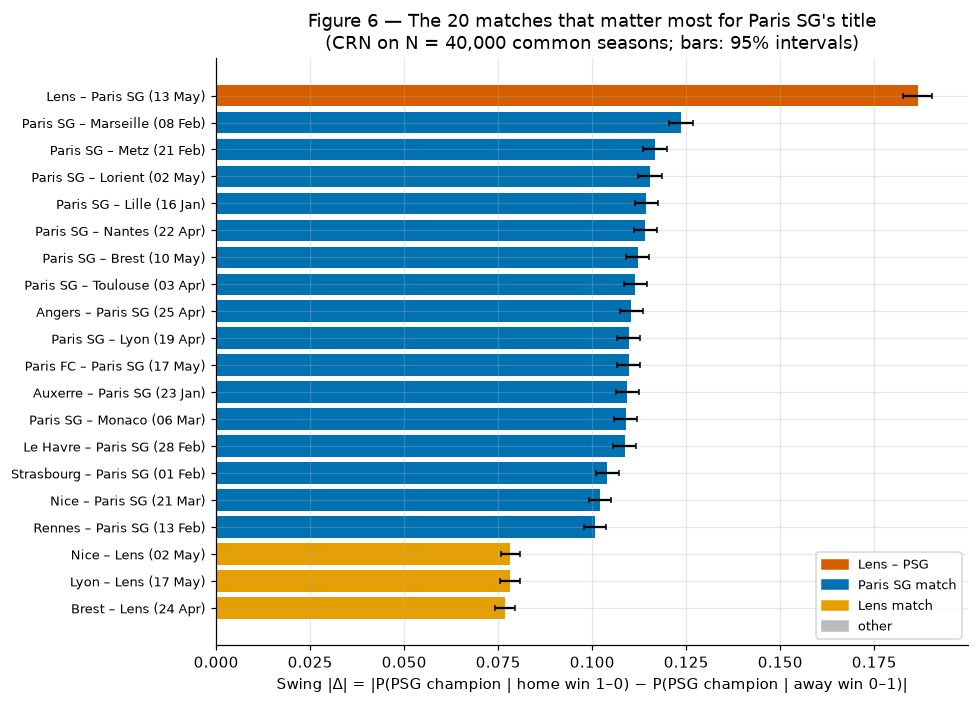

In [21]:
top = values.head(20).iloc[::-1]
kind_col = {"Lens – PSG": COL["hoeff"], "Paris SG match": COL["psg"], "Lens match": COL["lens"], "other": COL["other"]}
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(range(len(top)), top["|Δ|"], xerr=top["95% radius CRN"], color=[kind_col[k] for k in top.kind], capsize=2)
ax.set_yticks(range(len(top)), [f"{r.match} ({r.date:%d %b})" for r in top.itertuples()], fontsize=8.5)
ax.set(xlabel="Swing |Δ| = |P(PSG champion | home win 1–0) − P(PSG champion | away win 0–1)|",
       title=f"Figure 6 — The 20 matches that matter most for Paris SG's title\n"
             f"(CRN on N = {N_ALL:,} common seasons; bars: 95% intervals)")
ax.legend(handles=[Patch(color=c, label=k) for k, c in kind_col.items()], loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

#### What do we observe?

- **Lens – Paris SG is the most valuable match of the 153**: its result swings Paris SG's title probability by $0.19$. Next come Paris SG's own matches, each worth about $0.11$ (the home match against Marseille tops them at $0.12$); Lens's matches are worth $0.07$ on average.
- **Indirect effects are small but measurable.** The 120 matches involving neither leader are worth $0.002$ on average. Yet with CRN, 86 of the 153 swings have a 95% interval that excludes zero, including 53 matches between third parties (through the points of the third-placed teams and through goal difference).
- **CRN is what makes this table affordable.** For the median match with a significant swing, independent runs would need **23 times** more simulations for the same precision — from about $2$ for Paris SG's matches, where $\Delta$ is large, to more than $300$ for remote matches, where it is tiny: the formula above at work. All 306 scenarios reuse one set of $40\,000$ seasons.

---
## 4 — Results and interpretation

### 4.1 — Convergence and coverage: do the guarantees hold?

We first look at a single run: the running estimate $\hat p_N$ for Paris SG as $N$ grows, with the three 95% radii around it.

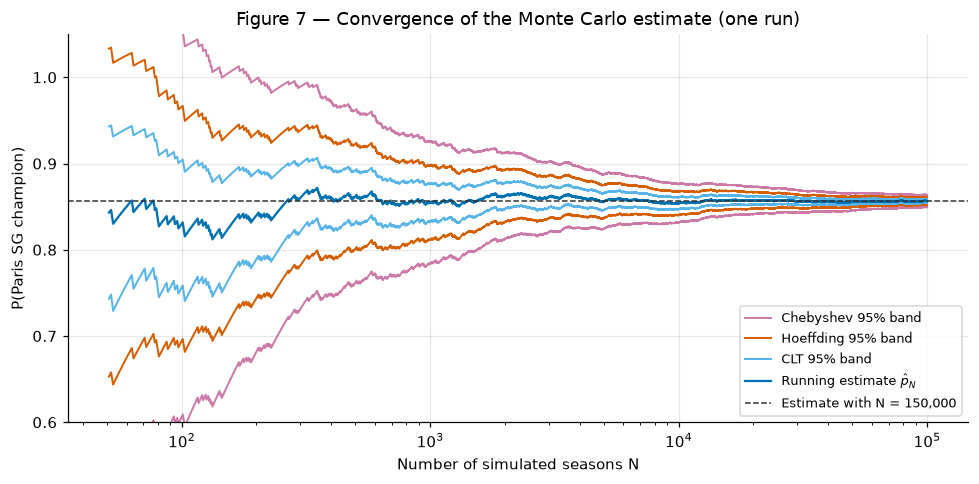

Chebyshev band misses the N = 150,000 estimate for     0 values of N
Hoeffding band misses the N = 150,000 estimate for     0 values of N
      CLT band misses the N = 150,000 estimate for     0 values of N


In [22]:
n_show = 100_000
running = np.cumsum(title_mc[:n_show, PSG]) / np.arange(1, n_show + 1)
ns = np.arange(1, n_show + 1)
start = 50

fig, ax = plt.subplots(figsize=(9, 4.5))
for name, r, key in (
    ("Chebyshev", radius_chebyshev(ns, DELTA), "cheb"),
    ("Hoeffding", radius_hoeffding(ns, DELTA), "hoeff"),
    ("CLT", radius_clt(ns, DELTA, running), "clt"),
):
    ax.plot(ns[start:], (running + r)[start:], color=COL[key], lw=1.3, label=f"{name} 95% band")
    ax.plot(ns[start:], (running - r)[start:], color=COL[key], lw=1.3)
ax.plot(ns[start:], running[start:], color=COL["psg"], lw=1.5, label="Running estimate $\\hat p_N$")
ax.axhline(p_hat[PSG], color=COL["exact"], ls="--", lw=1, label=f"Estimate with N = {N_MAIN:,}")
ax.set(xscale="log", ylim=(0.6, 1.05), xlabel="Number of simulated seasons N", ylabel="P(Paris SG champion)",
       title="Figure 7 — Convergence of the Monte Carlo estimate (one run)")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

# Along this single path, for which N does each band miss the final estimate?
for name, r in (("Chebyshev", radius_chebyshev(ns, DELTA)), ("Hoeffding", radius_hoeffding(ns, DELTA)),
                ("CLT", radius_clt(ns, DELTA, running))):
    miss = np.flatnonzero(np.abs(running - p_hat[PSG]) > r)
    miss = miss[miss >= start] + 1
    print(f"{name:>9} band misses the N = {N_MAIN:,} estimate for {miss.size:5d} values of N"
          + (f", between N = {miss.min()} and N = {miss.max()}" if miss.size else ""))

A single run cannot tell whether "95%" is honest. The meaning of a confidence guarantee is **frequentist**: over many independent repetitions, at least 95% of the intervals must contain the true value. We therefore repeat the experiment $R = 1\,000$ times with only $N = 500$ seasons each, and count how often each interval contains the reference value (the $N = 150\,000$ estimate, whose own error, about $0.1$ point, is negligible at this scale). We do it for Paris SG (large $Np$), for the third most likely champion, and for the team whose $Np$ is closest to $1$. With $R = 1\,000$ repetitions, a coverage estimate is itself uncertain by about $\pm 1.4$ points (95%).

In [23]:
R, N_SMALL = 1_000, 500
_, pos_cov = simulate_seasons(model, state, R * N_SMALL, make_rng(4))
blocks = (pos_cov == 0).reshape(R, N_SMALL, T).mean(axis=1)  # (R, T): one estimate per repetition
third = int(np.argsort(-p_hat)[2])
rare = int(np.argmin(np.abs(N_SMALL * p_hat - 1)))  # N p closest to 1

rows = []
for team in (PSG, third, rare):
    est, ref = blocks[:, team], p_hat[team]
    for name, r in (
        ("Chebyshev", np.full(R, radius_chebyshev(N_SMALL, DELTA))),
        ("Hoeffding", np.full(R, radius_hoeffding(N_SMALL, DELTA))),
        ("CLT (Wald)", radius_clt(N_SMALL, DELTA, est)),
    ):
        cov = np.mean(np.abs(est - ref) <= r)
        rows.append({"team": f"{TEAMS[team]} (p ≈ {ref:.4f}, Np ≈ {N_SMALL * ref:.1f})", "radius": name, "coverage": cov,
                     "± (95%, R reps)": z * np.sqrt(cov * (1 - cov) / R), "mean half-width": r.mean(),
                     "runs with p̂ = 0": np.mean(est == 0)})
coverage = pd.DataFrame(rows).set_index(["team", "radius"])
print(f"Coverage of nominal 95% intervals over R = {R} repetitions of N = {N_SMALL} seasons")
display(coverage)

Coverage of nominal 95% intervals over R = 1000 repetitions of N = 500 seasons


coverage  ± (95%, R reps)  \
team                              radius                                  
Paris SG (p ≈ 0.8567, Np ≈ 428.3) Chebyshev     1.0000           0.0000   
                                  Hoeffding     1.0000           0.0000   
                                  CLT (Wald)    0.9510           0.0134   
Marseille (p ≈ 0.0152, Np ≈ 7.6)  Chebyshev     1.0000           0.0000   
                                  Hoeffding     1.0000           0.0000   
                                  CLT (Wald)    0.9520           0.0132   
Lyon (p ≈ 0.0018, Np ≈ 0.9)       Chebyshev     1.0000           0.0000   
                                  Hoeffding     1.0000           0.0000   
                                  CLT (Wald)    0.5930           0.0304   

                                              mean half-width  \
team                              radius                        
Paris SG (p ≈ 0.8567, Np ≈ 428.3) Chebyshev            0.1000   
                                  Hoeffding            0.0607   
                                  CLT (Wald)           0.0306   
Marseille (p ≈ 0.0152, Np ≈ 7.6)  Chebyshev            0.1000   
                                  Hoeffding            0.0607   
                                  CLT (Wald)           0.0108   
Lyon (p ≈ 0.0018, Np ≈ 0.9)       Chebyshev            0.1000   
                                  Hoeffding            0.0607   
                                  CLT (Wald)           0.0028   

                                              runs with p̂ = 0  
team                              radius                        
Paris SG (p ≈ 0.8567, Np ≈ 428.3) Chebyshev             0.0000  
                                  Hoeffding             0.0000  
                                  CLT (Wald)            0.0000  
Marseille (p ≈ 0.0152, Np ≈ 7.6)  Chebyshev             0.0000  
                                  Hoeffding             0.0000  
                                  CLT (Wald)            0.0000  
Lyon (p ≈ 0.0018, Np ≈ 0.9)       Chebyshev             0.4070  
                                  Hoeffding             0.4070  
                                  CLT (Wald)            0.4070

#### What do we observe?

**On one run (Figure 7).**
- The estimate fluctuates for small $N$, then stabilises; the bands shrink at the predicted $1/\sqrt N$ rate and keep the same ordering at every $N$: Chebyshev ⊃ Hoeffding ⊃ CLT.
- In this run, no band ever misses the final value. This is not a property of the bands: "95%" holds for each **fixed** $N$, not simultaneously for all $N$ along one path. Watching a running estimate and stopping when it "looks stable" is not covered by these guarantees.

**Over 1 000 repetitions (table).** Coverage estimates are themselves uncertain by about $\pm 1.4$ points.

| | Paris SG ($Np \approx 428$) | Marseille ($Np \approx 7.6$) | Lyon ($Np \approx 0.9$) |
|---|---|---|---|
| Chebyshev | 100%, half-width $0.100$ | 100%, half-width $0.100$ (≈ 7 × $p$) | 100%, half-width $0.100$ (≈ 56 × $p$) |
| Hoeffding | 100%, half-width $0.061$ | 100%, half-width $0.061$ | 100%, half-width $0.061$ |
| CLT (Wald) | **95.1%**, half-width $0.031$ | **95.2%**, half-width $0.011$ | **59%**, half-width $0.003$ |

- **Non-asymptotic guarantees are conservative.** Chebyshev and Hoeffding hold for every $N$, but at the price of intervals 3.3 and 2.0 times wider than the CLT one for Paris SG. This is the trade-off of Chapter 1: guaranteed but pessimistic versus approximate but sharp.
- **Distribution-free bounds ignore the variance.** For a small $p$ they are valid but uninformative (a half-width 56 times the quantity estimated for Lyon). Variance-aware bounds (the Bernoulli-specific Chebyshev radius of Exercise 8, Bernstein's inequality) would be much tighter.
- **The CLT is accurate as long as $Np$ is large** — both Paris SG and Marseille are compatible with 95% — **and collapses when $Np \approx 1$**: for Lyon, 41% of the runs never see Lyon champion, $\hat p_N = 0$, and the Wald interval reduces to $\{0\}$, which excludes the truth. Coverage falls to 59%. Score-based intervals (Wilson) are the standard remedy; Sections 5.2 and 5.3 push this regime further.

### 4.2 — The answer under the model: title probabilities

In [24]:
order = np.argsort(-p_hat)
contenders = [i for i in order if p_hat[i] > 0]
res_table = pd.DataFrame({
    "P(champion)": [f"{p_hat[i]:.4f}" if p_hat[i] >= 1e-3 else f"{p_hat[i]:.1e}" for i in contenders],
    "simultaneous 95% interval": [f"[{max(p_hat[i] - r_simul, 0):.4f}, {min(p_hat[i] + r_simul, 1):.4f}]" for i in contenders],
    "title seasons (out of N)": [int(title_mc[:, i].sum()) for i in contenders],
    "points at the cutoff": state.base_pts[contenders].astype(int),
}, index=[TEAMS[i] for i in contenders])
print(f"N = {N_MAIN:,} | simultaneous Hoeffding radius for K = {T} teams: ±{r_simul:.4f}")
display(res_table)

N = 150,000 | simultaneous Hoeffding radius for K = 18 teams: ±0.0047


,P(champion),simultaneous 95% interval,title seasons (out of N),points at the cutoff
Paris SG,0.8567,"[0.8520, 0.8614]",128501,39
Lens,0.1195,"[0.1149, 0.1242]",17932,40
Marseille,0.0152,"[0.0105, 0.0199]",2277,32
Lille,0.0058,"[0.0012, 0.0105]",875,32
Lyon,0.0018,"[0.0000, 0.0065]",266,30
Rennes,9.5e-04,"[0.0000, 0.0056]",143,30
Strasbourg,2.0e-05,"[0.0000, 0.0047]",3,24
Monaco,2.0e-05,"[0.0000, 0.0047]",3,23


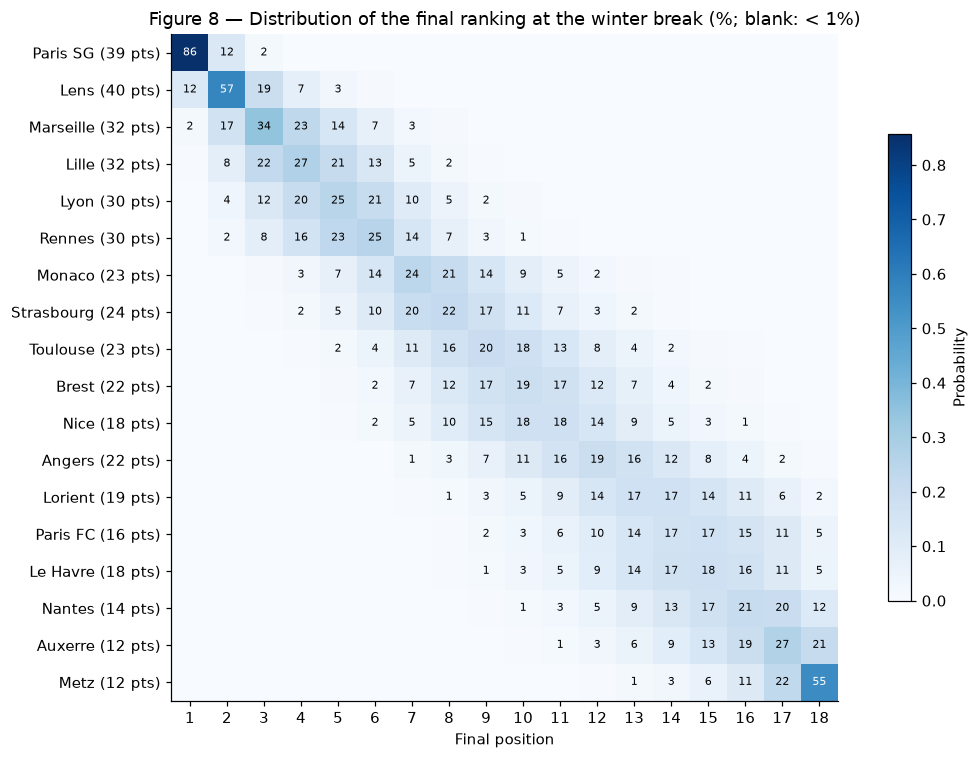

P(top two): Paris SG 0.98, Lens 0.69 | P(Marseille third) 0.34 | P(direct relegation, 17th–18th): Metz 0.78, Auxerre 0.47


In [25]:
# Probability of each final position for each team, teams sorted by expected position
pos_prob = np.stack([np.bincount(pos_mc[:, i], minlength=T) / N_MAIN for i in range(T)])  # [team, position]
sorted_teams = np.argsort(pos_prob @ np.arange(T))

fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(pos_prob[sorted_teams], cmap="Blues", vmin=0, vmax=pos_prob.max())
for r_, i in enumerate(sorted_teams):
    for k in range(T):
        if pos_prob[i, k] >= 0.01:
            ax.text(k, r_, f"{100 * pos_prob[i, k]:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if pos_prob[i, k] > 0.5 * pos_prob.max() else "black")
ax.set_xticks(range(T), range(1, T + 1))
ax.set_yticks(range(T), [f"{TEAMS[i]} ({int(state.base_pts[i])} pts)" for i in sorted_teams])
ax.set(xlabel="Final position", title="Figure 8 — Distribution of the final ranking at the winter break (%; blank: < 1%)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="Probability")
plt.tight_layout()
plt.show()
MARSEILLE, METZ, AUXERRE = IDX["Marseille"], IDX["Metz"], IDX["Auxerre"]
print(f"P(top two): Paris SG {pos_prob[PSG, :2].sum():.2f}, Lens {pos_prob[LENS, :2].sum():.2f} | "
      f"P(Marseille third) {pos_prob[MARSEILLE, 2]:.2f} | P(direct relegation, 17th–18th): "
      f"Metz {pos_prob[METZ, 16:].sum():.2f}, Auxerre {pos_prob[AUXERRE, 16:].sum():.2f}")

**How much does the choice of model move the answer?** The same simulator, with the same $N$, is fed each of the five structures — fitted on the current season only, and with the selected memory $\rho^*$.

In [26]:
rng = make_rng(15)
rows = []
for s in STRUCTURES:
    for label, m_ in (("2025/26 only (ρ = 0)", fits_ws[s]),
                      (f"with history (ρ* = {RHO_STAR})", restrict(fit_with_history(2025, played_all, RHO_STAR, s), TEAMS))):
        if s == STRUCTURE and label.startswith("with"):
            p_ = p_hat  # the selected model: reuse the main run
        else:
            p_ = (simulate_seasons(m_, state, N_MAIN, rng)[1] == 0).mean(axis=0)
        rows.append({"model": s, "data": label, "P(PSG)": p_[PSG], "P(Lens)": p_[LENS],
                     "backtest log-score": mean_ls[(s, RHO_STAR if label.startswith("with") else 0.0, None)]})
by_model = pd.DataFrame(rows).set_index(["model", "data"])
print(f"Title probabilities under each model (N = {N_MAIN:,} each: simultaneous radius ±{r_simul:.4f})")
display(by_model.unstack("data"))

Title probabilities under each model (N = 150,000 each: simultaneous radius ±0.0047)


P(PSG)                                      P(Lens)  \
data  2025/26 only (ρ = 0) with history (ρ* = 0.6) 2025/26 only (ρ = 0)   
model                                                                     
M0                  0.3832                  0.3827               0.4357   
M1                  0.3901                  0.3868               0.4564   
M2                  0.3639                  0.4673               0.5980   
M3                  0.6014                  0.8365               0.2979   
M4                  0.5655                  0.8567               0.4044   

                                backtest log-score                          
data  with history (ρ* = 0.6) 2025/26 only (ρ = 0) with history (ρ* = 0.6)  
model                                                                       
M0                     0.4352              -3.0507                 -3.0469  
M1                     0.4476              -3.0363                 -3.0314  
M2                     0.4593              -3.0379                 -3.0088  
M3                     0.1049              -2.9648                 -2.9304  
M4                     0.1195              -2.9740                 -2.9115

#### What do we observe?

- **Under the selected model, Paris SG is a clear favourite despite trailing**: $P(\text{champion}) = 0.857$ against $0.120$ for Lens, with a simultaneous guarantee of $\pm 0.005$ for the 18 teams. Marseille keeps 1.5%, Lille 0.6%; every other team is below 0.2%.
- **Why the second-placed team is favourite.** The deficit is only one point, and the model judges strength from goals over eleven seasons, not from points over half of one: Paris SG's strength is confirmed by its history, while Lens's exceptional first half is partly discounted (Section 3.2). Over 17 remaining matches, a clear edge in strength outweighs a one-point lead.
- **Figure 8 shows that the whole table comes for free.** The same 150 000 simulations give every team's probability of every position: Paris SG finishes in the top two in 98% of seasons, Lens in 69%; Marseille finishes third in 34%; at the bottom, Metz is relegated directly (positions 17–18) in 78% of seasons and Auxerre in 47%.
- **Simultaneous intervals, and their limit.** The union bound guarantees that **all** 18 estimates are within $\pm 0.0047$ of their target with probability at least 95%, for only a third more width than a single interval ($\pm 0.0035$). But for the outsiders the interval is clipped at 0 and says nothing: Strasbourg and Monaco were champions in 3 seasons each out of 150 000, and their interval $[0, 0.0047]$ is compatible with $10^{-3}$ and with $10^{-9}$ alike. Section 5.3 estimates these probabilities with a **relative** error, by importance sampling.
- **The choice of model moves the answer far more than the simulation does.** Without team strengths (M0, M1), Lens's one-point lead makes it the favourite ($P(\text{PSG}) \approx 0.38$–$0.39$). Attack strengths alone (M3) give Paris SG $0.60$ on the current season and $0.84$ with history; the full model gives $0.57$ and $0.86$. Across these ten inputs $P(\text{PSG})$ ranges from $0.36$ to $0.86$ — a hundred times the Monte Carlo radius. Only the out-of-sample comparison of Section 3.2 says which number to believe: models without team strengths are clearly rejected, and between the two best-supported inputs (M4 and M3 with history) the answer moves by $0.02$.

**Answer to Q1 (second part):** the choice of model is the largest single lever on the answer; the data reject the simple models and support the full model with history.

**Answer to Q2:** $18\,445$ simulated seasons would guarantee $\pm 1$ point for one team (Hoeffding); the $N = 150\,000$ fixed in advance guarantees $\pm 0.35$ point per team and $\pm 0.47$ point simultaneously for the 18 teams, and these guarantees are verified empirically (Section 4.1).

### 4.3 — Simulation error vs model uncertainty

The numbers above are **exact up to $\pm 0.5$ point — for the fitted model**. But $\hat\theta$ was estimated from data. How much would $p(\hat\theta)$ move if the data had come out differently?

We estimate the second term of Proposition 3 with a **parametric bootstrap**, itself a Monte Carlo method:
1. simulate new data from the fitted model $P_{\hat\theta}$ (same fixtures, same weights);
2. refit the model on it, giving $\hat\theta^*_b$;
3. estimate $p(\hat\theta^*_b)$ by simulating $N_{\text{in}}$ seasons from the **real** standings at the cutoff;
4. repeat for $b = 1, \dots, B$.

The bootstrap estimates are themselves noisy: by Proposition 3 applied to them, their variance is $\operatorname{Var}[p(\hat\theta^*)] + \mathbb{E}[p(1-p)]/N_{\text{in}}$. We subtract an unbiased estimate of the second term, $\overline{\hat p^*(1-\hat p^*)}/(N_{\text{in}}-1)$, to isolate the parameter uncertainty. We do it for the selected model and, for comparison, for the model M4 fitted on the current season only.

In [27]:
B, N_IN = 200, 5_000


def param_sd(boot_p: np.ndarray) -> float:
    """Parameter standard deviation: bootstrap variance minus the inner Monte Carlo noise (unbiased)."""
    return float(np.sqrt(max(boot_p.var(ddof=1) - np.mean(boot_p * (1 - boot_p)) / (N_IN - 1), 0)))


# Selected model: resimulate every weighted match (current season and history) from the fitted model
rng = make_rng(12)
boot_main = np.empty((B, T))
for b in range(B):
    m_b = fit_poisson_model(hi_m, ai_m, rng.poisson(lam_hm), rng.poisson(lam_am), n_teams=len(ALL_TEAMS),
                            weights=w_main, structure=STRUCTURE)
    boot_main[b] = (simulate_seasons(restrict(m_b, TEAMS), state, N_IN, rng)[1] == 0).mean(axis=0)

# Comparison: M4 on the current season only
rng = make_rng(5)
boot_ws = np.empty((B, T))
for b in range(B):
    m_b = fit_poisson_model(ph_, pa_, rng.poisson(lam_h_fit), rng.poisson(lam_a_fit))
    boot_ws[b] = (simulate_seasons(m_b, state, N_IN, rng)[1] == 0).mean(axis=0)

p_ws = (simulate_seasons(model_ws, state, N_MAIN, make_rng(17))[1] == 0).mean(axis=0)
rows = []
for label, boot_, p_ in ((f"selected ({STRUCTURE}, ρ* = {RHO_STAR})", boot_main, p_hat), ("M4, 2025/26 only", boot_ws, p_ws)):
    for team in (PSG, LENS):
        sd_mc = np.sqrt(p_[team] * (1 - p_[team]) / N_MAIN)
        lo, hi = np.percentile(boot_[:, team], [2.5, 97.5])
        rows.append({"model": label, "team": TEAMS[team], "p̂": p_[team], f"Monte Carlo sd (N = {N_MAIN:,})": sd_mc,
                     "parameter sd": param_sd(boot_[:, team]), "ratio": param_sd(boot_[:, team]) / sd_mc,
                     "bootstrap 95% range": f"[{lo:.2f}, {hi:.2f}]"})
decomp = pd.DataFrame(rows).set_index(["model", "team"])
display(decomp)
sd_param_main, sd_param_ws = param_sd(boot_main[:, PSG]), param_sd(boot_ws[:, PSG])
elbow = p_hat[PSG] * (1 - p_hat[PSG]) / sd_param_main**2  # N at which the two terms of Proposition 3 are equal
print(f"Elbow N = A / V for Paris SG (selected model): {elbow:.0f} seasons | N at which the Monte Carlo sd is "
      f"10 times below the parameter sd: {100 * elbow:,.0f}")

p̂  Monte Carlo sd (N = 150,000)  \
model                   team                                            
selected (M4, ρ* = 0.6) Paris SG 0.8567                        0.0009   
                        Lens     0.1195                        0.0008   
M4, 2025/26 only        Paris SG 0.5665                        0.0013   
                        Lens     0.4038                        0.0013   

                                  parameter sd    ratio bootstrap 95% range  
model                   team                                                 
selected (M4, ρ* = 0.6) Paris SG        0.0733  81.0013        [0.66, 0.94]  
                        Lens            0.0675  80.6028        [0.04, 0.29]  
M4, 2025/26 only        Paris SG        0.2314 180.8297        [0.12, 0.95]  
                        Lens            0.2274 179.4665        [0.03, 0.84]

Elbow N = A / V for Paris SG (selected model): 23 seasons | N at which the Monte Carlo sd is 10 times below the parameter sd: 2,286


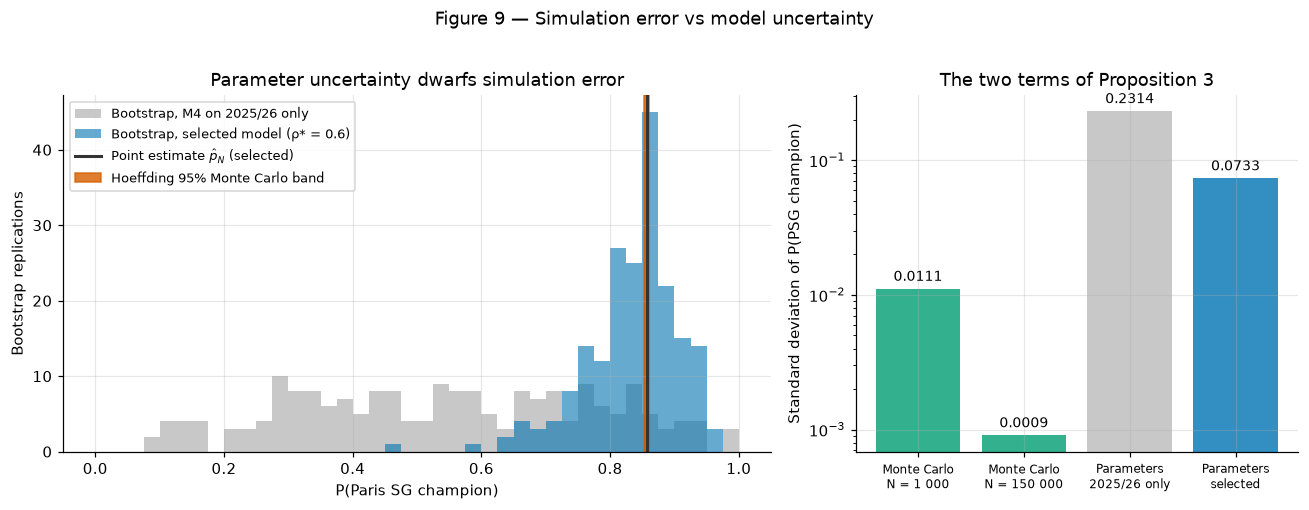

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
bins = np.linspace(0, 1, 41)
ax.hist(boot_ws[:, PSG], bins=bins, color=COL["other"], alpha=0.8, label="Bootstrap, M4 on 2025/26 only")
ax.hist(boot_main[:, PSG], bins=bins, color=COL["psg"], alpha=0.6, label=f"Bootstrap, selected model (ρ* = {RHO_STAR})")
ax.axvline(p_hat[PSG], color=COL["exact"], lw=2, label="Point estimate $\\hat p_N$ (selected)")
ax.axvspan(p_hat[PSG] - r_single, p_hat[PSG] + r_single, color=COL["hoeff"], alpha=0.8, label="Hoeffding 95% Monte Carlo band")
ax.set(xlabel="P(Paris SG champion)", ylabel="Bootstrap replications", title="Parameter uncertainty dwarfs simulation error")
ax.legend(fontsize=8.5, loc="upper left")

ax = axes[1]
labels = ["Monte Carlo\nN = 1 000", f"Monte Carlo\nN = {N_MAIN:,}".replace(",", " "), "Parameters\n2025/26 only", "Parameters\nselected"]
values_sd = [np.sqrt(p_hat[PSG] * (1 - p_hat[PSG]) / 1_000), np.sqrt(p_hat[PSG] * (1 - p_hat[PSG]) / N_MAIN), sd_param_ws, sd_param_main]
ax.bar(labels, values_sd, color=[COL["mc"], COL["mc"], COL["other"], COL["psg"]], alpha=0.8)
for k, v in enumerate(values_sd):
    ax.text(k, v * 1.15, f"{v:.4f}", ha="center", fontsize=9)
ax.set(yscale="log", ylabel="Standard deviation of P(PSG champion)", title="The two terms of Proposition 3")
ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Figure 9 — Simulation error vs model uncertainty", y=1.02)
plt.tight_layout()
plt.show()

#### What do we observe?

- **Parameter uncertainty dominates by about two orders of magnitude.** For the selected model, the standard deviation of $p(\hat\theta)$ for Paris SG is $0.073$, against a Monte Carlo standard deviation of $0.0009$ at $N = 150\,000$: a ratio of about **80**. The bootstrap values of the title probability spread from $0.66$ to $0.94$ (95% range).
- **More data reduced the dominant term; more simulations could not.** With the current season only, the parameter standard deviation is $0.23$ (ratio 180, bootstrap range $0.12$–$0.95$): history divides it by about three. No value of $N$ could have done this, since the second term of Proposition 3 does not depend on $N$. (Part of the reduction also comes from $p$ moving towards 1, where a probability has less room to vary.)
- **The two terms of Proposition 3 behave as predicted.** Simulation error shrinks as $1/\sqrt N$ (a factor $\sqrt{150} \approx 12$ between $N = 1\,000$ and $N = 150\,000$, Figure 9); parameter uncertainty does not move. The elbow $N = A/V$ is about 23 seasons, and from about $2\,300$ seasons on, the Monte Carlo standard deviation is ten times below the parameter one, so that the total standard deviation is only $\sqrt{1 + 0.1^2} \approx 1.005$ times the parameter one. **Beyond a few thousand simulations, more computing power buys no real precision on the answer** — the $N = 150\,000$ of Section 2.5 serves the reproducibility of the reported digits, not accuracy.
- **The bottleneck is $n$, not $N$.** Echoing the distinction of the lecture notes: $N$ (simulations) is cheap and under our control; $n$ (the information about team strengths) is fixed by reality.
- **This is still an underestimate.** The parametric bootstrap assumes the model is correct and resimulates the past seasons from the *current* strengths, whereas the backtest showed that strengths change from one season to the next. It measures estimation noise *within* the model, not the choice of memory (Section 4.6), drift (Section 4.7) or misspecification (Section 5.1).

**Answer to Q4:** no — the simulation error is negligible. The uncertainty that matters is the model's, and only more data reduced it.

### 4.4 — The season as a film

Monte Carlo is cheap enough to be re-run every week. We move the cutoff from October to the last matchday, refit the selected model each time on the matches already played (plus history, same $\rho^*$), and simulate the rest of the season ($N = 20\,000$ each week, Hoeffding radius $\pm 1$ point, invisible on the plot).

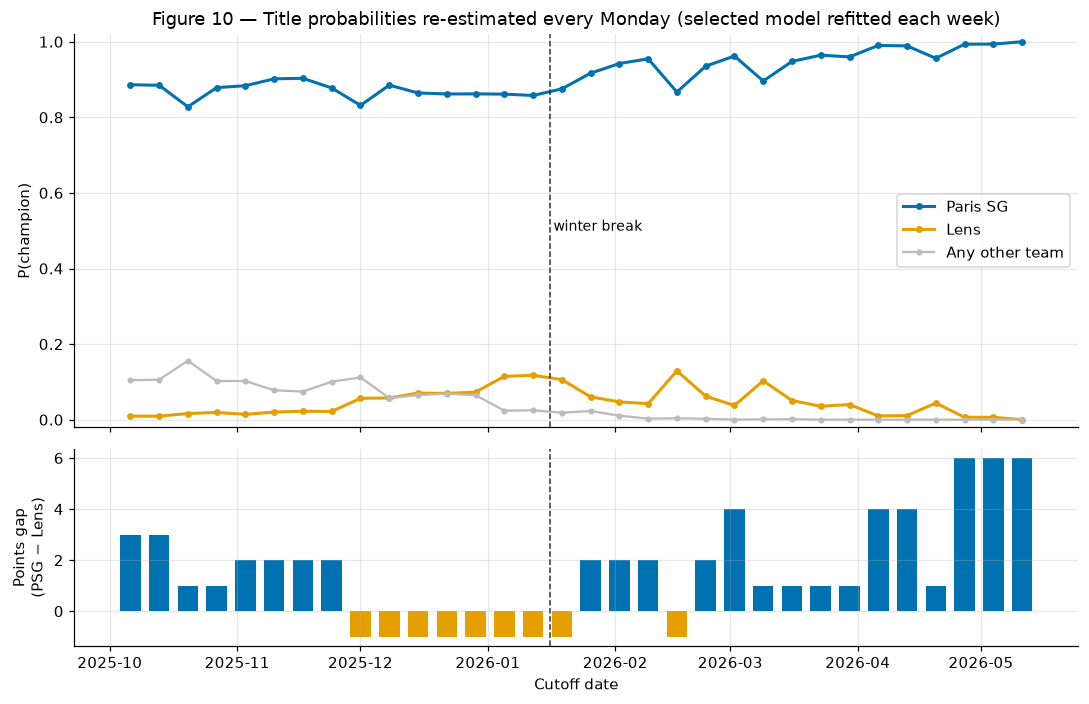

,date,PSG,Lens,ΔP(PSG),results effect,refit effect
19,2026-02-16,0.8669,0.1292,-0.0879,-0.0689,-0.0191
20,2026-02-23,0.9354,0.0622,0.0685,0.0647,0.0038
22,2026-03-09,0.8961,0.1029,-0.0661,-0.0552,-0.0109
2,2025-10-20,0.8278,0.0163,-0.0571,-0.0378,-0.0192
9,2025-12-08,0.8851,0.0574,0.0535,0.0402,0.0134


Mean |weekly move| before the winter break: results 0.019 | refit 0.007  (Monte Carlo noise on each term ≈ 0.005)
Mean |weekly move| after the winter break: results 0.028 | refit 0.004  (Monte Carlo noise on each term ≈ 0.005)
Last Monday before the cutoff (12 Jan 2026): P(PSG) = 0.858 | maximum of P(any other team) over the season: 0.156 on 20 Oct 2025 | minimum of P(PSG): 0.828 on 20 Oct 2025
Range of P(PSG) up to the end of March: 0.828 to 0.964 | P(any other team) on the last Monday before the cutoff: 0.025


In [29]:
cuts = pd.date_range("2025-10-06", "2026-05-11", freq="W-MON")
rng = make_rng(6)
film, model_prev = [], None
for cut in cuts:
    model_c = restrict(fit_with_history(2025, league[(league.season == 2025) & (league.date < cut)], RHO_STAR, STRUCTURE), TEAMS)
    state_c = season_state(cut)
    champ = simulate_seasons(model_c, state_c, 20_000, rng)[1] == 0
    # Last week's model applied to this week's standings: isolates the effect of the new results
    p_old_model = np.nan if model_prev is None else np.mean(simulate_seasons(model_prev, state_c, 20_000, rng)[1][:, PSG] == 0)
    model_prev = model_c
    film.append({"date": cut, "PSG": champ[:, PSG].mean(), "Lens": champ[:, LENS].mean(), "PSG_old_model": p_old_model,
                 "other": 1 - champ[:, PSG].mean() - champ[:, LENS].mean(),
                 "gap": int(state_c.base_pts[PSG] - state_c.base_pts[LENS]), "left": state_c.n_matches})
film = pd.DataFrame(film)

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]
ax.plot(film.date, film.PSG, color=COL["psg"], marker="o", ms=3.5, lw=2, label="Paris SG")
ax.plot(film.date, film.Lens, color=COL["lens"], marker="o", ms=3.5, lw=2, label="Lens")
ax.plot(film.date, film.other, color=COL["other"], marker="o", ms=3, lw=1.5, label="Any other team")
ax.set(ylabel="P(champion)", ylim=(-0.02, 1.02),
       title="Figure 10 — Title probabilities re-estimated every Monday (selected model refitted each week)")
ax.legend(loc="center right")
ax = axes[1]
ax.bar(film.date, film.gap, width=5, color=np.where(film.gap >= 0, COL["psg"], COL["lens"]))
ax.set(ylabel="Points gap\n(PSG − Lens)", xlabel="Cutoff date")
for a_ in axes:
    a_.axvline(CUTOFF, color=COL["exact"], ls="--", lw=1)
axes[0].text(CUTOFF, 0.5, " winter break", fontsize=9)
plt.tight_layout()
plt.show()

# Decompose each weekly move of P(PSG champion):
#   results effect = P(old model, new standings) - P(old model, old standings)
#   refit effect   = P(new model, new standings) - P(old model, new standings)
film["ΔP(PSG)"] = film.PSG.diff()
film["results effect"] = film.PSG_old_model - film.PSG.shift()
film["refit effect"] = film.PSG - film.PSG_old_model
display(film.loc[film["ΔP(PSG)"].abs().nlargest(5).index, ["date", "PSG", "Lens", "ΔP(PSG)", "results effect", "refit effect"]])
before, after = film.date < CUTOFF, film.date >= CUTOFF
for label, mask in (("before the winter break", before), ("after the winter break", after)):
    print(f"Mean |weekly move| {label}: results {film.loc[mask, 'results effect'].abs().mean():.3f} | "
          f"refit {film.loc[mask, 'refit effect'].abs().mean():.3f}  (Monte Carlo noise on each term ≈ 0.005)")
last = film[film.date < CUTOFF].iloc[-1]
print(f"Last Monday before the cutoff ({last.date:%d %b %Y}): P(PSG) = {last.PSG:.3f} | "
      f"maximum of P(any other team) over the season: {film.other.max():.3f} on {film.date[film.other.idxmax()]:%d %b %Y} | "
      f"minimum of P(PSG): {film.PSG.min():.3f} on {film.date[film.PSG.idxmin()]:%d %b %Y}")
print(f"Range of P(PSG) up to the end of March: {film.PSG[film.date < '2026-04-01'].min():.3f} to "
      f"{film.PSG[film.date < '2026-04-01'].max():.3f} | P(any other team) on the last Monday before the cutoff: {last.other:.3f}")

#### What do we observe?

- **With ten seasons of history, the film is calm.** Up to the end of March, Paris SG's title probability stays between $0.83$ and $0.96$; its largest weekly move is $-0.088$ (16 February, when Lens briefly retook the lead), immediately followed by $+0.069$.
- **Results move the probability, refits hardly do.** Each weekly move has two causes: the new results (the table changes) and the refit (the model, re-estimated with one more matchday, changes). Applying last week's model to this week's standings separates them: the refit effect is small all season ($0.007$ per week on average before the winter break, $0.004$ after, close to the Monte Carlo noise of $\approx 0.005$), while the results move the probability by $0.019$ and $0.028$ per week. With 17 matches per team, one more matchday would visibly move the strength estimates; with ten seasons behind them, it barely does. This is Section 4.3 observed in real time: more data, less parameter noise.
- **Early in the season the race was more open to others** (up to 16% for "any other team" on 20 October); by the winter break this mass had fallen to 2.5%. From March onwards Paris SG's probability rose towards 1 as the remaining matches — and thus the remaining randomness — disappeared.
- The estimate on the last Monday before the cutoff ($0.858$ on 12 January) agrees with the main result ($0.857$), as it should: no match was played between 12 and 16 January.
- **Practical lesson.** A "supercomputer" probability that moves from week to week deserves to be decomposed: part of the move is information (results), part is noise in the model's inputs — and the second part is what more data removes.

### 4.5 — Is the input model any good? Calibration on the second half

Paris SG did win the title (76 points against 70 for Lens). This **single outcome neither validates nor refutes** a title probability: an event of probability $0.86$ fails 14% of the time. What can be checked is the model's match-level forecasts: the winter-break model predicted a probability for each of the 153 second-half results, and those results are now known. This is the final check announced in Section 2.6: the second half of 2025/26 played no role in the choice of the model.

We use the **Brier score** $\frac{1}{M}\sum_m \sum_{k \in \{H, D, A\}} (\hat q_{m,k} - o_{m,k})^2$, where $\hat q_{m,k}$ is the forecast probability of outcome $k$ and $o_{m,k} \in \{0, 1\}$ indicates the realised outcome (lower is better; $2/3$ for uniform guessing), the **log-score** of the exact scoreline (Section 2.6), and a **reliability diagram**: among the outcomes forecast with probability about $q$, a calibrated model sees a fraction about $q$ occur.

Brier score — uniform: 0.667 | first-half frequencies (H/D/A = [0.5  0.22 0.28]): 0.667 | M4, 2025/26 only: 0.630 | selected model: 0.612
  Brier improvement, M4 2025/26 only vs frequencies: 0.036 ± 0.050 (95% CLT, paired over matches)
  Brier improvement, selected vs frequencies: 0.055 ± 0.044 (95% CLT, paired over matches)
  Brier improvement, selected vs M4 2025/26 only: 0.018 ± 0.029 (95% CLT, paired over matches)
Log-score — M4 2025/26 only: -3.1134 | selected: -3.0388 | difference +0.0746 ± 0.0665
Paired Brier differences (M4 vs frequencies): sd 0.32 per match → about 291 matches (≈ 1.9 half-seasons) needed for a 95% interval to exclude 0 if the true gain is 0.036
 M4, 2025/26 only: lowest bin forecast 0.109 / observed 0.195 | highest bin forecast 0.688 / observed 0.545
   Selected model: lowest bin forecast 0.155 / observed 0.169 | highest bin forecast 0.618 / observed 0.558


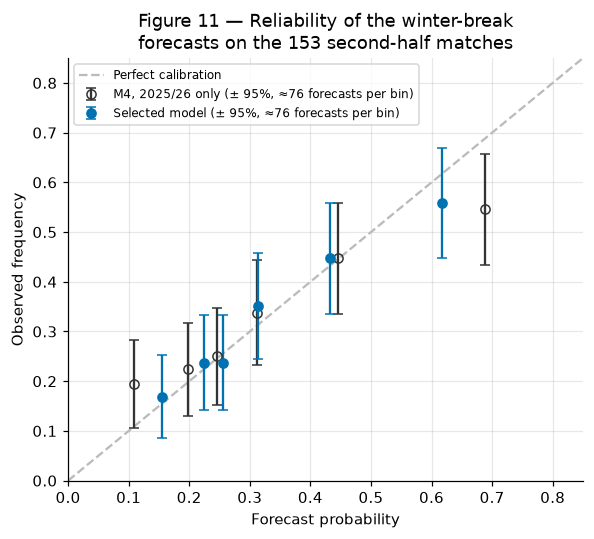

In [30]:
q_model = np.column_stack([P_HOME, P_DRAW, P_AWAY])  # selected model, winter-break forecasts for the second half
q_ws = np.column_stack(outcome_probs(*model_ws.rates(state.h, state.a)))  # M4, current season only
realised = outcome_index(remaining)
o = np.eye(3)[realised]
q_base = np.bincount(outcome_index(played), minlength=3) / len(played)

brier_model = ((q_model - o) ** 2).sum(axis=1)
brier_ws = ((q_ws - o) ** 2).sum(axis=1)
brier_base = ((q_base - o) ** 2).sum(axis=1)
print(f"Brier score — uniform: {2 / 3:.3f} | first-half frequencies (H/D/A = {q_base.round(2)}): {brier_base.mean():.3f} "
      f"| M4, 2025/26 only: {brier_ws.mean():.3f} | selected model: {brier_model.mean():.3f}")
for label, d_ in (("M4 2025/26 only vs frequencies", brier_base - brier_ws), ("selected vs frequencies", brier_base - brier_model),
                  ("selected vs M4 2025/26 only", brier_ws - brier_model)):
    print(f"  Brier improvement, {label}: {d_.mean():.3f} ± {z * d_.std(ddof=1) / np.sqrt(d_.size):.3f} (95% CLT, paired over matches)")
ls_main_25 = match_log_lik(model, rh_, ra_, rhg_, rag_)
d_ls = ls_main_25 - ls_25["M4"]
print(f"Log-score — M4 2025/26 only: {ls_25['M4'].mean():.4f} | selected: {ls_main_25.mean():.4f} | "
      f"difference {d_ls.mean():+.4f} ± {z * d_ls.std(ddof=1) / np.sqrt(d_ls.size):.4f}")

# Statistical power: how many matches would be needed to detect the improvement of M4 over frequencies?
d_power = brier_base - brier_ws
n_needed = (z * d_power.std(ddof=1) / d_power.mean()) ** 2
print(f"Paired Brier differences (M4 vs frequencies): sd {d_power.std(ddof=1):.2f} per match → about {n_needed:.0f} matches "
      f"(≈ {n_needed / 153:.1f} half-seasons) needed for a 95% interval to exclude 0 if the true gain is {d_power.mean():.3f}")

# Reliability diagram: all (forecast, outcome) pairs, equal-count bins
o_flat = o.ravel()


def reliability(q_: np.ndarray, n_bins: int = 6):
    """Mean forecast, observed frequency and count in equal-count bins of the forecast probabilities."""
    qf = q_.ravel()
    bins_ = np.clip(np.searchsorted(np.quantile(qf, np.linspace(0, 1, n_bins + 1)), qf, side="right") - 1, 0, n_bins - 1)
    return (np.array([qf[bins_ == k].mean() for k in range(n_bins)]), np.array([o_flat[bins_ == k].mean() for k in range(n_bins)]),
            np.array([(bins_ == k).sum() for k in range(n_bins)]))


fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], color=COL["other"], ls="--", label="Perfect calibration")
for q_, label, color, mfc in ((q_ws, "M4, 2025/26 only", COL["exact"], "none"), (q_model, "Selected model", COL["psg"], COL["psg"])):
    mean_q, freq, cnt = reliability(q_)
    ax.errorbar(mean_q, freq, yerr=z * np.sqrt(freq * (1 - freq) / cnt), fmt="o", color=color, mfc=mfc, capsize=3,
                label=f"{label} (± 95%, ≈{cnt.mean():.0f} forecasts per bin)")
    print(f"{label:>17}: lowest bin forecast {mean_q[0]:.3f} / observed {freq[0]:.3f} | highest bin forecast {mean_q[-1]:.3f} / observed {freq[-1]:.3f}")
ax.set(xlim=(0, 0.85), ylim=(0, 0.85), xlabel="Forecast probability", ylabel="Observed frequency",
       title="Figure 11 — Reliability of the winter-break\nforecasts on the 153 second-half matches")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

#### What do we observe?

- **The selected model forecasts the second half significantly better than naive rules.** Its Brier score ($0.612$) beats uniform guessing and first-half frequencies (both $0.667$) by $0.055 \pm 0.044$, an improvement whose 95% interval excludes zero. The within-season M4 ($0.630$) does not reach significance ($0.036 \pm 0.050$).
- **Selected vs within-season.** The Brier difference, $0.018 \pm 0.029$, is not significant on 153 matches; the log-score of the exact scoreline, $+0.075 \pm 0.067$, is. The finer criterion again separates models that the Brier score cannot, and confirms — on data never used to choose — the ranking of the backtest.
- **Statistical power.** The paired Brier differences have a standard deviation of about $0.32$ per match, so detecting a true gain of $0.036$ at 95% requires about $290$ matches — two half-seasons, not one. This is why the model was chosen on 1 778 historical matches (Section 3.2) rather than on the 153 matches of a single half-season.
- **Calibration.** The within-season model is over-confident at the extremes: outcomes forecast at $\approx 0.69$ occurred only 55% of the time, and those forecast at $\approx 0.11$ occurred 19.5% of the time — the expected symptom of strengths estimated on small samples (strong teams look stronger than they are, "regression to the mean"). The selected model moves both bins towards the diagonal ($0.62$ forecast / $56\%$ observed, $0.155$ / $17\%$). With six bins, three dependent outcomes per match and 153 matches, this is suggestive, not conclusive.

### 4.6 — What the data cannot settle: sensitivity to the memory $\rho$

The backtest of Section 3.2 selected $\rho^* = $ 0.6, but it cannot distinguish $\rho^*$ from neighbouring values. A modelling choice that the data cannot settle is a source of uncertainty in its own right, outside both terms of Proposition 3. We recompute the answer for every $\rho$ (same structure, $N = 20\,000$ each, Monte Carlo radius $\pm 1$ point), and look at where the shift between the within-season and the selected model comes from.

In [31]:
rng = make_rng(10)
p_rho = {}
for rho in RHOS:
    champ_r = simulate_seasons(restrict(fit_with_history(2025, played_all, rho, STRUCTURE), TEAMS), state, 20_000, rng)[1] == 0
    p_rho[rho] = (champ_r[:, PSG].mean(), champ_r[:, LENS].mean())
display(pd.DataFrame({"backtest log-score": {r: mean_ls[(STRUCTURE, r, None)] for r in RHOS},
                      "P(PSG)": {r: p_rho[r][0] for r in RHOS}, "P(Lens)": {r: p_rho[r][1] for r in RHOS}}).rename_axis("ρ").T)
p_plateau = [p_rho[r][0] for r in PLATEAU]
print(f"P(PSG) over the ρ indistinguishable from ρ* ({PLATEAU.min()}–{PLATEAU.max()}): {min(p_plateau):.2f} to {max(p_plateau):.2f} "
      f"(N = 20 000 each, Monte Carlo sd ≤ {np.sqrt(0.25 / 20_000):.4f})")

# Where does the shift come from? Swap Lens's strengths between the two fits (approximate: μ and h differ)
for label, base_m, donor in (("M4 2025/26 only, Lens strengths from the selected model", model_ws, model),
                             ("selected model, Lens strengths from M4 2025/26 only", model, model_ws)):
    att_, dfn_ = base_m.att.copy(), base_m.dfn.copy()
    att_[LENS], dfn_[LENS] = donor.att[LENS], donor.dfn[LENS]
    swapped = PoissonModel(mu=base_m.mu, home=base_m.home, att=att_, dfn=dfn_)
    print(f"{label}: P(PSG) = {np.mean(simulate_seasons(swapped, state, 20_000, make_rng(13))[1][:, PSG] == 0):.2f}")
print(f"Overall strength a + d — Paris SG: {model_ws.att[PSG] + model_ws.dfn[PSG]:.2f} → {model.att[PSG] + model.dfn[PSG]:.2f} | "
      f"Lens: {model_ws.att[LENS] + model_ws.dfn[LENS]:.2f} → {model.att[LENS] + model.dfn[LENS]:.2f}")
n_seasons = {t: league[(league.season >= 2015) & (league.season < 2025) & (league.home == t)].season.nunique() for t in TEAMS}
print("Current teams with fewer than 3 seasons in the 10-season window:", {t: n for t, n in n_seasons.items() if n < 3})

ρ,0.0000,0.1000,0.2000,0.3000,0.4000,0.5000,0.6000,0.7000,0.8000,0.9000,1.0000
backtest log-score,-2.9740,-2.9437,-2.9282,-2.9196,-2.9147,-2.9121,-2.9115,-2.9135,-2.9188,-2.9279,-2.9405
P(PSG),0.5653,0.6674,0.7418,0.7912,0.8212,0.8365,0.8561,0.8727,0.8892,0.9100,0.9291
P(Lens),0.4046,0.2982,0.2238,0.1749,0.1514,0.1361,0.1200,0.1070,0.0936,0.0787,0.0633


P(PSG) over the ρ indistinguishable from ρ* (0.4–0.7): 0.82 to 0.87 (N = 20 000 each, Monte Carlo sd ≤ 0.0035)


M4 2025/26 only, Lens strengths from the selected model: P(PSG) = 0.81


selected model, Lens strengths from M4 2025/26 only: P(PSG) = 0.58
Overall strength a + d — Paris SG: 0.90 → 0.87 | Lens: 0.84 → 0.38
Current teams with fewer than 3 seasons in the 10-season window: {'Auxerre': 2, 'Le Havre': 2, 'Paris FC': 0}


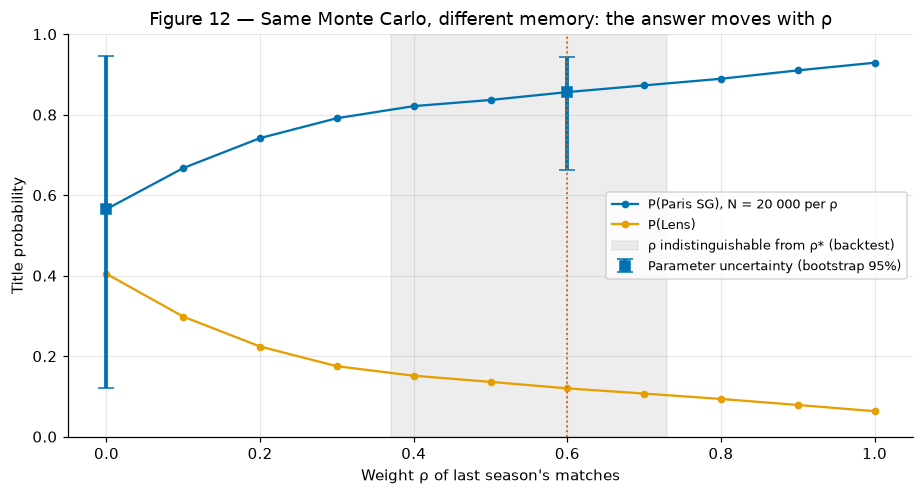

In [32]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(RHOS, [p_rho[r][0] for r in RHOS], color=COL["psg"], marker="o", ms=4, label="P(Paris SG), N = 20 000 per ρ")
ax.plot(RHOS, [p_rho[r][1] for r in RHOS], color=COL["lens"], marker="o", ms=4, label="P(Lens)")
for x, boot_, p_ in ((0.0, boot_ws[:, PSG], p_ws[PSG]), (RHO_STAR, boot_main[:, PSG], p_hat[PSG])):
    lo_hi = np.percentile(boot_, [2.5, 97.5])
    ax.errorbar(x, p_, yerr=[[p_ - lo_hi[0]], [lo_hi[1] - p_]], fmt="s", color=COL["psg"], ms=7, capsize=5, lw=2.5,
                label="Parameter uncertainty (bootstrap 95%)" if x == 0 else None)
ax.axvline(RHO_STAR, color=COL["hoeff"], ls=":", lw=1.2)
ax.axvspan(PLATEAU.min() - 0.03, PLATEAU.max() + 0.03, color=COL["other"], alpha=0.25, label="ρ indistinguishable from ρ* (backtest)")
ax.set(xlabel="Weight ρ of last season's matches", ylabel="Title probability", ylim=(0, 1),
       title="Figure 12 — Same Monte Carlo, different memory: the answer moves with ρ")
ax.legend(fontsize=8.5, loc="center right")
plt.tight_layout()
plt.show()

#### What do we observe?

- **The answer moves with the memory.** $P(\text{PSG})$ rises monotonically with $\rho$, from $0.57$ (current season only) to $0.93$ ($\rho = 1$, strengths assumed constant over ten seasons). Across the values that the backtest cannot distinguish ($\rho = 0.4$ to $0.7$), it ranges from $0.82$ to $0.87$: a modelling choice that the data cannot settle moves the answer by 5 points — about 15 times the Monte Carlo standard deviation of these runs ($\le 0.0035$), and comparable to the parameter standard deviation ($0.073$).
- **The shift comes mostly from Lens.** Its overall strength $a + d$ falls from $0.84$ (current season only) to $0.38$ (selected), whereas Paris SG's barely moves ($0.90 \to 0.87$). Swapping only Lens's strengths between the two fits confirms it: the within-season model with Lens's selected strengths gives $P(\text{PSG}) = 0.81$; the selected model with Lens's within-season strengths gives $0.58$.
- **Thin histories.** Auxerre and Le Havre have only two seasons in the window and Paris FC none: their strengths rest mostly on the current season. None of them is involved in the title race.

### 4.7 — Static or drifting strengths?

So far $\hat\theta$ is fitted once and kept constant for the 153 simulated matches: no form, injuries or transfers. A simple alternative lets every attack and defence strength follow a **Gaussian random walk** during the remaining season: each match of team $i$ adds an independent $\mathcal N(0, \sigma^2)$ step to $a_i$ and another to $d_i$. Simulated results do not feed back into the strengths; the walk only widens the uncertainty about them as the season goes on.

**Choosing $\sigma$ without looking at 2025/26.** As for the structure and the memory, $\sigma$ is chosen by the backtest on the 10 past seasons, with the selected model fitted on each first half. Under the drift, the predictive law of a single match is a Poisson–lognormal mixture: if the match is the $t_i$-th remaining match of the home team and the $t_j$-th of the away team, $\log\lambda$ is shifted by $a$-steps of team $i$ minus $d$-steps of team $j$, a $\mathcal N\big(0, \sigma^2 (t_i + t_j)\big)$ variable, independent of the shift of $\log\nu$. Its probabilities are computed by Gauss–Hermite quadrature and scored by the log-score. The decision rule is the same as in Section 3.2: the drift is retained only if it beats the static model out of sample.

In [33]:
GH_X, GH_W = np.polynomial.hermite_e.hermegauss(30)
GH_W = GH_W / GH_W.sum()  # nodes and weights for E[f(U)], U ~ N(0, 1)


def drift_log_score(m: PoissonModel, df: pd.DataFrame, sd: float) -> np.ndarray:
    """Predictive log-probability of each scoreline when strengths follow a random walk of per-match sd `sd`."""
    lam_h, lam_a = m.rates(df.hi.to_numpy(), df.ai.to_numpy())
    step_h, step_a = team_steps(df.hi.to_numpy(), df.ai.to_numpy())
    s = sd * np.sqrt(step_h + step_a + 2)  # steps are 0-based: the t-th match carries t + 1 increments

    def mixed_pmf(x, lam):
        return poisson.pmf(x[:, None], lam[:, None] * np.exp(s[:, None] * GH_X[None, :])) @ GH_W

    return np.log(mixed_pmf(df.hg.to_numpy(), lam_h)) + np.log(mixed_pmf(df.ag.to_numpy(), lam_a))


SIGMAS = (0.0, 0.01, 0.02, 0.03, 0.04, 0.06, 0.08)
ls_drift = {sd: [] for sd in SIGMAS}
for season in range(2015, 2025):
    s_ = league[league.season == season].sort_values("date", kind="stable")
    split = s_.date.iloc[len(s_) // 2]
    first, second = s_[s_.date < split], s_[s_.date >= split]
    m_ = fit_with_history(season, first, RHO_STAR, STRUCTURE)
    for sd in SIGMAS:
        ls_drift[sd].append(drift_log_score(m_, second, sd))
ls_drift = {sd: np.concatenate(v) for sd, v in ls_drift.items()}
assert np.allclose(ls_drift[0.0], ls_bt[BEST])  # σ = 0 reproduces the static backtest
rows = []
for sd in SIGMAS:
    d_mean, d_rad = paired_ci(ls_drift[sd] - ls_drift[0.0], bt_season)
    rows.append({"σ": sd, "mean log-score": ls_drift[sd].mean(), "Δ vs static": d_mean, "95% radius (by season)": d_rad,
                 "seasons better than static": f"{sum(ls_drift[sd][bt_season == s_].mean() > ls_drift[0.0][bt_season == s_].mean() for s_ in seasons_bt)}/{len(seasons_bt)}"})
drift_table = pd.DataFrame(rows).set_index("σ")
display(drift_table.T)
SIGMA_STAR = max(SIGMAS, key=lambda sd: ls_drift[sd].mean())
keep_drift = drift_table.loc[SIGMA_STAR, "Δ vs static"] > drift_table.loc[SIGMA_STAR, "95% radius (by season)"]
print(f"σ* = {SIGMA_STAR} (argmax) | significant improvement over the static model: {keep_drift}")

# Consequence for the title race, same N as the main estimate
rows = []
for sd in (0.0, SIGMA_STAR, 2 * SIGMA_STAR):
    pts_d, pos_d = (pts_mc, pos_mc) if sd == 0 else simulate_seasons(model, state, N_MAIN, make_rng(18), batch=25_000, drift_sd=sd)
    rows.append({"σ": sd, "P(PSG)": np.mean(pos_d[:, PSG] == 0), "P(Lens)": np.mean(pos_d[:, LENS] == 0),
                 "P(other)": 1 - np.mean(pos_d[:, PSG] == 0) - np.mean(pos_d[:, LENS] == 0),
                 "sd of PSG final points": pts_d[:, PSG].std(), "sd of Lens final points": pts_d[:, LENS].std()})
display(pd.DataFrame(rows).set_index("σ"))

σ,0.0000,0.0100,0.0200,0.0300,0.0400,0.0600,0.0800
mean log-score,-2.9115,-2.9114,-2.9112,-2.9111,-2.9114,-2.9153,-2.9259
Δ vs static,0.0000,0.0001,0.0003,0.0005,0.0001,-0.0038,-0.0143
95% radius (by season),0.0000,0.0002,0.0009,0.0020,0.0035,0.0072,0.0115
seasons better than static,0/10,5/10,5/10,5/10,5/10,3/10,1/10


σ* = 0.03 (argmax) | significant improvement over the static model: False


,P(PSG),P(Lens),P(other),sd of PSG final points,sd of Lens final points
σ,,,,,
0.0000,0.8567,0.1195,0.0238,4.6892,5.1699
0.0300,0.8394,0.1310,0.0296,4.8987,5.3599
0.0600,0.7906,0.1591,0.0503,5.4594,5.9139


#### What do we observe?

- **The data do not ask for drift.** The backtest log-score is flat up to $\sigma \approx 0.04$ per match (best value $\sigma^* = 0.03$: $+0.0005 \pm 0.0020$, better than the static model in 5 seasons out of 10) and deteriorates beyond ($\sigma = 0.08$: $-0.014 \pm 0.012$). By the decision rule, **the static model is kept**; drift is reported as a sensitivity analysis.
- **Consequence for the title race.** With $\sigma^* = 0.03$ (after 17 matches, a strength has drifted by $0.03\sqrt{17} \approx 0.12$ in standard deviation), $P(\text{PSG})$ falls from $0.857$ to $0.839$ and the other teams gain ($0.024 \to 0.030$): uncertainty about future strengths spreads the final points (standard deviation of Paris SG's points $4.69 \to 4.90$) and helps the teams that trail. With $2\sigma^* = 0.06$, which the backtest rejects, $P(\text{PSG}) = 0.79$.
- **Interpretation.** A plausible drift moves the answer by about 2 points: less than the parameter uncertainty (standard deviation 7 points) and of the same order as the choice of memory (Section 4.6). Static strengths are a limitation of the model, but not the dominant one here.

### 4.8 — A Bayesian input model, sampled by Metropolis

Sections 3.2 and 4.3 answer "36 parameters for 153 matches" with **more data** (past seasons). The Bayesian answer is **shrinkage**: a prior $a_i, d_i \sim \mathcal N(0, \tau^2)$ pulls every team towards the average team, and the posterior $\pi(\theta \mid \text{data}) \propto L(\theta)\,\pi_0(\theta)$ describes the remaining uncertainty about $\theta$ directly — an alternative to the parametric bootstrap. We use the current season only (the setting where shrinkage matters), weak priors $\mathcal N(0, 10^2)$ on $\mu$ and $h$, and the prior scale $\tau^* = $ 0.3 selected by the backtest of Section 3.2 (the ridge variant is exactly the posterior mode of this model). The posterior has no closed form in 38 dimensions: we sample it with the random-walk Metropolis algorithm of Section 2.8, written with NumPy only and run on several chains at once.

**First, validate the sampler where the answer is known.** For a single team scoring $x_1, \dots, x_n$ goals, $x_k \sim \mathrm{Poisson}(\lambda)$, with a $\mathrm{Gamma}(\alpha, \beta)$ prior, the posterior is exactly $\mathrm{Gamma}(\alpha + \sum_k x_k, \beta + n)$. We run the same sampler on $u = \log\lambda$, whose target density includes the Jacobian $e^u$ of the change of variable.

In [34]:
def metropolis(log_target, theta0, n_iter: int, chol: np.ndarray, rng: np.random.Generator, thin: int = 1, keep=None):
    """Random-walk Metropolis on several chains at once (rows of theta0).

    Proposal theta' = theta + chol @ N(0, I); accept with probability min(1, pi(theta') / pi(theta)).
    Returns the kept draws (n_iter // thin, chains, ...) and the acceptance rate of each chain.
    """
    cur = np.array(theta0, dtype=float)
    lp_cur = log_target(cur)
    out, accepted = [], np.zeros(len(cur))
    for it in range(n_iter):
        prop = cur + rng.standard_normal(cur.shape) @ chol.T
        lp_prop = log_target(prop)
        accept = np.log(rng.random(len(cur))) < lp_prop - lp_cur  # the normalising constant cancels
        cur[accept], lp_cur[accept] = prop[accept], lp_prop[accept]
        accepted += accept
        if (it + 1) % thin == 0:
            out.append(cur.copy() if keep is None else keep(cur))
    return np.array(out), accepted / n_iter


def ess(x: np.ndarray) -> float:
    """Effective sample size S / (1 + 2 sum_k rho_k), autocorrelations summed by pairs while positive (Geyer)."""
    x = x - x.mean()
    n = x.size
    f = np.fft.rfft(x, 2 * n)
    acf = np.fft.irfft(f * np.conj(f))[:n]
    acf = acf / acf[0]
    tau = -1.0
    for m in range(n // 2 - 1):
        pair = acf[2 * m] + acf[2 * m + 1]
        if pair < 0:
            break
        tau += 2 * pair
    return n / tau


def r_hat(chains: np.ndarray) -> float:
    """Potential scale reduction factor (Gelman–Rubin) for draws of shape (S, chains)."""
    s = chains.shape[0]
    between = s * chains.mean(axis=0).var(ddof=1)
    within = chains.var(axis=0, ddof=1).mean()
    return float(np.sqrt(((s - 1) / s * within + between / s) / within))


# Toy check: Paris SG's goals in its 17 first-half matches, Gamma(2, 1) prior on its scoring rate
goals_psg = np.r_[played.hg[played.h == PSG], played.ag[played.a == PSG]]
alpha_0, beta_0 = 2.0, 1.0
post = gamma(alpha_0 + goals_psg.sum(), scale=1 / (beta_0 + goals_psg.size))


def log_target_toy(u):
    """Log posterior density of u = log(lambda), up to a constant (Jacobian e^u included)."""
    return ((alpha_0 + goals_psg.sum()) * u - (beta_0 + goals_psg.size) * np.exp(u)).sum(axis=1)


draws_toy, acc_toy = metropolis(log_target_toy, np.zeros((4, 1)), 20_000, np.array([[0.4]]), make_rng(19))
lam_toy = np.exp(draws_toy[2_000:, :, 0])  # burn-in removed
print(f"Toy posterior of Paris SG's scoring rate — acceptance {acc_toy.mean():.2f} | ESS {sum(ess(lam_toy[:, c]) for c in range(4)):.0f} "
      f"of {lam_toy.size:,} draws")
print(pd.DataFrame({"exact Gamma posterior": [post.mean(), post.std(), *post.ppf([0.025, 0.975])],
                    "Metropolis": [lam_toy.mean(), lam_toy.std(), *np.quantile(lam_toy, [0.025, 0.975])]},
                   index=["mean", "sd", "2.5% quantile", "97.5% quantile"]).T.to_string(float_format="{:.4f}".format))

Toy posterior of Paris SG's scoring rate — acceptance 0.43 | ESS 16380 of 72,000 draws
                        mean     sd  2.5% quantile  97.5% quantile
exact Gamma posterior 2.1667 0.3469         1.5407          2.8977
Metropolis            2.1649 0.3491         1.5382          2.9009


In [35]:
# Full model: theta = (mu, h, a_1..a_T, d_1..d_T), linear predictors eta = X theta for the 306 first-half scores
D_PAR = 2 + 2 * T
n1 = len(played)
X_ws = np.zeros((2 * n1, D_PAR))
r1 = np.arange(n1)
X_ws[r1, 0] = X_ws[r1, 1] = 1
X_ws[r1, 2 + ph_], X_ws[r1, 2 + T + pa_] = 1, -1
X_ws[n1 + r1, 0] = 1
X_ws[n1 + r1, 2 + pa_], X_ws[n1 + r1, 2 + T + ph_] = 1, -1
y_ws = np.r_[phg_, pag_]


def log_posterior(tau: float, sd_fixed: float = 10.0):
    """Log posterior (up to a constant) for chains theta of shape (C, D_PAR), and the prior precisions."""
    prec = np.r_[1 / sd_fixed**2, 1 / sd_fixed**2, np.full(2 * T, 1 / tau**2)]

    def log_post(theta):
        eta = theta @ X_ws.T
        return (y_ws * eta - np.exp(eta)).sum(axis=-1) - 0.5 * (theta**2 * prec).sum(axis=-1)

    return log_post, prec


def laplace(log_post, prec):
    """Posterior mode and inverse Hessian there (Gaussian approximation used to shape the proposal)."""
    def neg(th):
        return -log_post(th[None])[0], -(X_ws.T @ (y_ws - np.exp(X_ws @ th))) + prec * th

    mode = minimize(neg, np.zeros(D_PAR), jac=True, method="L-BFGS-B", options={"gtol": 1e-9}).x
    hessian = X_ws.T @ (np.exp(X_ws @ mode)[:, None] * X_ws) + np.diag(prec)
    return mode, np.linalg.inv(hessian)


def centred(theta):
    """Centred attack and defence strengths (identifiable quantities) from draws theta (..., D_PAR)."""
    att, dfn = theta[..., 2:2 + T], theta[..., 2 + T:]
    return att - att.mean(axis=-1, keepdims=True), dfn - dfn.mean(axis=-1, keepdims=True)


TAU_STAR = TAU_0
log_post, prec = log_posterior(TAU_STAR)
mode, cov_laplace = laplace(log_post, prec)
chol = np.linalg.cholesky(cov_laplace)

# Tuning: acceptance rate as a function of the step s (short pilot runs from the mode)
rng = make_rng(20)
pilot = {s: metropolis(log_post, np.tile(mode, (4, 1)), 2_000, s * chol, rng)[1].mean() for s in (0.2, 0.3, 0.39, 0.6, 1.0)}
print("Pilot acceptance rates by step s:", {s: round(a, 3) for s, a in pilot.items()}, f"| 2.38/√d = {2.38 / np.sqrt(D_PAR):.2f}")
STEP = 2.38 / np.sqrt(D_PAR)

# Main run: 4 chains from dispersed starting points (mode + 3 Laplace standard deviations)
N_CHAINS, N_ITER, BURN, THIN = 4, 60_000, 10_000, 10
start_ch = mode + 3 * rng.standard_normal((N_CHAINS, D_PAR)) @ chol.T
draws, acc = metropolis(log_post, start_ch, N_ITER, STEP * chol, rng, thin=THIN)
draws = draws[BURN // THIN:]  # (S, chains, D_PAR) after burn-in
att_c, dfn_c = centred(draws)
tracked = {"a(Paris SG)": att_c[..., PSG], "d(Lens)": dfn_c[..., LENS], "home advantage h": draws[..., 1]}
diag = pd.DataFrame({name: {"posterior mean": x.mean(), "posterior sd": x.std(),
                            "ESS (4 chains)": sum(ess(x[:, c]) for c in range(N_CHAINS)), "R-hat": r_hat(x)}
                     for name, x in tracked.items()}).T
all_par = np.concatenate([att_c, dfn_c, draws[..., :2]], axis=-1)
ess_all = np.array([sum(ess(all_par[:, c, j]) for c in range(N_CHAINS)) for j in range(all_par.shape[-1])])
rhat_all = np.array([r_hat(all_par[:, :, j]) for j in range(all_par.shape[-1])])
print(f"Acceptance per chain: {np.round(acc, 3)} | kept draws: {draws.shape[0]} per chain (after burn-in {BURN:,}, thinning {THIN})")
display(diag)
print(f"All {all_par.shape[-1]} parameters: ESS min {ess_all.min():.0f} / median {np.median(ess_all):.0f} "
      f"of {draws.shape[0] * N_CHAINS:,} kept draws | R-hat max {rhat_all.max():.3f}")

# Check (ii): with a very wide prior, the posterior mean approaches the maximum-likelihood estimate
lp_wide, prec_wide = log_posterior(10.0)
mode_w, cov_w = laplace(lp_wide, prec_wide)
draws_w, _ = metropolis(lp_wide, np.tile(mode_w, (N_CHAINS, 1)), 30_000, STEP * np.linalg.cholesky(cov_w), make_rng(21), thin=THIN)
att_w, dfn_w = centred(draws_w[500:])
gap_mle = np.abs(np.r_[att_w.mean(axis=(0, 1)) - model_ws.att, dfn_w.mean(axis=(0, 1)) - model_ws.dfn])
print(f"Wide prior (τ = 10): max |posterior mean − MLE| over the 36 strengths = {gap_mle.max():.3f} "
      f"(posterior sd of a strength ≈ {att_w.std(axis=(0, 1)).mean():.2f})")
print(f"Shrinkage with τ* = {TAU_STAR}: posterior mean of a(Paris SG) = {att_c[..., PSG].mean():.2f} vs MLE {model_ws.att[PSG]:.2f}; "
      f"d(Lens) = {dfn_c[..., LENS].mean():.2f} vs MLE {model_ws.dfn[LENS]:.2f}")

Pilot acceptance rates by step s: {0.2: np.float64(0.535), 0.3: np.float64(0.362), 0.39: np.float64(0.232), 0.6: np.float64(0.049), 1.0: np.float64(0.0)} | 2.38/√d = 0.39


Acceptance per chain: [0.244 0.24  0.242 0.24 ] | kept draws: 5000 per chain (after burn-in 10,000, thinning 10)


,posterior mean,posterior sd,ESS (4 chains),R-hat
a(Paris SG),0.3427,0.1498,1503.0682,1.0025
d(Lens),0.3403,0.1839,1595.7950,1.0004
home advantage h,0.3740,0.0965,1773.9017,1.0006


All 38 parameters: ESS min 1485 / median 1668 of 20,000 kept draws | R-hat max 1.004


Wide prior (τ = 10): max |posterior mean − MLE| over the 36 strengths = 0.022 (posterior sd of a strength ≈ 0.20)
Shrinkage with τ* = 0.3: posterior mean of a(Paris SG) = 0.34 vs MLE 0.47; d(Lens) = 0.34 vs MLE 0.56


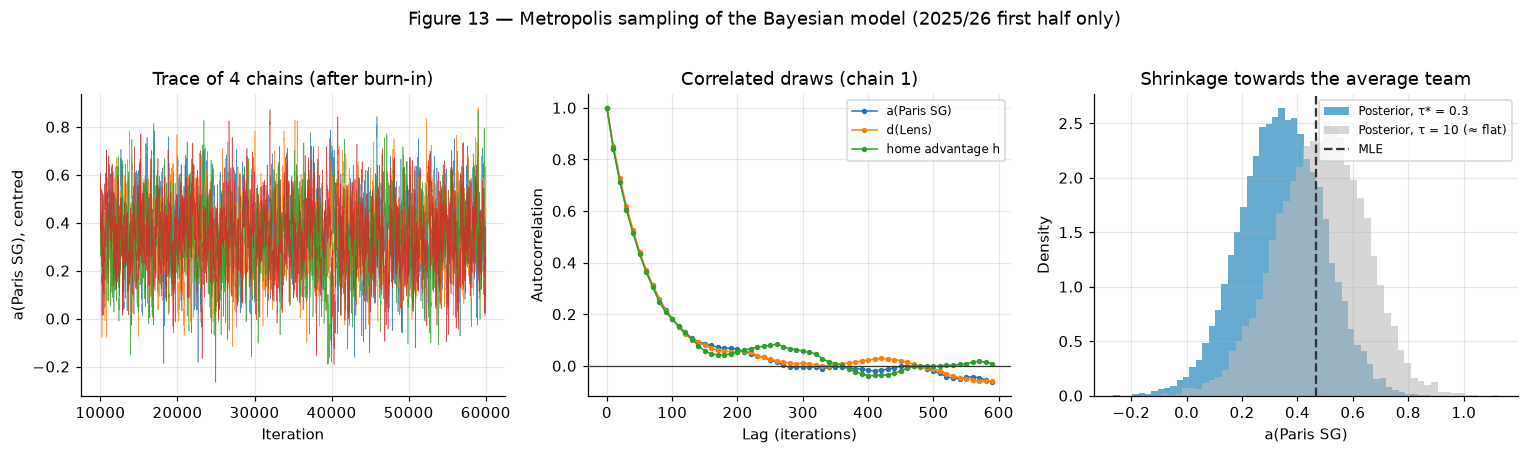

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ax = axes[0]
for c in range(N_CHAINS):
    ax.plot(np.arange(draws.shape[0]) * THIN + BURN, tracked["a(Paris SG)"][:, c], lw=0.4, alpha=0.8)
ax.set(xlabel="Iteration", ylabel="a(Paris SG), centred", title="Trace of 4 chains (after burn-in)")
ax = axes[1]
for name, x in tracked.items():
    xc = x[:, 0] - x[:, 0].mean()
    acf = np.correlate(xc, xc, mode="full")[xc.size - 1:][:60] / (xc @ xc)
    ax.plot(np.arange(60) * THIN, acf, marker="o", ms=2.5, lw=1, label=name)
ax.axhline(0, color=COL["exact"], lw=0.8)
ax.set(xlabel="Lag (iterations)", ylabel="Autocorrelation", title="Correlated draws (chain 1)")
ax.legend(fontsize=8)
ax = axes[2]
ax.hist(att_c[..., PSG].ravel(), bins=50, density=True, color=COL["psg"], alpha=0.6, label=f"Posterior, τ* = {TAU_STAR}")
ax.hist(att_w[..., PSG].ravel(), bins=50, density=True, color=COL["other"], alpha=0.6, label="Posterior, τ = 10 (≈ flat)")
ax.axvline(model_ws.att[PSG], color=COL["exact"], ls="--", label="MLE")
ax.set(xlabel="a(Paris SG)", ylabel="Density", title="Shrinkage towards the average team")
ax.legend(fontsize=8)
fig.suptitle("Figure 13 — Metropolis sampling of the Bayesian model (2025/26 first half only)", y=1.02)
plt.tight_layout()
plt.show()

**Why ESS matters: the coverage of naive intervals.** We run 200 independent chains of $S = 5\,000$ iterations each (after a burn-in from Laplace draws), estimate the posterior mean of $a(\text{Paris SG})$ on each chain, and attach a 95% CLT interval computed either with $S$ — as if the draws were independent — or with the chain's own ESS. The reference value pools all 200 chains.

In [37]:
R_CH, S_CH, BURN_CH = 200, 5_000, 2_000
rng = make_rng(22)
start_ch = mode + rng.standard_normal((R_CH, D_PAR)) @ chol.T
trace_psg, _ = metropolis(log_post, start_ch, BURN_CH + S_CH, STEP * chol, rng,
                          keep=lambda th: th[:, 2 + PSG] - th[:, 2:2 + T].mean(axis=1))
trace_psg = trace_psg[BURN_CH:]  # (S, R_CH)
ref = trace_psg.mean()
est_ch, sd_ch = trace_psg.mean(axis=0), trace_psg.std(axis=0, ddof=1)
ess_ch = np.array([ess(trace_psg[:, c]) for c in range(R_CH)])
cover_naive = np.mean(np.abs(est_ch - ref) <= z * sd_ch / np.sqrt(S_CH))
cover_ess = np.mean(np.abs(est_ch - ref) <= z * sd_ch / np.sqrt(ess_ch))
print(f"{R_CH} chains of S = {S_CH:,}: median ESS {np.median(ess_ch):.0f} (S / ESS ≈ {S_CH / np.median(ess_ch):.0f})")
print(f"Coverage of nominal 95% intervals — with S: {cover_naive:.1%} | with ESS: {cover_ess:.1%} "
      f"(± {z * np.sqrt(0.95 * 0.05 / R_CH):.1%} from the {R_CH} chains)")

200 chains of S = 5,000: median ESS 47 (S / ESS ≈ 106)
Coverage of nominal 95% intervals — with S: 10.5% | with ESS: 90.5% (± 3.0% from the 200 chains)


**Two-level Monte Carlo for the title probability.** The posterior predictive title probability averages $p(\theta)$ over the posterior: $P(C \mid \text{data}) = \int p(\theta)\,\pi(\theta \mid \text{data})\,d\theta$. It is a Monte Carlo estimate **of a Monte Carlo estimate**: an outer level draws $\theta^{(s)}$ from the chains (thinned, so that successive draws are nearly independent), an inner level simulates $N'$ seasons for each. Proposition 3, applied with $V = \theta^{(s)}$, splits the variance of the inner estimates into a within-draw (simulation) term and a between-draw (posterior) term.

In [38]:
S_OUT, N_INNER = 400, 2_000
flat = draws.reshape(-1, D_PAR)
theta_s = flat[np.linspace(0, len(flat) - 1, S_OUT).astype(int)]
rng = make_rng(23)
p_s = np.empty((S_OUT, T))
q_post = np.zeros((state.n_matches, 3))
lik_post = np.zeros(state.n_matches)
for k, th in enumerate(theta_s):
    att_k, dfn_k = centred(th)
    m_k = PoissonModel(mu=th[0] + th[2:2 + T].mean() - th[2 + T:].mean(), home=th[1], att=att_k, dfn=dfn_k)
    p_s[k] = (simulate_seasons(m_k, state, N_INNER, rng)[1] == 0).mean(axis=0)
    q_post += np.column_stack(outcome_probs(*m_k.rates(state.h, state.a))) / S_OUT
    lik_post += np.exp(match_log_lik(m_k, rh_, ra_, rhg_, rag_)) / S_OUT
var_within = np.mean(p_s[:, PSG] * (1 - p_s[:, PSG])) / (N_INNER - 1)
var_between = p_s[:, PSG].var(ddof=1) - var_within
p_post = p_s.mean(axis=0)
sd_post = np.sqrt(max(var_between, 0))
print(f"Posterior predictive P(PSG champion) = {p_post[PSG]:.3f} ± {z * p_s[:, PSG].std(ddof=1) / np.sqrt(S_OUT):.3f} "
      f"(95%, outer level) | P(Lens) = {p_post[LENS]:.3f}")
print(f"Variance of the inner estimates: within draws (simulation, N' = {N_INNER:,}) {var_within:.5f} + "
      f"between draws (posterior) {var_between:.5f} → posterior sd of p(θ) = {sd_post:.3f}")
brier_post = ((q_post - o) ** 2).sum(axis=1)
ls_post = np.log(lik_post)
summary_unc = pd.DataFrame({
    "P(PSG)": [p_ws[PSG], p_post[PSG], p_hat[PSG]],
    "sd of p(θ)": [sd_param_ws, sd_post, sd_param_main],
    "Brier 2025/26 second half": [brier_ws.mean(), brier_post.mean(), brier_model.mean()],
    "log-score 2025/26 second half": [ls_25["M4"].mean(), ls_post.mean(), ls_main_25.mean()],
}, index=["MLE, 2025/26 only (bootstrap)", f"Bayes, 2025/26 only, τ* = {TAU_STAR} (posterior)",
          f"MLE with history, ρ* = {RHO_STAR} (bootstrap)"])
display(summary_unc)
d_post = ls_post - ls_25["M4"]
print(f"Log-score, posterior predictive vs MLE (2025/26 only): {d_post.mean():+.4f} ± {z * d_post.std(ddof=1) / np.sqrt(d_post.size):.4f}")

Posterior predictive P(PSG champion) = 0.512 ± 0.021 (95%, outer level) | P(Lens) = 0.391
Variance of the inner estimates: within draws (simulation, N' = 2,000) 0.00010 + between draws (posterior) 0.04790 → posterior sd of p(θ) = 0.219


,P(PSG),sd of p(θ),Brier 2025/26 second half,log-score 2025/26 second half
"MLE, 2025/26 only (bootstrap)",0.5665,0.2314,0.6303,-3.1134
"Bayes, 2025/26 only, τ* = 0.3 (posterior)",0.5121,0.2189,0.6224,-3.0625
"MLE with history, ρ* = 0.6 (bootstrap)",0.8567,0.0733,0.6121,-3.0388


Log-score, posterior predictive vs MLE (2025/26 only): +0.0509 ± 0.0363


#### What do we observe?

- **The sampler is validated where the answer is known.** On the one-team Gamma–Poisson posterior, Metropolis reproduces the exact mean, standard deviation and quantiles to within $0.004$ (acceptance $0.43$, close to the one-dimensional optimum $\approx 0.44$). On the full model with a very wide prior, the posterior means are within $0.022$ of the maximum-likelihood estimates (posterior standard deviation of a strength $\approx 0.20$): the MLE is the flat-prior limit of the Bayesian model.
- **Tuning and diagnostics.** The pilot runs show the trade-off of Section 2.8: acceptance falls from $0.54$ to $0$ as the step grows from $0.2$ to $1$, and the theoretical step $2.38/\sqrt{38} = 0.39$ gives $0.23$, the classical optimum. Four chains started three standard deviations away from the mode agree ($\hat R \le 1.004$) and their traces overlap (Figure 13). But the draws are strongly correlated — autocorrelations vanish only after about 200 iterations — and the 200 000 post-burn-in iterations of each parameter (20 000 kept after thinning) are worth an ESS of about 1 500 to 1 800 independent draws: under 1% of the iterations, as expected for a random walk in 38 dimensions.
- **ESS, not $S$.** Over 200 independent chains, intervals built with $S$ contain the reference value in only 10.5% of cases: with $S/\mathrm{ESS} \approx 106$, they are ten times too narrow. With the ESS, the coverage is 90.5% ($\pm 3.0$), close to the nominal 95% — slightly below, because an ESS estimated on a single short chain is itself noisy. The radii of Chapter 1 apply to Markov chains only with ESS in place of $S$.
- **Shrinkage improves the forecasts, not the certainty about the title.** The prior pulls the extreme strengths towards the average (Paris SG's attack $0.47 \to 0.34$, Lens's defence $0.56 \to 0.34$) and improves the forecasts of the 2025/26 second half (log-score $+0.051 \pm 0.036$ over the MLE, Brier $0.630 \to 0.622$). But the posterior predictive title probability, $0.51$, comes with a posterior standard deviation of $p(\theta)$ of $0.22$ — almost the bootstrap's $0.23$. With 17 matches per team, a prior cannot create information; only history reduced the uncertainty ($0.073$), and the model with history also forecasts best (log-score $-3.039$ against $-3.063$).
- **Two-level Monte Carlo.** The inner simulations contribute a variance of $0.0001$ against $0.048$ for the posterior: as in Section 4.3, the simulation error is negligible. The two measures of parameter uncertainty, frequentist (bootstrap, $0.23$) and Bayesian (posterior, $0.22$), agree although they rest on different principles.
- **Decision.** The Bayesian model remains a complementary analysis: on the current season alone it is better than the MLE, but it does not beat the selected model with history out of sample, and it confirms rather than changes the conclusion on the size of the uncertainty.

---
## 5 — Limitations and conclusions

### 5.1 — Assumptions and what they imply

**Limits of the input model:**
- *Independence of the two scores* within a match: in reality low scores are correlated and draws are slightly more frequent than the Poisson product predicts (Dixon & Coles, 1997).
- *Independence across matches and static strengths*: form, injuries, the January transfer window, fatigue from European competitions and motivation at the end of the season are all ignored. A random-walk drift of the strengths is not supported by the backtest and moves the answer by about 2 points (Section 4.7); richer dynamic models are beyond our scope.
- *Poisson equidispersion*: the variance of goals equals their mean. The Pearson checks give $1.11$ for the within-season fit ($\pm 0.17$) and $1.02$ for the selected model: no evidence against it, but an assumption nonetheless.
- *Information*: 36 parameters from 153 matches are not supported by the data (Section 3.2). History repairs this at the price of new assumptions: strengths held constant across the weighted seasons in the bootstrap, a memory $\rho$ that the backtest only pins down to $0.4$–$0.7$, and only current-season information for Paris FC.
- *Model selection*: the structure and the memory were chosen on the same backtest that evaluates them, so the reported out-of-sample gains are slightly optimistic; the 2025/26 second half, never used to choose, confirms the ranking.
- *Tie-breaks*: beyond goal difference, the six remaining official criteria (head-to-head points and goal difference, best attack, most wins, most away wins, fewest cards) are replaced by a random draw; this affects 0.05% of seasons (Section 3.3).
- *Simultaneous estimates*: the union bound treats the 18 title probabilities as unrelated, although they sum to 1; it is valid but conservative.

**Limits of the Monte Carlo method itself:**
- *Monte Carlo is exact for the model, not for the world.* It estimates $p(\hat\theta)$; its error bars say nothing about whether $\hat\theta$, or the model, is right. Reporting "85.7% ± 0.5" without the model uncertainty is technically correct and practically misleading.
- *Slow convergence*: the $1/\sqrt N$ rate means each extra digit costs 100 times more computation. It is harmless here (150 000 seasons take a few seconds) but decisive for expensive simulators.
- *Guarantees are pointwise in $N$*: monitoring a running estimate and stopping when it "looks stable" is not covered by fixed-$N$ confidence intervals.
- *Markov chains*: MCMC draws are correlated (an ESS of under 1% of the iterations in Section 4.8), and convergence can be diagnosed, not proven.
- *Rare events*: absolute precision is not relative precision. This last point deserves a demonstration.

### 5.2 — When plain Monte Carlo fails: rare events

Proposition 1 gives an **absolute** error $\sqrt{p(1-p)/N}$. For small $p$ the relevant measure is the **relative** error

$$\frac{\sqrt{\operatorname{Var}[\hat p_N]}}{p} = \sqrt{\frac{1-p}{Np}} \approx \frac{1}{\sqrt{Np}},$$

so a 10% relative error requires $N \approx 100/p$ simulations: $10^7$ for $p = 10^{-5}$. With $N \lesssim 1/p$, the estimate is most often exactly $0$ (probability $(1-p)^N \approx e^{-Np}$), and the CLT interval collapses to $\{0\}$.

We first illustrate this on a question that can be answered exactly: **the probability that Paris SG collapses**, earning at most $s$ points in its last 17 matches, where $s$ is the largest threshold for which this probability is at most $10^{-5}$.

**Importance sampling** (Owen, 2013) draws from a different distribution $Q$ under which the rare event is frequent, and corrects with the likelihood ratio:

$$P(A) = \mathbb{E}_P[\mathbf{1}_A] = \mathbb{E}_Q\Big[\mathbf{1}_A \frac{dP}{dQ}\Big], \qquad \hat p^{\,\mathrm{IS}}_N = \frac1N\sum_{i=1}^N \mathbf{1}_A(W_i)\,\frac{dP}{dQ}(W_i), \quad W_i \sim Q,$$

which is unbiased as soon as $Q$ charges every outcome that $P$ charges. We **tilt** each match: outcome $k$ (worth $\mathrm{pts}_k \in \{0, 1, 3\}$ to PSG) receives probability $q_{m,k} \propto p_{m,k}\, e^{-t\,\mathrm{pts}_k}$, with $t > 0$ chosen so that PSG earns $s$ points on average under $Q$. The likelihood ratio of a season in which PSG earns $S$ points is then explicit: $\frac{dP}{dQ} = e^{tS}\prod_m \big(\sum_k p_{m,k} e^{-t\,\mathrm{pts}_k}\big)$.

In [39]:
POINTS = np.array([0, 1, 3])
psg_matches = np.flatnonzero((state.h == PSG) | (state.a == PSG))
p_out = np.column_stack([
    np.where(state.h[psg_matches] == PSG, P_AWAY[psg_matches], P_HOME[psg_matches]),  # PSG loses
    P_DRAW[psg_matches],
    np.where(state.h[psg_matches] == PSG, P_HOME[psg_matches], P_AWAY[psg_matches]),  # PSG wins
])
p_out /= p_out.sum(axis=1, keepdims=True)

cdf = np.cumsum(points_pmf(PSG, np.ones(state.n_matches, dtype=bool)))
s_star = int(np.flatnonzero(cdf <= 1e-5)[-1])
p_rare = cdf[s_star]


def tilt(t: float):
    """Tilted outcome probabilities and log normalising constants for PSG's 17 matches."""
    w = p_out * np.exp(-t * POINTS)
    return w / w.sum(axis=1, keepdims=True), np.log(w.sum(axis=1))


t_star = brentq(lambda t: (tilt(t)[0] @ POINTS).sum() - s_star, 0, 20)
q_out, log_norm = tilt(t_star)


def sample_points(probs: np.ndarray, n: int, rng: np.random.Generator) -> np.ndarray:
    """Total PSG points over its matches, outcomes drawn independently with the given probabilities."""
    k = (rng.random((n, probs.shape[0], 1)) > np.cumsum(probs, axis=1)[None, :, :-1]).sum(axis=2)
    return POINTS[k].sum(axis=1)


R_RARE, N_RARE = 300, 10_000
rng = make_rng(7)
naive = np.array([(sample_points(p_out, N_RARE, rng) <= s_star).mean() for _ in range(R_RARE)])
is_est = np.empty(R_RARE)
for r_ in range(R_RARE):
    s_pts = sample_points(q_out, N_RARE, rng)
    is_est[r_] = np.mean((s_pts <= s_star) * np.exp(t_star * s_pts + log_norm.sum()))

print(f"Rare event: Paris SG earns at most {s_star} points in its last {len(psg_matches)} matches")
print(f"Exact probability (convolution): {p_rare:.3e} | tilting parameter t = {t_star:.3f}")
for name, est in (("Plain Monte Carlo", naive), ("Importance sampling", is_est)):
    print(f"{name:>20}: mean = {est.mean():.3e} | relative error (sd / p) = {est.std(ddof=1) / p_rare:6.3f} "
          f"| runs returning 0: {np.mean(est == 0):.0%}")
print(f"Variance reduction factor: {naive.var(ddof=1) / is_est.var(ddof=1):,.0f} "
      f"(theory for plain Monte Carlo: relative error = sqrt((1 - p) / (N p)) = {np.sqrt((1 - p_rare) / (N_RARE * p_rare)):.2f})")

Rare event: Paris SG earns at most 15 points in its last 17 matches
Exact probability (convolution): 4.737e-06 | tilting parameter t = 0.908
   Plain Monte Carlo: mean = 4.000e-06 | relative error (sd / p) =  4.489 | runs returning 0: 96%
 Importance sampling: mean = 4.746e-06 | relative error (sd / p) =  0.021 | runs returning 0: 0%
Variance reduction factor: 46,075 (theory for plain Monte Carlo: relative error = sqrt((1 - p) / (N p)) = 4.59)


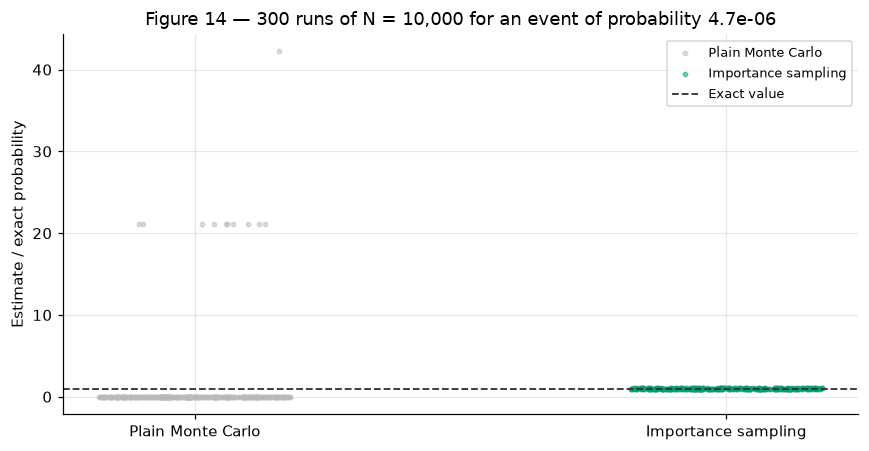

In [40]:
fig, ax = plt.subplots(figsize=(8, 4.2))
jitter = make_rng(8).uniform(-0.18, 0.18, R_RARE)
ax.scatter(0 + jitter, naive / p_rare, s=8, alpha=0.5, color=COL["other"], label="Plain Monte Carlo")
ax.scatter(1 + jitter, is_est / p_rare, s=8, alpha=0.5, color=COL["mc"], label="Importance sampling")
ax.axhline(1, color=COL["exact"], ls="--", lw=1.2, label="Exact value")
ax.set_xticks([0, 1], ["Plain Monte Carlo", "Importance sampling"])
ax.set(ylabel="Estimate / exact probability",
       title=f"Figure 14 — {R_RARE} runs of N = {N_RARE:,} for an event of probability {p_rare:.1e}")
ax.legend(loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()

#### What do we observe?

- **Plain Monte Carlo is useless here.** With $N = 10\,000$ simulations, 96% of the runs never observe the event and return exactly $0$; the others return $1/N = 10^{-4}$, i.e. **21 times** the true value. The relative error is $4.5$, matching the theoretical $\sqrt{(1-p)/(Np)} \approx 4.6$. The estimator is unbiased (its mean over 300 runs, $4.0 \times 10^{-6}$, is compatible with $4.7 \times 10^{-6}$), but a single run tells nothing.
- **Importance sampling solves it.** Under the tilted distribution, Paris SG's expected number of points equals the threshold, so the collapse becomes a common event, and the likelihood ratio corrects for the change of distribution. The runs scatter by about $2\%$ around the exact value (relative error $0.021$): the variance is divided by about **46 000**, i.e. plain Monte Carlo would need about $5 \times 10^8$ simulations to match it.
- **The catch.** Here the event depends on 17 independent categorical variables and the exact answer is available to check the result. In general, finding a good proposal $Q$ is the hard part; a poorly chosen one can make the variance larger — even infinite — than with plain Monte Carlo, and nothing in a single run warns you. The next section faces this difficulty on the real question.

### 5.3 — Importance sampling for the outsiders' title chances

In Section 4.2, every team below a few per mille gets the same absolute interval ($\pm 0.5$ point), which says nothing about its title chances: $[0, 0.005]$ is compatible with $10^{-3}$ and with $10^{-9}$. We now estimate these small probabilities with a **relative** error, by importance sampling on the full season simulator.

**Proposal family.** $Q_\vartheta$ is the same Poisson model in which every team's attack **and** defence are shifted by $\vartheta_j$, i.e. the rates of a match between $i$ and $j$ become $\lambda_m e^{\vartheta_i - \vartheta_j}$ and $\nu_m e^{\vartheta_j - \vartheta_i}$. The likelihood ratio of a simulated season is a product of Poisson ratios over the 306 scores,

$$\log\frac{dP}{dQ_\vartheta}(Z) = \sum_m \Big[X_m \log\frac{\lambda_m}{\lambda'_m} - (\lambda_m - \lambda'_m)\Big] + \Big[Y_m \log\frac{\nu_m}{\nu'_m} - (\nu_m - \nu'_m)\Big].$$

**Choosing $\vartheta$: the cross-entropy method** (Rubinstein & Kroese, 2004). The zero-variance proposal is $P$ conditioned on the event $A_k = \{k \text{ champion}\}$ — unknown, since its normalising constant is the answer. Within the family, the member closest to it in Kullback–Leibler divergence maximises $\mathbb{E}_P\big[\mathbf{1}_{A_k} \log q_\vartheta(Z)\big]$: a **weighted maximum-likelihood fit** on the simulated seasons in which $k$ is champion, with weights $dP/dQ$. When $A_k$ is too rare to be observed, the same fit is done on the seasons where $k$'s margin over the best other team (in points, then goal difference) exceeds an intermediate level, which is raised at each iteration until it reaches the title itself. The proposal is then used on fresh simulations, repeated $R = 10$ times to measure the relative error **empirically** rather than trusting a single run.

In [41]:
LAM_H, LAM_A = model.rates(state.h, state.a)


def tilted_seasons(theta: np.ndarray, n: int, rng: np.random.Generator):
    """Seasons simulated with strength shifts theta: scores, log dP/dQ, and the ranking key of every team."""
    shift = theta[state.h] - theta[state.a]
    q_h, q_a = LAM_H * np.exp(shift), LAM_A * np.exp(-shift)
    gh, ga = rng.poisson(q_h, (n, state.n_matches)), rng.poisson(q_a, (n, state.n_matches))
    log_w = (gh * np.log(LAM_H / q_h) - (LAM_H - q_h)).sum(axis=1) + (ga * np.log(LAM_A / q_a) - (LAM_A - q_a)).sum(axis=1)
    pts, gd = points_and_gd(state, gh, ga)
    return gh, ga, log_w, 1000 * pts + gd + 0.5 * rng.random((n, T))


def margin(key: np.ndarray, k: int) -> np.ndarray:
    """Ranking key of team k minus the best key among the other teams (> 0 means k is champion)."""
    return key[:, k] - np.delete(key, k, axis=1).max(axis=1)


def cross_entropy_fit(gh: np.ndarray, ga: np.ndarray, w: np.ndarray) -> np.ndarray:
    """Weighted maximum likelihood of the shifts theta (the goals enter only through their weighted means)."""
    x_h, x_a = (w[:, None] * gh).sum(axis=0) / w.sum(), (w[:, None] * ga).sum(axis=0) / w.sum()

    def neg_log_lik(theta):
        shift = theta[state.h] - theta[state.a]
        q_h, q_a = LAM_H * np.exp(shift), LAM_A * np.exp(-shift)
        r = (q_h - x_h) - (q_a - x_a)
        grad = np.bincount(state.h, weights=r, minlength=T) - np.bincount(state.a, weights=r, minlength=T)
        return np.sum(q_h - x_h * shift) + np.sum(q_a + x_a * shift), grad

    theta = minimize(neg_log_lik, np.zeros(T), jac=True, method="L-BFGS-B").x
    return theta - theta.mean()


def cross_entropy_proposal(k: int, rng: np.random.Generator, n: int = 10_000, elite: float = 0.05, max_iter: int = 10):
    """Multilevel cross-entropy: shifts theta under which team k's title is no longer rare."""
    theta = np.zeros(T)
    for it in range(max_iter):
        gh, ga, log_w, key = tilted_seasons(theta, n, rng)
        mg = margin(key, k)
        level = min(np.quantile(mg, 1 - elite), 0.0)  # intermediate event, then the title itself
        sel = mg >= level
        theta = cross_entropy_fit(gh[sel], ga[sel], np.exp(log_w[sel] - log_w[sel].max()))
        if level >= 0:
            break
    return theta, it + 1


R_IS, N_IS = 10, 10_000
outsiders = [i for i in np.lexsort((-state.base_pts, -p_hat)) if i not in (PSG, LENS, third)][:7]
rows = []
for k in outsiders:
    rng = make_rng(200 + k)
    theta_k, n_iter_k = cross_entropy_proposal(k, rng)
    runs, hits = np.empty(R_IS), np.empty(R_IS)
    for r_ in range(R_IS):
        _, _, log_w, key = tilted_seasons(theta_k, N_IS, rng)
        win = margin(key, k) > 0
        runs[r_], hits[r_] = np.mean(win * np.exp(log_w)), win.mean()
    p_is = runs.mean()
    n_plain = int(title_mc[:, k].sum())
    rows.append({
        "team": TEAMS[k], "points at cutoff": int(state.base_pts[k]),
        "plain MC p̂": p_hat[k], "plain MC title seasons": n_plain,
        "plain MC rel. error": np.sqrt((1 - p_hat[k]) / (N_MAIN * p_hat[k])) if n_plain else np.inf,
        "IS p̂": p_is, "IS rel. error": runs.std(ddof=1) / np.sqrt(R_IS) / p_is,
        "share of title seasons under Q": hits.mean(), "CE iterations": n_iter_k,
        "variance reduction per season": p_is * (1 - p_is) / N_IS / runs.var(ddof=1),
        "θ team": theta_k[k], "θ Paris SG": theta_k[PSG],
    })
outsiders_table = pd.DataFrame(rows).set_index("team")
print(f"Plain Monte Carlo: N = {N_MAIN:,} seasons | importance sampling: {R_IS} runs of {N_IS:,} seasons per team "
      f"({R_IS * N_IS:,} in total), relative errors measured across the runs")
shown = outsiders_table.copy()
for c in ("plain MC p̂", "IS p̂"):
    shown[c] = shown[c].map("{:.2e}".format)
shown["variance reduction per season"] = shown["variance reduction per season"].map("{:,.0f}".format)
display(shown)

Plain Monte Carlo: N = 150,000 seasons | importance sampling: 10 runs of 10,000 seasons per team (100,000 in total), relative errors measured across the runs


,points at cutoff,plain MC p̂,plain MC title seasons,plain MC rel. error,IS p̂,IS rel. error,share of title seasons under Q,CE iterations,variance reduction per season,θ team,θ Paris SG
team,,,,,,,,,,,
Lille,32,5.83e-03,875,0.0337,5.58e-03,0.0211,0.2380,2,4,0.2567,-0.1705
Lyon,30,1.77e-03,266,0.0613,1.74e-03,0.0230,0.2108,2,11,0.2845,-0.2028
Rennes,30,9.53e-04,143,0.0836,8.77e-04,0.0203,0.1763,3,28,0.2991,-0.2076
Strasbourg,24,2.00e-05,3,0.5773,7.09e-06,0.0884,0.0648,5,180,0.4004,-0.2725
Monaco,23,2.00e-05,3,0.5773,1.42e-05,0.1012,0.0831,5,69,0.3657,-0.2618
Toulouse,23,0.00e+00,0,inf,7.47e-07,0.2229,0.0408,6,269,0.4519,-0.3029
Angers,22,0.00e+00,0,inf,1.80e-09,0.2852,0.0316,10,"68,288",0.6523,-0.3116


#### What do we observe?

- **Where plain Monte Carlo works, importance sampling agrees with it.** For Lille, Lyon and Rennes, the two estimates agree within their errors (e.g. Lille: $5.58 \times 10^{-3}$ by importance sampling, $5.83 \times 10^{-3}$ by plain Monte Carlo with a relative error of $3.4\%$). The gain is moderate (variance divided by 4 to 28 per simulated season) because these events are not rare.
- **Where plain Monte Carlo sees nothing, importance sampling gives an answer with an error bar.** Strasbourg and Monaco were champions in 3 of the 150 000 plain seasons (relative error $\approx 58\%$); importance sampling gives $7.1 \times 10^{-6}$ ($\pm 9\%$ relative standard error) and $1.4 \times 10^{-5}$ ($\pm 10\%$) from 100 000 seasons. Toulouse and Angers, never champions in plain Monte Carlo, get $7.5 \times 10^{-7}$ ($\pm 22\%$) and $1.8 \times 10^{-9}$ ($\pm 29\%$). The gain per simulated season grows as the event becomes rarer, from 4 for Lille to about 270 for Toulouse and $7 \times 10^4$ for Angers, for whom plain Monte Carlo would need about $100/p \approx 6 \times 10^{10}$ seasons for a 10% relative error.
- **What the proposal does.** The cross-entropy fit strengthens the team considered ($\vartheta_k$ from $+0.26$ to $+0.65$) and weakens the favourite ($\vartheta_{\text{PSG}}$ from $-0.17$ to $-0.31$): under $Q$, the outsider is champion in 3% to 24% of the seasons, instead of almost never.
- **Caveats.** The relative errors are measured over 10 runs only, so they are themselves uncertain (by about $\pm 25\%$ in relative terms), and heavy-tailed weights can make a few runs look better than the truth; for Angers the cross-entropy iterations stopped at their maximum before the intermediate level reached the title itself. For the eight remaining teams, whose chances are smaller still, a one-shift-per-team proposal reaches its limits. The absolute interval of Section 4.2 remains the guarantee; importance sampling adds the order of magnitude that the guarantee cannot give.

### 5.4 — Conclusions

**Answer to the research question.**

1. **Which model do the data support?** On the current season alone, the full attack-and-defence model is *not* supported: AIC prefers attack strengths only, BIC a home advantage only, and the 10-season backtest finds the attack-only model as good as the full one. Following the rule fixed in advance, we would have retreated to the simpler model. With ten past seasons weighted by $0.6^{\text{age}}$ — a memory chosen by backtest, never by looking at 2025/26 — the full model is supported against all its nested simplifications out of sample, and it forecasts the actual 2025/26 second half significantly better than naive rules.
2. **What does Monte Carlo say under that model?** At the winter break, Paris SG had an **86% probability of winning the title** (Lens 12%, Marseille 1.5%), computed with $N = 150\,000$ simulated seasons — a number fixed in advance — to within $\pm 0.5$ point simultaneously for all 18 teams, with a simulator validated against two exact computations.
3. **Where does the uncertainty come from?** Almost entirely from the model, not from the simulation. Re-estimating the model on plausible alternative data moves the probability between $0.66$ and $0.94$ (standard deviation $0.07$, 80 times the Monte Carlo error); the memories the backtest cannot tell apart give $0.82$ to $0.87$, and a plausible within-season drift lowers it by 2 points. With the current season only, the same machinery gave $0.57$ with a standard deviation of $0.23$: an accurate Monte Carlo answer to a question asked with too little data. A Bayesian prior alone does not repair that (posterior standard deviation $0.22$); more data did.

The defensible statement is therefore: *Paris SG was a clear favourite — around 0.86, plausibly anywhere between two-thirds and nineteen in twenty — in a race whose uncertainty comes almost entirely from the model's inputs, not from the simulation.* Paris SG did win (76 points to 70), which is consistent with this statement but, being a single outcome, cannot confirm it.

**The five questions.**

| | Question | Answer |
|---|---|---|
| Q1 | Model | On 153 matches the full model is not supported (fallback: attack only); with ten past seasons ($\rho^* = 0.6$) it is, out of sample ($+0.019 \pm 0.015$ in log-score against attack only, $+0.062 \pm 0.024$ against the within-season fit). The choice of model moves $P(\text{PSG})$ from $0.36$ to $0.86$. |
| Q2 | Precision | $N = 150\,000$, fixed by Hoeffding and the union bound, guarantees $\pm 0.35$ point per team and $\pm 0.47$ point for all 18 teams; Hoeffding is 27 times cheaper than Chebyshev for the same guarantee. Guarantees verified by 1 000 repetitions. |
| Q3 | Correctness | The simulator reproduces an exact convolution and a full enumeration of the last matchday; over 4 million seasons its bias is bounded below $0.0006$. |
| Q4 | Relevance of the precision | Parameter uncertainty is about 80 times the simulation error; beyond a few thousand simulations, more computation is useless. Past seasons divided it by three ($0.23 \to 0.07$); shrinkage alone did not ($0.22$). |
| Q5 | Limits | The CLT interval collapses once $Np \approx 1$; plain Monte Carlo is useless at $p \approx 5 \times 10^{-6}$, where importance sampling divides the variance by $\approx 46\,000$, and it estimates the outsiders' chances down to $10^{-9}$ with 10–30% relative error. MCMC draws are correlated: intervals need the ESS (coverage 10% with $S$, 90% with ESS). |

**When is Monte Carlo the right tool?** When the quantity of interest is an expectation (or probability) under a model one can **simulate** but not **sum**: here a space of $10^{73}$ outcomes, handled in seconds with an error that is unbiased, controllable in advance, and independent of the dimension — and, through Markov chains, even when the distribution to sample is known only up to a constant. Its weaknesses are equally clear: the $1/\sqrt N$ rate, rare events, correlated draws in MCMC, and above all the fact that its precision is **conditional on the model**.

**Take-aways for practitioners.**
1. A probability is an expectation; Monte Carlo turns any simulator into an estimator with a computable confidence radius. Fix $N$ in advance from the precision you want to report.
2. Choose the input model by out-of-sample numbers and a rule fixed in advance; more data can change which model is supported.
3. Always report the simulation error **and** the model uncertainty; the first is usually the smaller one. To shrink the second, invest in data ($n$), not in simulations ($N$).
4. Validate a simulator against exact computations on sub-problems, with repeated independent runs — and report a bound on its bias, not a single pass/fail comparison.
5. Use common random numbers to compare scenarios, importance sampling (with a proposal fitted by cross-entropy) for rare events, and the effective sample size for Markov chains.

### References

- Lecture notes, *Mathematics of Modern ML*, F. Blibeche, Chapter 1 (law of large numbers, Chebyshev and Hoeffding inequalities, confidence radii).
- N. Metropolis and S. Ulam (1949). *The Monte Carlo method*. Journal of the American Statistical Association, 44(247), 335–341.
- N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller and E. Teller (1953). *Equation of state calculations by fast computing machines*. The Journal of Chemical Physics, 21(6), 1087–1092.
- W. K. Hastings (1970). *Monte Carlo sampling methods using Markov chains and their applications*. Biometrika, 57(1), 97–109.
- A. Gelman and D. B. Rubin (1992). *Inference from iterative simulation using multiple sequences*. Statistical Science, 7(4), 457–472.
- G. O. Roberts, A. Gelman and W. R. Gilks (1997). *Weak convergence and optimal scaling of random walk Metropolis algorithms*. The Annals of Applied Probability, 7(1), 110–120.
- R. Y. Rubinstein and D. P. Kroese (2004). *The cross-entropy method*. Springer.
- A. B. Owen (2013). *Monte Carlo theory, methods and examples*. Online book (chapters on variance reduction and importance sampling).
- M. J. Maher (1982). *Modelling association football scores*. Statistica Neerlandica, 36(3), 109–118.
- M. J. Dixon and S. G. Coles (1997). *Modelling association football scores and inefficiencies in the football betting market*. Journal of the Royal Statistical Society: Series C, 46(2), 265–280.
- H. Akaike (1974). *A new look at the statistical model identification*. IEEE Transactions on Automatic Control, 19(6), 716–723.
- G. Schwarz (1978). *Estimating the dimension of a model*. The Annals of Statistics, 6(2), 461–464.
- S. S. Wilks (1938). *The large-sample distribution of the likelihood ratio for testing composite hypotheses*. The Annals of Mathematical Statistics, 9(1), 60–62.
- T. Gneiting and A. E. Raftery (2007). *Strictly proper scoring rules, prediction, and estimation*. Journal of the American Statistical Association, 102(477), 359–378.
- Data: [football-data.co.uk](https://www.football-data.co.uk/francem.php), Ligue 1 results 2005/06 to 2025/26.

---
#### Appendix — Consistency of the quoted numbers

The text above quotes numbers obtained with the seeds and library versions of this run. The cell below recomputes the main ones and fails loudly if any quoted value no longer matches (for instance after a change of seed, of $N$ or of library version).

In [42]:
def lr_pvalue(small: str, big: str) -> float:
    """p-value of the likelihood-ratio test between two nested within-season fits."""
    stat = 2 * (comp_ws.loc[big, "log-likelihood"] - comp_ws.loc[small, "log-likelihood"])
    return chi2.sf(stat, n_params(big) - n_params(small))


key_h = f"M4 (ρ = {RHO_STAR}) vs M3 (its best ρ = {best_rho['M3']})"
key_ws = f"M4 with history (ρ = {RHO_STAR}) vs M4 within season"
by_m = by_model["P(PSG)"].unstack("data")
quoted = [  # (description, value computed above, value quoted in the text, tolerance)
    ("N_MAIN", N_MAIN, 150_000, 0),
    ("Hoeffding radius, one team", r_single, 0.0035, 5e-5),
    ("Hoeffding radius, 18 teams", r_simul, 0.0047, 5e-5),
    ("Chebyshev / Hoeffding cost", n_table.loc[EPS_TARGET, (f"K = {T}", "Chebyshev")] / N_HOEFF_SIMUL, 27, 0.5),
    ("AIC of M3", comp_ws.loc["M3", "AIC"], 955.8, 0.05),
    ("AIC of M4", comp_ws.loc["M4", "AIC"], 960.9, 0.05),
    ("LR test M3 → M4, p-value", lr_pvalue("M3", "M4"), 0.035, 0.0006),
    ("selected structure is M4", float(STRUCTURE == "M4"), 1, 0),
    ("ρ*", RHO_STAR, 0.6, 0),
    ("plateau of ρ, lower end", PLATEAU.min(), 0.4, 0),
    ("plateau of ρ, upper end", PLATEAU.max(), 0.7, 0),
    ("M3 vs M4 within season, Δ log-score", comparisons["M3 vs M4, within season (ρ = 0)"]["Δ log-score"], 0.009, 0.0005),
    ("M4 vs M3 with history, Δ log-score", comparisons[key_h]["Δ log-score"], 0.019, 0.0005),
    ("M4 vs M3 with history, radius", comparisons[key_h]["95% radius (by season)"], 0.015, 0.0005),
    ("history vs within season, Δ log-score", comparisons[key_ws]["Δ log-score"], 0.062, 0.0005),
    ("Σw", w_main.sum(), 644, 0.5),
    ("Kish effective sample size", w_main.sum() ** 2 / np.sum(w_main ** 2), 1255, 0.5),
    ("weighted Pearson dispersion", dispersion_main, 1.02, 0.005),
    ("P(PSG)", p_hat[PSG], 0.857, 0.0005),
    ("P(Lens)", p_hat[LENS], 0.120, 0.0005),
    ("P(Marseille)", p_hat[IDX["Marseille"]], 0.015, 0.0005),
    ("title decided by the random draw", tie_rate, 0.0005, 0.00005),
    ("bias bound", abs(bias) + radius_bias, 0.0006, 0.00005),
    ("last matchday, max error", err_last.max(), 0.0021, 0.00005),
    ("Δ head-to-head (CRN)", crn.iloc[0]["Δ (CRN)"], 0.19, 0.005),
    ("variance ratio, 0–2 vs 0–1", crn.iloc[1]["variance ratio"], 215, 0.5),
    ("matches with a significant swing", significant.sum(), 86, 0),
    ("median variance ratio (significant matches)", finite.median(), 23, 0.5),
    ("CLT coverage, Np ≈ 1", coverage["coverage"].iloc[-1], 0.59, 0.005),
    ("P(PSG), M2 within season (minimum)", by_m.min().min(), 0.36, 0.005),
    ("P(PSG), M3 with history", by_m.loc["M3"].iloc[1], 0.84, 0.005),
    ("parameter sd, selected", sd_param_main, 0.073, 0.0005),
    ("parameter sd, within season", sd_param_ws, 0.23, 0.005),
    ("elbow N = A / V", elbow, 23, 0.5),
    ("Brier, selected model", brier_model.mean(), 0.612, 0.0005),
    ("Brier gain over frequencies, selected", (brier_base - brier_model).mean(), 0.055, 0.0005),
    ("log-score gain, selected vs within season", d_ls.mean(), 0.075, 0.0005),
    ("matches needed (power)", n_needed, 290, 5),
    ("P(PSG) across the ρ plateau, min", min(p_plateau), 0.82, 0.005),
    ("P(PSG) across the ρ plateau, max", max(p_plateau), 0.87, 0.005),
    ("σ*", SIGMA_STAR, 0.03, 0),
    ("toy acceptance rate", acc_toy.mean(), 0.43, 0.005),
    ("coverage with S", cover_naive, 0.105, 0.0005),
    ("coverage with ESS", cover_ess, 0.905, 0.0005),
    ("posterior predictive P(PSG)", p_post[PSG], 0.51, 0.005),
    ("posterior sd of p(θ)", sd_post, 0.22, 0.005),
    ("importance sampling, variance reduction", naive.var(ddof=1) / is_est.var(ddof=1), 46_000, 500),
    ("P(PSG in the top two)", pos_prob[PSG, :2].sum(), 0.98, 0.005),
    ("P(Lens in the top two)", pos_prob[LENS, :2].sum(), 0.69, 0.005),
    ("P(Metz relegated directly)", pos_prob[METZ, 16:].sum(), 0.78, 0.005),
    ("significant swings between third parties", int((significant & (values.kind == "other")).sum()), 53, 0),
    ("film: max P(PSG) up to March", film.PSG[film.date < "2026-04-01"].max(), 0.96, 0.005),
    ("IS estimate for Angers (relative)", outsiders_table.loc["Angers", "IS p̂"] / 1.8e-9, 1, 0.03),
]
checks = pd.DataFrame(quoted, columns=["quantity", "computed", "quoted", "tolerance"]).set_index("quantity")
checks["ok"] = (checks.computed - checks.quoted).abs() <= checks.tolerance
print(f"{checks.ok.sum()} of {len(checks)} quoted numbers match the computations")
if not checks.ok.all():
    display(checks[~checks.ok])
assert checks.ok.all(), "Some numbers quoted in the text no longer match: update the text"

53 of 53 quoted numbers match the computations
